
# 1. Instalasi & Import

Tahap ini bertujuan menyiapkan dan mengimpor seluruh library Python yang diperlukan dalam pemodelan, termasuk RDKit, Scikit-learn, NumPy, Pandas, dan Matplotlib.

Selain itu, dilakukan pengaturan random seed agar eksperimen dapat direproduksi menggunakan konfigurasi yang sama.


In [1]:
import os, sys, json, time, warnings, textwrap
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr

from rdkit import Chem, RDLogger, DataStructs
from rdkit.Chem import Descriptors, MACCSkeys, rdFingerprintGenerator, Draw
from rdkit.Chem.Scaffolds import MurckoScaffold
from rdkit.ML.Descriptors import MoleculeDescriptors
RDLogger.DisableLog("rdApp.*")

from sklearn.base import BaseEstimator, RegressorMixin, TransformerMixin, clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold, SelectKBest, f_regression
from sklearn.linear_model import BayesianRidge, RidgeCV, ElasticNet
from sklearn.svm import SVR
from sklearn.cross_decomposition import PLSRegression
from sklearn.ensemble import (GradientBoostingRegressor, RandomForestRegressor,
                              ExtraTreesRegressor, StackingRegressor)
from sklearn.neighbors import KNeighborsRegressor
from sklearn.model_selection import KFold, GroupKFold, StratifiedShuffleSplit
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.inspection import permutation_importance
import joblib

SEED = 42
np.random.seed(SEED)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "font.size": 10,
                     "axes.grid": True, "grid.alpha": 0.25})

print("python     :", sys.version.split()[0])
import sklearn, rdkit
print("rdkit      :", rdkit.__version__)
print("scikit-learn:", sklearn.__version__)

python     : 3.10.12
rdkit      : 2026.09.1
scikit-learn: 1.7.2



## 2. Memuat Dataset USP5

Pada tahap ini, dataset 80 senyawa inhibitor USP5 dimuat dari repositori GitHub atau file lokal jika sudah tersedia.

Dataset kemudian disiapkan dengan tiga kolom utama:
- **chembl_id:** identitas senyawa pada ChEMBL.
- **smiles:** representasi struktur molekul.
- **pKd:** nilai afinitas yang menjadi target prediksi.

Tahap ini bertujuan memastikan data berhasil dimuat sebelum proses eksplorasi dan pemodelan.


In [2]:

CSV_URL   = "https://raw.githubusercontent.com/aliyarahmaazizah/USP5/main/USP5_pKd_80.csv"
CSV_LOCAL = "USP5_pKd_80.csv"

if os.path.exists(CSV_LOCAL):
    df = pd.read_csv(CSV_LOCAL)
    print("Dibaca dari file lokal:", CSV_LOCAL)
else:
    df = pd.read_csv(CSV_URL)
    df.to_csv(CSV_LOCAL, index=False)
    print("Diunduh dari repositori dan disimpan sebagai", CSV_LOCAL)

df.columns = ["chembl_id", "smiles", "pKd"]

print("Dimensi:", df.shape)
display(df.head())


Dibaca dari file lokal: USP5_pKd_80.csv
Dimensi: (80, 3)


,chembl_id,smiles,pKd
0,CHEMBL4573416,O=C(O)Cn1cc2ccccc2n1,3.031517
1,CHEMBL4576514,O=C(O)CCc1nnc(-c2cccc(C(F)(F)F)c2)o1,3.036212
2,CHEMBL4563831,O=C(O)CCc1ncc(-c2ccccc2)o1,3.040959
3,CHEMBL4463491,O=C(O)CCC(=O)c1cccs1,3.075721
4,CHEMBL4532335,O=C(O)Cc1nc2ccccc2o1,3.113509



## 3. Analisis Eksplorasi Dataset USP5

Tahap ini bertujuan untuk memahami karakteristik dataset 80 senyawa inhibitor USP5 sebelum proses pemodelan.

Analisis meliputi:
1. Distribusi nilai pKd.
2. Identifikasi sebaran dan kemungkinan outlier.
3. Hubungan berat molekul dengan pKd.
4. Identifikasi dan distribusi scaffold Bemis–Murcko.

Hasil eksplorasi digunakan untuk memahami variasi aktivitas senyawa dan menentukan pendekatan validasi model.


In [3]:

from rdkit import Chem
from rdkit.Chem import Descriptors
import numpy as np

# Menyiapkan nilai pKd sebagai target
y = pd.to_numeric(df["pKd"], errors="raise").to_numpy(dtype=float)

# Mengubah SMILES menjadi objek molekul RDKit
mols = [Chem.MolFromSmiles(s) for s in df["smiles"]]

# Memastikan seluruh SMILES valid
assert all(m is not None for m in mols), "Ada SMILES yang tidak valid"

# Membuat SMILES kanonik
df["canonical_smiles"] = [
    Chem.MolToSmiles(m, canonical=True) for m in mols
]

print("=== PERSIAPAN DATA BERHASIL ===")
print("Jumlah senyawa:", len(mols))
print("Jumlah nilai pKd:", len(y))
print("SMILES valid:", sum(m is not None for m in mols))
print("Rentang pKd:", round(y.min(), 3), "-", round(y.max(), 3))


=== PERSIAPAN DATA BERHASIL ===
Jumlah senyawa: 80
Jumlah nilai pKd: 80
SMILES valid: 80
Rentang pKd: 3.032 - 5.553


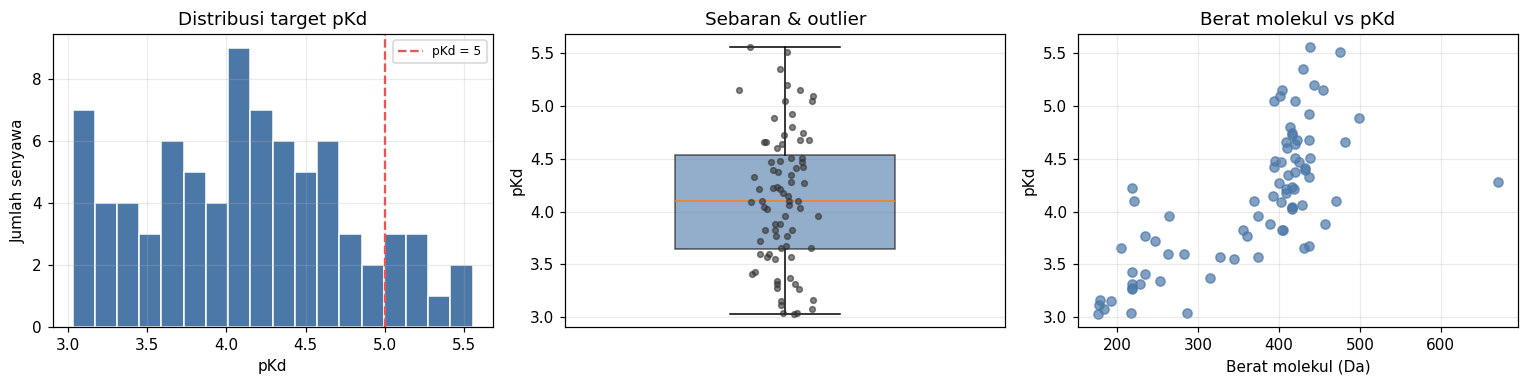

In [4]:

fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))

# Distribusi nilai pKd
ax[0].hist(y, bins=18, color="#4C78A8", edgecolor="white")
ax[0].axvline(5, ls="--", c="#E45756", lw=1.5, label="pKd = 5")
ax[0].set_xlabel("pKd")
ax[0].set_ylabel("Jumlah senyawa")
ax[0].set_title("Distribusi target pKd")
ax[0].legend(fontsize=8)

# Sebaran nilai pKd dan outlier
ax[1].boxplot(
    y, vert=True, widths=0.5, patch_artist=True,
    boxprops=dict(facecolor="#4C78A8", alpha=.6)
)
ax[1].scatter(
    np.random.normal(1, .04, len(y)),
    y, s=14, c="#333", alpha=.6, zorder=3
)
ax[1].set_ylabel("pKd")
ax[1].set_title("Sebaran & outlier")
ax[1].set_xticks([])

# Hubungan berat molekul dan pKd
mw = np.array([Descriptors.MolWt(m) for m in mols])

ax[2].scatter(mw, y, alpha=0.7, color="#4C78A8")
ax[2].set_xlabel("Berat molekul (Da)")
ax[2].set_ylabel("pKd")
ax[2].set_title("Berat molekul vs pKd")

plt.tight_layout()
plt.show()


In [5]:

# Identifikasi scaffold Bemis-Murcko
def murcko(smiles_list):
    out = []
    for s in smiles_list:
        m = Chem.MolFromSmiles(s)
        sc = MurckoScaffold.MurckoScaffoldSmiles(
            mol=m,
            includeChirality=False
        )
        out.append(sc if sc else s)
    return np.array(out)

scaf = murcko(df.canonical_smiles)
df["scaffold"] = scaf

vc = pd.Series(scaf).value_counts()

print("=== ANALISIS SCAFFOLD USP5 ===")
print(f"Jumlah scaffold unik : {len(vc)} dari {len(scaf)} senyawa")
print(f"Scaffold singleton   : {(vc == 1).sum()}")
print(f"Scaffold terbesar    : {vc.iloc[0]} senyawa")
print(f"Persentase terbesar  : {vc.iloc[0]/len(scaf)*100:.1f}%")

print("\n5 scaffold terbanyak:")
display(vc.head(5).to_frame("Jumlah senyawa"))


=== ANALISIS SCAFFOLD USP5 ===
Jumlah scaffold unik : 38 dari 80 senyawa
Scaffold singleton   : 30
Scaffold terbesar    : 23 senyawa
Persentase terbesar  : 28.7%

5 scaffold terbanyak:


,Jumlah senyawa
O=S(=O)(c1ccccc1)N1CCC(c2ccccc2)CC1,23
c1ccc(-c2nnco2)cc1,6
c1ccccc1,5
O=c1[nH]cnc2ccccc12,5
O=S(=O)(c1cccnc1)N1CCC(c2ccccc2)CC1,3



### Interpretasi Analisis Eksplorasi

Distribusi pKd menunjukkan variasi afinitas senyawa inhibitor USP5 yang digunakan sebagai target prediksi.

Analisis scaffold dilakukan untuk mengetahui keberagaman kerangka molekul pada dataset.

Informasi scaffold penting karena akan digunakan dalam dua pendekatan evaluasi:

- **Random Cross-Validation:** pembagian senyawa secara acak.
- **Scaffold Cross-Validation:** pembagian berdasarkan kerangka molekul untuk menguji kemampuan prediksi pada scaffold yang belum terlihat dalam pelatihan.

Kedua pendekatan digunakan untuk mengevaluasi kemampuan generalisasi model dari sudut pandang yang berbeda.



## 4. Featurization Molekul

Tahap ini bertujuan mengubah struktur molekul SMILES menjadi representasi numerik untuk pemodelan machine learning.

Tiga jenis fitur yang digunakan:

1. **RDKit Descriptors:** karakteristik fisikokimia dan topologi molekul.
2. **Morgan Fingerprint:** representasi pola substruktur molekul.
3. **MACCS Keys:** representasi keberadaan fragmen atau gugus struktur tertentu.

Ketiga representasi digunakan untuk membangun dan membandingkan model prediksi pKd inhibitor USP5.


In [6]:

from rdkit.Chem import rdFingerprintGenerator, MACCSkeys
from rdkit.ML.Descriptors import MoleculeDescriptors

# RDKit Descriptors
descriptor_names = [name for name, _ in Descriptors._descList]
calculator = MoleculeDescriptors.MolecularDescriptorCalculator(
    descriptor_names
)

X_desc = np.array(
    [calculator.CalcDescriptors(m) for m in mols],
    dtype=float
)

# Morgan Fingerprint (radius 2, 1024 bit)
morgan_gen = rdFingerprintGenerator.GetMorganGenerator(
    radius=2, fpSize=1024
)

X_morgan = np.array(
    [morgan_gen.GetFingerprintAsNumPy(m) for m in mols],
    dtype=float
)

# MACCS Keys
X_maccs = np.array(
    [list(MACCSkeys.GenMACCSKeys(m)) for m in mols],
    dtype=float
)

print("=== HASIL FEATURIZATION USP5 ===")
print("RDKit Descriptors:", X_desc.shape)
print("Morgan Fingerprint:", X_morgan.shape)
print("MACCS Keys:", X_maccs.shape)
print("Jumlah senyawa:", len(mols))


=== HASIL FEATURIZATION USP5 ===
RDKit Descriptors: (80, 217)
Morgan Fingerprint: (80, 1024)
MACCS Keys: (80, 167)
Jumlah senyawa: 80


In [7]:

# Gabungkan seluruh fitur molekul
X = np.hstack([X_desc, X_morgan, X_maccs])

# Jumlah fitur setiap kelompok
nD, nM = X_desc.shape[1], X_morgan.shape[1]

# Indeks kelompok fitur
IDX_DESC = np.arange(nD)
IDX_MORGAN = np.arange(nD, nD + nM)
IDX_MACCS = np.arange(nD + nM, X.shape[1])

# Kombinasi kelompok fitur
IDX_FPMA = np.concatenate([IDX_MORGAN, IDX_MACCS])
IDX_DESCFP = np.concatenate([IDX_DESC, IDX_MORGAN])

print("=== MATRIKS FITUR GABUNGAN ===")
print("Total fitur:", X.shape)
print("RDKit Descriptors:", len(IDX_DESC))
print("Morgan Fingerprint:", len(IDX_MORGAN))
print("MACCS Keys:", len(IDX_MACCS))
print("Rasio fitur:sampel:", round(X.shape[1] / X.shape[0], 1))


=== MATRIKS FITUR GABUNGAN ===
Total fitur: (80, 1408)
RDKit Descriptors: 217
Morgan Fingerprint: 1024
MACCS Keys: 167
Rasio fitur:sampel: 17.6


In [8]:

# Mengikuti representasi Morgan Count Fingerprint
# pada notebook asli Pak Ridwan

X_morgan = np.array(
    [morgan_gen.GetCountFingerprintAsNumPy(m) for m in mols],
    dtype=float
)

# Menangani nilai NaN dan Inf pada deskriptor
X_desc = np.nan_to_num(
    X_desc, nan=0.0, posinf=0.0, neginf=0.0
)

# Menggabungkan kembali seluruh fitur
X = np.hstack([X_desc, X_morgan, X_maccs])

print("=== VERIFIKASI FITUR ===")
print("Matriks gabungan:", X.shape)
print("Morgan Count maksimum:", X_morgan.max())
print("Semua fitur finite:", np.isfinite(X).all())


=== VERIFIKASI FITUR ===
Matriks gabungan: (80, 1408)
Morgan Count maksimum: 12.0
Semua fitur finite: True



## 5. Screening Model Machine Learning

Tahap ini bertujuan membandingkan beberapa algoritma machine learning untuk mengidentifikasi pendekatan yang paling sesuai dalam prediksi nilai pKd inhibitor USP5.

Perbandingan dilakukan berdasarkan:
- RMSE (Root Mean Squared Error)
- MAE (Mean Absolute Error)
- R² (Coefficient of Determination)

Pada tahap ini digunakan hasil screening yang telah tersedia dari notebook referensi. Hasil tersebut digunakan sebagai dasar pemilihan algoritma untuk model ensemble.

**Catatan:** Tabel screening merupakan hasil eksperimen referensi, bukan hasil pelatihan ulang pada notebook replikasi ini.


In [9]:

RUN_SCREENING = True

def make_pre(k=None):
    steps = [
        ("imp", SimpleImputer(strategy="median")),
        ("vt", VarianceThreshold(0.0))
    ]
    if k:
        steps.append(("sel", SelectKBest(f_regression, k=k)))
    steps.append(("sc", StandardScaler()))
    return steps

class BlockSelector(BaseEstimator, TransformerMixin):
    def __init__(self, idx):
        self.idx = idx

    def fit(self, Xm, ym=None):
        return self

    def transform(self, Xm):
        return np.asarray(Xm)[:, self.idx]

def pick(idx):
    return BlockSelector(idx)

def make_pipe(idx, model, k=None):
    return Pipeline(
        [("pick", pick(idx))] + make_pre(k) + [("m", model)]
    )

def cv_random(estimator_factory, Xm, ym,
              n_repeats=5, n_splits=5, seed0=200):
    recs, oofs = [], []

    for rep in range(n_repeats):
        cv = KFold(
            n_splits=n_splits,
            shuffle=True,
            random_state=seed0 + rep
        )

        p = np.zeros(len(ym))

        for tr, te in cv.split(Xm):
            mdl = estimator_factory()
            mdl.fit(Xm[tr], ym[tr])
            p[te] = np.ravel(mdl.predict(Xm[te]))

        recs.append({
            "rep": rep,
            "RMSE": np.sqrt(mean_squared_error(ym, p)),
            "MAE": mean_absolute_error(ym, p),
            "R2": r2_score(ym, p)
        })
        oofs.append(p)

    return pd.DataFrame(recs), np.mean(oofs, axis=0)

print("Fungsi evaluasi siap.")
print("RUN_SCREENING =", RUN_SCREENING)


Fungsi evaluasi siap.
RUN_SCREENING = True



### 5.1 Persiapan Screening Algoritma Machine Learning

Screening dilakukan untuk membandingkan 13 algoritma machine learning menggunakan dataset 80 senyawa inhibitor USP5.

Eksperimen menguji beberapa kombinasi fitur molekul dan seleksi fitur dengan repeated 5-fold cross-validation.

Hasil evaluasi berupa R², RMSE, dan MAE digunakan untuk menentukan algoritma yang paling menjanjikan.


In [10]:

import importlib.util

libraries = {
    "scikit-learn": "sklearn",
    "XGBoost": "xgboost",
    "LightGBM": "lightgbm"
}

print("=== PERSIAPAN SCREENING 13 ALGORITMA ===")

for name, module in libraries.items():
    status = "TERSEDIA" if importlib.util.find_spec(module) else "BELUM TERSEDIA"
    print(f"{name}: {status}")

print("\nDataset:", X.shape)
print("Target:", y.shape)
print("RUN_SCREENING:", RUN_SCREENING)


=== PERSIAPAN SCREENING 13 ALGORITMA ===
scikit-learn: TERSEDIA
XGBoost: TERSEDIA
LightGBM: TERSEDIA

Dataset: (80, 1408)
Target: (80,)
RUN_SCREENING: True



### 5.2 Screening 13 Algoritma Machine Learning

Pada tahap ini dilakukan pengujian awal terhadap 13 algoritma machine learning menggunakan 80 senyawa inhibitor USP5.

Representasi molekul yang digunakan adalah kombinasi RDKit Descriptors, Morgan Count Fingerprint, dan MACCS Keys.

Screening dilakukan menggunakan Random 5-Fold Cross-Validation dengan seed 200.

Evaluasi dilakukan berdasarkan:
- R²: kemampuan model menjelaskan variasi nilai pKd.
- RMSE: besarnya kesalahan prediksi.
- MAE: rata-rata kesalahan absolut prediksi.

Seluruh preprocessing dilakukan di dalam pipeline cross-validation untuk menghindari data leakage.

Hasil screening digunakan untuk mengidentifikasi kandidat algoritma yang akan dievaluasi lebih lanjut.

**Catatan:** Screening ini merupakan eksperimen mandiri dengan konfigurasi awal, bukan reproduksi identik seluruh screening historis Pak Ridwan.


In [11]:

import time
import warnings
import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

from sklearn.linear_model import BayesianRidge, Ridge, ElasticNet
from sklearn.cross_decomposition import PLSRegression
from sklearn.ensemble import ExtraTreesRegressor, GradientBoostingRegressor, RandomForestRegressor
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.kernel_ridge import KernelRidge

from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

warnings.filterwarnings("ignore", category=FutureWarning)

SEED_SCREEN = 200

MODELS = {
    "Bayesian Ridge": BayesianRidge(),
    "PLS Regression": PLSRegression(n_components=6),
    "Ridge": Ridge(alpha=10.0),
    "Extra Trees": ExtraTreesRegressor(
        n_estimators=200, random_state=42, n_jobs=1
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        random_state=42
    ),
    "XGBoost": XGBRegressor(
        n_estimators=200, max_depth=3,
        learning_rate=0.05, random_state=42,
        n_jobs=1
    ),
    "Random Forest": RandomForestRegressor(
        n_estimators=200, random_state=42, n_jobs=1
    ),
    "Elastic Net": ElasticNet(
        alpha=0.1, l1_ratio=0.5, max_iter=10000
    ),
    "LightGBM": LGBMRegressor(
        n_estimators=200, learning_rate=0.05,
        num_leaves=7, min_child_samples=5,
        random_state=42, n_jobs=1, verbosity=-1
    ),
    "Gaussian Process": GaussianProcessRegressor(
        alpha=0.1, normalize_y=True
    ),
    "SVR RBF": SVR(kernel="rbf", C=10.0),
    "KNN": KNeighborsRegressor(n_neighbors=5),
    "Kernel Ridge": KernelRidge(
        alpha=1.0, kernel="rbf", gamma=0.001
    )
}

# Dua kombinasi fitur untuk screening awal
FEATURE_BLOCKS = {
    "Morgan+MACCS": X[:, IDX_FPMA],
    "DESC+Morgan": X[:, IDX_DESCFP]
}

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED_SCREEN
)

records = []

print("=== SCREENING 13 ALGORITMA ===")
print("Jumlah algoritma:", len(MODELS))
print("Jumlah kombinasi fitur:", len(FEATURE_BLOCKS))

for block_name, X_block in FEATURE_BLOCKS.items():

    for name, estimator in MODELS.items():

        start = time.time()

        pipe = Pipeline([
            ("imputer", SimpleImputer(
                strategy="median", keep_empty_features=True
            )),
            ("variance", VarianceThreshold()),
            ("scaler", StandardScaler()),
            ("model", clone(estimator))
        ])

        try:
            y_pred = cross_val_predict(
                pipe, X_block, y, cv=cv, n_jobs=1
            ).reshape(-1)

            r2 = r2_score(y, y_pred)
            rmse = np.sqrt(mean_squared_error(y, y_pred))
            mae = mean_absolute_error(y, y_pred)

            records.append({
                "Algoritma": name,
                "Fitur": block_name,
                "R2": r2,
                "RMSE": rmse,
                "MAE": mae,
                "Status": "Berhasil"
            })

            print(
                f"{name:22s} | {block_name:13s} | "
                f"R2={r2:.4f} | RMSE={rmse:.4f}"
            )

        except Exception as e:
            records.append({
                "Algoritma": name,
                "Fitur": block_name,
                "R2": np.nan,
                "RMSE": np.nan,
                "MAE": np.nan,
                "Status": str(e)[:150]
            })
            print(f"{name}: ERROR - {str(e)[:100]}")

screening_results = pd.DataFrame(records)

screening_ranking = (
    screening_results
    .query("Status == 'Berhasil'")
    .sort_values("RMSE")
    .reset_index(drop=True)
)

print("\n=== HASIL SCREENING ===")
display(screening_ranking)

print("\n=== STATUS ===")
print("Total pengujian:", len(screening_results))
print("Berhasil:", len(screening_ranking))


=== SCREENING 13 ALGORITMA ===
Jumlah algoritma: 13
Jumlah kombinasi fitur: 2
Bayesian Ridge         | Morgan+MACCS  | R2=0.7525 | RMSE=0.3151
PLS Regression         | Morgan+MACCS  | R2=0.7548 | RMSE=0.3136
Ridge                  | Morgan+MACCS  | R2=0.7729 | RMSE=0.3018
Extra Trees            | Morgan+MACCS  | R2=0.6678 | RMSE=0.3651
Gradient Boosting      | Morgan+MACCS  | R2=0.7179 | RMSE=0.3364
XGBoost                | Morgan+MACCS  | R2=0.7264 | RMSE=0.3313
Random Forest          | Morgan+MACCS  | R2=0.7183 | RMSE=0.3362
Elastic Net            | Morgan+MACCS  | R2=0.6920 | RMSE=0.3515
LightGBM               | Morgan+MACCS  | R2=0.6494 | RMSE=0.3750
Gaussian Process       | Morgan+MACCS  | R2=-0.0231 | RMSE=0.6406
SVR RBF                | Morgan+MACCS  | R2=0.6141 | RMSE=0.3935
KNN                    | Morgan+MACCS  | R2=0.3674 | RMSE=0.5038
Kernel Ridge           | Morgan+MACCS  | R2=-1.0963 | RMSE=0.9170
Bayesian Ridge         | DESC+Morgan   | R2=0.6349 | RMSE=0.3827
PLS Regres

,Algoritma,Fitur,R2,RMSE,MAE,Status
0,Ridge,Morgan+MACCS,0.772937,0.301800,0.229367,Berhasil
1,PLS Regression,Morgan+MACCS,0.754819,0.313610,0.236685,Berhasil
2,Bayesian Ridge,Morgan+MACCS,0.752533,0.315068,0.238885,Berhasil
3,XGBoost,Morgan+MACCS,0.726397,0.331289,0.251869,Berhasil
4,Random Forest,Morgan+MACCS,0.718278,0.336168,0.261602,Berhasil
5,Gradient Boosting,Morgan+MACCS,0.717865,0.336414,0.258639,Berhasil
6,Extra Trees,DESC+Morgan,0.700561,0.346577,0.256369,Berhasil
7,Elastic Net,Morgan+MACCS,0.692008,0.351492,0.281785,Berhasil
8,Random Forest,DESC+Morgan,0.678027,0.359381,0.270719,Berhasil
9,Extra Trees,Morgan+MACCS,0.667779,0.365056,0.270158,Berhasil



=== STATUS ===
Total pengujian: 26
Berhasil: 26



### 5.3 Hasil dan Interpretasi Screening Algoritma

Screening awal dilakukan terhadap **13 algoritma machine learning** dengan dua kombinasi fitur, yaitu Morgan Fingerprint + MACCS Keys dan RDKit Descriptors + Morgan Fingerprint, sehingga menghasilkan **26 pengujian**.

Seluruh pengujian berhasil dijalankan menggunakan **Random 5-Fold Cross-Validation (seed 200)**.

#### Lima hasil screening terbaik

| Peringkat | Algoritma | Kombinasi Fitur | R² | RMSE | MAE |
|---|---|---|---:|---:|---:|
| 1 | Ridge | Morgan + MACCS | 0,7729 | 0,3018 | 0,2294 |
| 2 | PLS Regression | Morgan + MACCS | 0,7548 | 0,3136 | 0,2367 |
| 3 | Bayesian Ridge | Morgan + MACCS | 0,7525 | 0,3151 | 0,2389 |
| 4 | XGBoost | Morgan + MACCS | 0,7264 | 0,3313 | 0,2519 |
| 5 | Random Forest | Morgan + MACCS | 0,7183 | 0,3362 | 0,2616 |

#### Interpretasi

1. **Ridge Regression** menghasilkan performa terbaik pada screening awal, dengan R² sebesar 0,7729 dan RMSE sebesar 0,3018.
2. **Morgan Fingerprint + MACCS Keys** menjadi kombinasi fitur yang paling banyak menghasilkan performa tinggi.
3. Algoritma linear, khususnya Ridge, PLS Regression, dan Bayesian Ridge, menunjukkan hasil lebih baik dibandingkan sebagian besar algoritma non-linear pada pengaturan yang diuji.
4. Hasil screening berbeda dari referensi Pak Ridwan karena konfigurasi hyperparameter, kombinasi fitur, seleksi fitur, dan prosedur cross-validation tidak sepenuhnya sama.
5. Nilai R² screening belum dapat dinyatakan sebagai performa akhir model karena masih memerlukan evaluasi lanjutan dan pemeriksaan kemampuan generalisasi.

#### Kesimpulan Sementara

Berdasarkan screening awal pada dataset 80 senyawa inhibitor USP5, **Ridge Regression dengan Morgan Fingerprint + MACCS Keys menjadi kandidat model paling menjanjikan**.

Tahap berikutnya adalah mengevaluasi kandidat model secara lebih menyeluruh menggunakan repeated random cross-validation dan scaffold cross-validation, kemudian membandingkannya dengan pendekatan ML Descriptor Ensemble dari notebook referensi.



### 5.4 Perbandingan Performa Screening dengan Model Referensi

Tahap ini membandingkan hasil screening 13 algoritma machine learning pada dataset 80 senyawa USP5 dengan hasil screening referensi Pak Ridwan.

**Tujuan:**
1. Membandingkan nilai R², RMSE, dan MAE.
2. Mengidentifikasi algoritma dengan performa tertinggi.
3. Menganalisis perbedaan hasil pada dataset yang sama.

**Catatan metodologi:** Kedua eksperimen menggunakan dataset yang sama, tetapi berbeda dalam kombinasi fitur, hyperparameter, seleksi fitur, dan jumlah pengulangan cross-validation. Oleh karena itu, perbandingan ini bersifat deskriptif dan belum membuktikan keunggulan model secara langsung.


In [12]:

import pandas as pd

# Hasil screening referensi Pak Ridwan
SCREENING_SUMMARY = pd.DataFrame([
    ("BayesianRidge", "MORGAN+MACCS", 0.3297, 0.2456, 0.7262),
    ("PLS (6 komponen)", "MORGAN+MACCS", 0.3309, 0.2437, 0.7249),
    ("RidgeCV", "MORGAN+MACCS", 0.3321, 0.2463, 0.7223),
    ("ExtraTrees", "DESC+MORGAN", 0.3365, 0.2536, 0.7167),
    ("GradientBoosting", "DESC+MORGAN", 0.3509, 0.2610, 0.6926),
    ("XGBoost", "MORGAN+MACCS", 0.3509, 0.2600, 0.6912),
    ("RandomForest", "DESC+MORGAN", 0.3554, 0.2757, 0.6847),
    ("ElasticNet", "MORGAN+MACCS", 0.3544, 0.2700, 0.6834),
    ("LightGBM", "DESC+MORGAN", 0.3596, 0.2740, 0.6772),
    ("GaussianProcess RBF", "DESC+MORGAN", 0.3590, 0.2595, 0.6766),
    ("SVR RBF", "DESC+MORGAN", 0.3680, 0.2740, 0.6605),
    ("kNN (k=5)", "DESC+MORGAN", 0.3793, 0.2884, 0.6391),
    ("KernelRidge RBF", "MORGAN+MACCS", 0.7451, 0.4693, -0.3850)
], columns=["Algoritma", "Fitur", "RMSE", "MAE", "R²"])

print("=== REFERENSI SCREENING PAK RIDWAN ===")
display(SCREENING_SUMMARY)


=== REFERENSI SCREENING PAK RIDWAN ===


,Algoritma,Fitur,RMSE,MAE,R²
0,BayesianRidge,MORGAN+MACCS,0.3297,0.2456,0.7262
1,PLS (6 komponen),MORGAN+MACCS,0.3309,0.2437,0.7249
2,RidgeCV,MORGAN+MACCS,0.3321,0.2463,0.7223
3,ExtraTrees,DESC+MORGAN,0.3365,0.2536,0.7167
4,GradientBoosting,DESC+MORGAN,0.3509,0.2610,0.6926
5,XGBoost,MORGAN+MACCS,0.3509,0.2600,0.6912
6,RandomForest,DESC+MORGAN,0.3554,0.2757,0.6847
7,ElasticNet,MORGAN+MACCS,0.3544,0.2700,0.6834
8,LightGBM,DESC+MORGAN,0.3596,0.2740,0.6772
9,GaussianProcess RBF,DESC+MORGAN,0.3590,0.2595,0.6766


In [13]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Hasil screening eksperimen sendiri
hasil_saya = (
    screening_results[
        screening_results["Status"] == "Berhasil"
    ]
    .sort_values("RMSE")
    .drop_duplicates("Algoritma")
    .copy()
)

# Hasil screening referensi Pak Ridwan
hasil_pak = SCREENING_SUMMARY.copy()

# Samakan nama algoritma untuk perbandingan
nama_model = {
    "BayesianRidge": "Bayesian Ridge",
    "PLS (6 komponen)": "PLS Regression",
    "ExtraTrees": "Extra Trees",
    "GradientBoosting": "Gradient Boosting",
    "RandomForest": "Random Forest",
    "ElasticNet": "Elastic Net",
    "SVR RBF": "SVR RBF",
    "LightGBM": "LightGBM",
    "XGBoost": "XGBoost",
    "kNN (k=5)": "KNN",
    "KernelRidge RBF": "Kernel Ridge"
}

hasil_pak["Algoritma"] = hasil_pak["Algoritma"].replace(nama_model)

# Gabungkan hasil pada algoritma yang namanya sepadan
perbandingan = pd.merge(
    hasil_pak[["Algoritma", "R²", "RMSE", "MAE"]],
    hasil_saya[["Algoritma", "R2", "RMSE", "MAE", "Fitur"]],
    on="Algoritma",
    suffixes=("_Pak", "_Saya")
)

perbandingan = perbandingan.rename(columns={
    "R²": "R2_Pak",
    "R2": "R2_Saya"
})

perbandingan["Selisih_R2"] = (
    perbandingan["R2_Saya"] - perbandingan["R2_Pak"]
)

perbandingan = perbandingan.sort_values(
    "R2_Saya", ascending=False
).reset_index(drop=True)

print("=== PERBANDINGAN SCREENING USP5 80 SENYAWA ===")
display(perbandingan.round(4))

print("\n=== MODEL TERBAIK MASING-MASING ===")
print(
    "Pak Ridwan:",
    SCREENING_SUMMARY.loc[
        SCREENING_SUMMARY["R²"].idxmax(), "Algoritma"
    ]
)

terbaik_saya = screening_ranking.iloc[0]
print(
    "Eksperimen saya:",
    terbaik_saya["Algoritma"],
    "| R² =", round(terbaik_saya["R2"], 4)
)


=== PERBANDINGAN SCREENING USP5 80 SENYAWA ===


,Algoritma,R2_Pak,RMSE_Pak,MAE_Pak,R2_Saya,RMSE_Saya,MAE_Saya,Fitur,Selisih_R2
0,PLS Regression,0.7249,0.3309,0.2437,0.7548,0.3136,0.2367,Morgan+MACCS,0.0299
1,Bayesian Ridge,0.7262,0.3297,0.2456,0.7525,0.3151,0.2389,Morgan+MACCS,0.0263
2,XGBoost,0.6912,0.3509,0.2600,0.7264,0.3313,0.2519,Morgan+MACCS,0.0352
3,Random Forest,0.6847,0.3554,0.2757,0.7183,0.3362,0.2616,Morgan+MACCS,0.0336
4,Gradient Boosting,0.6926,0.3509,0.2610,0.7179,0.3364,0.2586,Morgan+MACCS,0.0253
5,Extra Trees,0.7167,0.3365,0.2536,0.7006,0.3466,0.2564,DESC+Morgan,-0.0161
6,Elastic Net,0.6834,0.3544,0.2700,0.6920,0.3515,0.2818,Morgan+MACCS,0.0086
7,LightGBM,0.6772,0.3596,0.2740,0.6494,0.3750,0.2816,Morgan+MACCS,-0.0278
8,SVR RBF,0.6605,0.3680,0.2740,0.6141,0.3935,0.3018,Morgan+MACCS,-0.0464
9,KNN,0.6391,0.3793,0.2884,0.5568,0.4217,0.3421,DESC+Morgan,-0.0823



=== MODEL TERBAIK MASING-MASING ===
Pak Ridwan: BayesianRidge
Eksperimen saya: Ridge | R² = 0.7729



## 6. Pembentukan dan Evaluasi ML Ensemble

Tahap ini bertujuan membangun model ensemble berdasarkan hasil screening 13 algoritma machine learning pada dataset 80 senyawa inhibitor USP5.

### Model yang dibandingkan

1. **Ridge Regression:** model tunggal dengan performa screening tertinggi.
2. **Ensemble A:** kombinasi Ridge, PLS Regression, dan Bayesian Ridge.
3. **Ensemble B:** kombinasi Ridge, Bayesian Ridge, dan XGBoost.

Prediksi ensemble dihitung menggunakan rata-rata prediksi dari ketiga anggota model (*equal-weight averaging*).

### Mengapa dilakukan ensemble?

Ensemble bertujuan menggabungkan kemampuan beberapa algoritma untuk mengurangi kesalahan prediksi. Namun, penggabungan tidak selalu meningkatkan performa, terutama apabila model anggotanya menghasilkan kesalahan yang serupa.

### Metode evaluasi

- Repeated Random 5-Fold Cross-Validation (4 pengulangan).
- Scaffold 5-Fold Cross-Validation.
- Evaluasi menggunakan R², RMSE, dan MAE.

Seluruh model menggunakan kombinasi Morgan Count Fingerprint dan MACCS Keys. Preprocessing dilakukan hanya berdasarkan data training pada setiap fold untuk menghindari kebocoran data.

**Catatan:** Konfigurasi model didasarkan pada screening mandiri. Tahap ini mengikuti alur pemodelan ensemble dari notebook referensi, tetapi menggunakan anggota ensemble hasil eksplorasi sendiri.


In [14]:

import numpy as np
import pandas as pd
from pathlib import Path

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold, GroupKFold
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.linear_model import Ridge, BayesianRidge
from sklearn.cross_decomposition import PLSRegression
from xgboost import XGBRegressor

# Menggunakan fitur hasil screening
X_model = np.asarray(X[:, IDX_FPMA], dtype=float)
y_model = np.asarray(y, dtype=float)

# Scaffold dari tahap eksplorasi
scaffold_groups = np.asarray(df["scaffold"])

assert X_model.shape == (80, 1191)
assert len(y_model) == len(scaffold_groups) == 80
assert np.isfinite(X_model).all()
assert np.isfinite(y_model).all()

# Hyperparameter sesuai screening mandiri sebelumnya
def build_model(name):
    models = {
        "Ridge": Ridge(alpha=10.0),
        "PLS": PLSRegression(n_components=6),
        "Bayesian Ridge": BayesianRidge(),
        "XGBoost": XGBRegressor(
            n_estimators=200,
            max_depth=3,
            learning_rate=0.05,
            random_state=42,
            n_jobs=1
        )
    }

    return Pipeline([
        ("imputer", SimpleImputer(
            strategy="median",
            keep_empty_features=True
        )),
        ("variance", VarianceThreshold()),
        ("scaler", StandardScaler()),
        ("model", clone(models[name]))
    ])

EXPERIMENTS = {
    "Ridge Tunggal": ["Ridge"],
    "Ensemble A": ["Ridge", "PLS", "Bayesian Ridge"],
    "Ensemble B": ["Ridge", "Bayesian Ridge", "XGBoost"]
}

OUT = Path("/data/Aliya/model/Hasil_Ensemble_80")
OUT.mkdir(parents=True, exist_ok=True)

print("=== PERSIAPAN ENSEMBLE ===")
print("Jumlah senyawa:", len(y_model))
print("Jumlah fitur:", X_model.shape[1])
print("Scaffold unik:", len(np.unique(scaffold_groups)))
print("Model:", list(EXPERIMENTS))
print("Folder hasil:", OUT)


=== PERSIAPAN ENSEMBLE ===
Jumlah senyawa: 80
Jumlah fitur: 1191
Scaffold unik: 38
Model: ['Ridge Tunggal', 'Ensemble A', 'Ensemble B']
Folder hasil: /data/Aliya/model/Hasil_Ensemble_80


In [15]:

def predict_members(names, tr, te):
    predictions = []

    for name in names:
        model = build_model(name)
        model.fit(X_model[tr], y_model[tr])

        pred = np.asarray(
            model.predict(X_model[te])
        ).reshape(-1)

        predictions.append(pred)

    # Equal-weight averaging
    return np.mean(predictions, axis=0)


def evaluate_ensemble(protocol, seed):
    if protocol == "random":
        splitter = KFold(
            n_splits=5,
            shuffle=True,
            random_state=seed
        )
        splits = list(splitter.split(X_model))

    else:
        splitter = GroupKFold(n_splits=5)
        splits = list(splitter.split(
            X_model, y_model, scaffold_groups
        ))

    records = []
    preds = []

    for model_name, members in EXPERIMENTS.items():
        oof = np.full(len(y_model), np.nan)

        for fold, (tr, te) in enumerate(splits, 1):
            oof[te] = predict_members(members, tr, te)

        assert np.isfinite(oof).all()

        records.append({
            "Model": model_name,
            "Protokol": protocol,
            "Seed": seed if protocol == "random" else np.nan,
            "R2": r2_score(y_model, oof),
            "RMSE": np.sqrt(mean_squared_error(y_model, oof)),
            "MAE": mean_absolute_error(y_model, oof)
        })

        preds.append(pd.DataFrame({
            "Model": model_name,
            "Protokol": protocol,
            "Seed": seed if protocol == "random" else np.nan,
            "chembl_id": df["chembl_id"],
            "pKd_eksperimen": y_model,
            "pKd_prediksi": oof
        }))

    return records, preds


all_scores = []
all_preds = []

# Empat pengulangan random 5-fold CV
for seed in [200, 201, 202, 203]:
    scores, preds = evaluate_ensemble("random", seed)
    all_scores.extend(scores)
    all_preds.extend(preds)
    print("Random CV seed", seed, "selesai")

# Scaffold CV: satu pembagian GroupKFold
scores, preds = evaluate_ensemble("scaffold", 42)
all_scores.extend(scores)
all_preds.extend(preds)
print("Scaffold CV selesai")

scores_df = pd.DataFrame(all_scores)
preds_df = pd.concat(all_preds, ignore_index=True)

summary = (
    scores_df
    .groupby(["Protokol", "Model"])[["R2", "RMSE", "MAE"]]
    .agg(["mean", "std"])
    .round(4)
)

display(summary)

scores_df.to_csv(OUT / "hasil_per_evaluasi.csv", index=False)
preds_df.to_csv(OUT / "prediksi_per_senyawa.csv", index=False)
summary.to_csv(OUT / "ringkasan_ensemble.csv")

print("Hasil tersimpan di:", OUT)


Random CV seed 200 selesai
Random CV seed 201 selesai
Random CV seed 202 selesai
Random CV seed 203 selesai
Scaffold CV selesai


R2            RMSE             MAE        
                          mean     std    mean     std    mean     std
Protokol Model                                                        
random   Ensemble A     0.7622  0.0076  0.3088  0.0049  0.2338  0.0078
         Ensemble B     0.7676  0.0050  0.3053  0.0033  0.2308  0.0012
         Ridge Tunggal  0.7625  0.0139  0.3086  0.0089  0.2341  0.0127
scaffold Ensemble A     0.5890     NaN  0.4061     NaN  0.2868     NaN
         Ensemble B     0.5881     NaN  0.4065     NaN  0.2973     NaN
         Ridge Tunggal  0.5945     NaN  0.4033     NaN  0.2866     NaN

Hasil tersimpan di: /data/Aliya/model/Hasil_Ensemble_80



### 6.1 Hasil dan Interpretasi Evaluasi ML Ensemble

Evaluasi dilakukan pada **80 senyawa inhibitor USP5** menggunakan tiga kandidat model, yaitu Ridge Tunggal, Ensemble A (Ridge + PLS + Bayesian Ridge), dan Ensemble B (Ridge + Bayesian Ridge + XGBoost).

Pengujian menggunakan **Repeated Random 5-Fold CV (4 pengulangan)** dan **Scaffold 5-Fold CV**.

#### Hasil Evaluasi

| Model | R² Random CV | RMSE Random | R² Scaffold CV | RMSE Scaffold |
|---|---:|---:|---:|---:|
| Ridge Tunggal | 0,7625 | 0,3086 | **0,5945** | **0,4033** |
| Ensemble A | 0,7622 | 0,3088 | 0,5890 | 0,4061 |
| Ensemble B | **0,7676** | **0,3053** | 0,5881 | 0,4065 |

#### Interpretasi Hasil

1. **Penurunan R² Ridge dari 0,7729 menjadi 0,7625** terjadi karena evaluasi awal hanya menggunakan satu pembagian 5-fold CV (seed 200), sedangkan evaluasi lanjutan menggunakan empat seed (200–203). Rata-rata beberapa pengulangan memberikan gambaran variasi performa yang lebih baik.

2. **Ensemble B menghasilkan R² Random CV tertinggi (0,7676)**, menunjukkan bahwa penggabungan model linear dan non-linear sedikit meningkatkan performa dibandingkan Ridge Tunggal (0,7625).

3. **Ridge Tunggal menghasilkan R² Scaffold CV tertinggi (0,5945)**, sehingga menunjukkan performa paling baik di antara ketiga kandidat ketika evaluasi dilakukan pada scaffold yang tidak muncul dalam data training.

4. **Ensemble A belum memberikan peningkatan performa** dibandingkan Ridge Tunggal. Hal ini menunjukkan bahwa menggabungkan beberapa model linear tidak selalu menghasilkan prediksi yang lebih baik.

5. Perbedaan R² antar-model relatif kecil, sehingga belum cukup untuk menyimpulkan keunggulan salah satu model secara signifikan.

#### Kesimpulan Sementara

Berdasarkan evaluasi lanjutan, **Ensemble B unggul pada Random CV**, sedangkan **Ridge Tunggal unggul pada Scaffold CV**.

Dengan demikian, kedua model dipertahankan sebagai kandidat untuk analisis berikutnya. Pembentukan ensemble belum menunjukkan peningkatan performa yang konsisten dibandingkan penggunaan Ridge Tunggal.

Seluruh hasil masih merupakan estimasi cross-validation internal, bukan hasil pengujian eksternal independen.



## 7. Evaluasi Model Menggunakan Repeated 5-Fold Cross-Validation

Tahap ini bertujuan mengevaluasi kestabilan performa model machine learning dalam memprediksi nilai pKd inhibitor USP5.

### Mengapa cross-validation diulang?

Hasil prediksi dapat berubah ketika pembagian data training dan validasi berbeda. Oleh karena itu, 5-fold cross-validation diulang sebanyak lima kali menggunakan seed 200–204.

Pengulangan bertujuan untuk:
1. Menilai konsistensi performa model.
2. Mengurangi ketergantungan hasil terhadap satu pembagian dataset.
3. Membandingkan Ridge Tunggal, Ensemble A, dan Ensemble B menggunakan pembagian data yang sama.

### Parameter evaluasi

- Dataset: 80 senyawa USP5.
- Jumlah fold: 5.
- Jumlah pengulangan: 5.
- Random seed: 200, 201, 202, 203, 204.
- Metrik evaluasi: R², RMSE, dan MAE.

Nilai rata-rata menunjukkan performa keseluruhan, sedangkan standar deviasi menggambarkan variasi hasil antar-pengulangan.

**Catatan:** Evaluasi ini merupakan validasi internal dan belum termasuk pengujian eksternal independen.


In [16]:

# Melanjutkan repeated CV dari Tahap 6
# Seed 200-203 sudah dievaluasi sebelumnya

assert "scores_df" in globals(), "Jalankan Tahap 6 terlebih dahulu"
assert "preds_df" in globals(), "Data prediksi Tahap 6 belum tersedia"

# Evaluasi seed kelima
if not (
    (scores_df["Protokol"] == "random") &
    (scores_df["Seed"] == 204)
).any():
    skor_baru, pred_baru = evaluate_ensemble("random", 204)

    scores_df = pd.concat(
        [scores_df, pd.DataFrame(skor_baru)],
        ignore_index=True
    )

    preds_df = pd.concat(
        [preds_df, *pred_baru],
        ignore_index=True
    )

    print("Random CV seed 204 selesai")
else:
    print("Seed 204 sudah tersedia, tidak dijalankan ulang")

# Ringkasan seluruh lima pengulangan
random_scores = scores_df[
    (scores_df["Protokol"] == "random") &
    (scores_df["Seed"].isin([200, 201, 202, 203, 204]))
].copy()

assert len(random_scores) == 15, "Hasil 5 seed belum lengkap"

ringkasan_cv = (
    random_scores.groupby("Model")[["R2", "RMSE", "MAE"]]
    .agg(["mean", "std"])
    .round(4)
)

print("=== HASIL REPEATED 5-FOLD CV ===")
display(ringkasan_cv)

random_scores.to_csv(
    OUT / "Repeated_CV_5Seed.csv", index=False
)

ringkasan_cv.to_csv(
    OUT / "Ringkasan_Repeated_CV.csv"
)

preds_df.to_csv(
    OUT / "prediksi_per_senyawa.csv", index=False
)

print("Hasil tersimpan di:", OUT)


Random CV seed 204 selesai
=== HASIL REPEATED 5-FOLD CV ===


R2            RMSE             MAE        
                 mean     std    mean     std    mean     std
Model                                                        
Ensemble A     0.7497  0.0287  0.3165  0.0176  0.2403  0.0160
Ensemble B     0.7578  0.0223  0.3115  0.0140  0.2358  0.0113
Ridge Tunggal  0.7486  0.0334  0.3171  0.0205  0.2416  0.0199

Hasil tersimpan di: /data/Aliya/model/Hasil_Ensemble_80


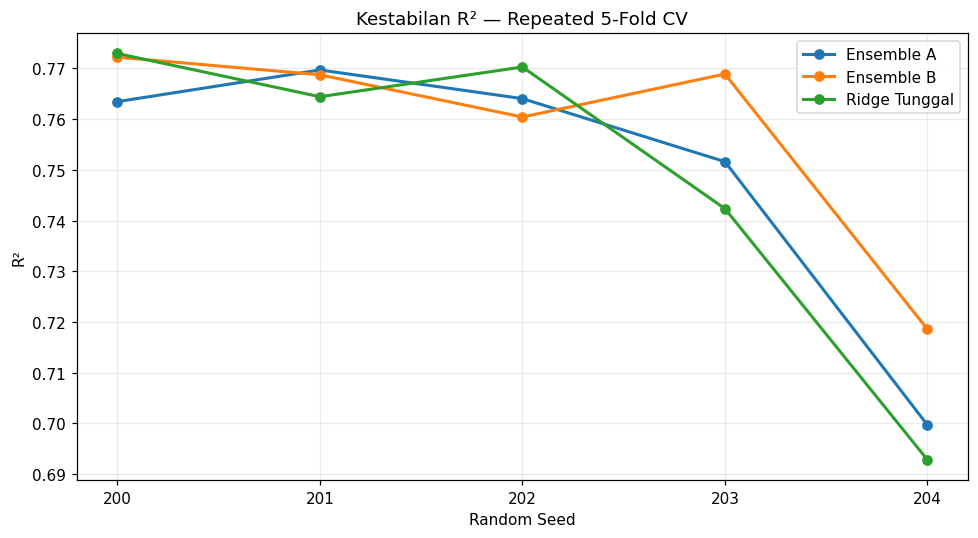

In [17]:

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 5))

for model_name, group in random_scores.groupby("Model"):
    group = group.sort_values("Seed")

    ax.plot(
        group["Seed"],
        group["R2"],
        marker="o",
        linewidth=2,
        label=model_name
    )

ax.set_title("Kestabilan R² — Repeated 5-Fold CV")
ax.set_xlabel("Random Seed")
ax.set_ylabel("R²")
ax.set_xticks([200, 201, 202, 203, 204])
ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()
plt.savefig(
    OUT / "Grafik_Kestabilan_R2.png",
    dpi=200
)
plt.show()


In [18]:

# Analisis kesalahan prediksi pada setiap seed
diagnostik = preds_df[
    preds_df["Protokol"] == "random"
].copy()

diagnostik["error_abs"] = abs(
    diagnostik["pKd_eksperimen"] -
    diagnostik["pKd_prediksi"]
)

# Ringkasan kesalahan berdasarkan model dan seed
ringkasan_error = (
    diagnostik
    .groupby(["Model", "Seed"])
    .agg(
        MAE=("error_abs", "mean"),
        Error_Maksimum=("error_abs", "max"),
        Jumlah_Error_Besar=("error_abs",
                            lambda x: (x > 0.5).sum())
    )
    .round(4)
)

print("=== PERBANDINGAN ERROR PER SEED ===")
display(ringkasan_error)

# Fokus pada Ensemble B seed 204
error_204 = diagnostik[
    (diagnostik["Model"] == "Ensemble B") &
    (diagnostik["Seed"] == 204)
].sort_values("error_abs", ascending=False)

print("\n=== 10 SENYAWA DENGAN ERROR TERBESAR ===")
display(error_204.head(10))


=== PERBANDINGAN ERROR PER SEED ===


MAE  Error_Maksimum  Jumlah_Error_Besar
Model         Seed                                             
Ensemble A    200.0  0.2339          0.9788                   9
              201.0  0.2303          1.0310                   8
              202.0  0.2264          1.1207                   9
              203.0  0.2445          1.0471                   7
              204.0  0.2663          1.1187                  13
Ensemble B    200.0  0.2295          1.0689                   9
              201.0  0.2309          1.1578                   8
              202.0  0.2305          1.2244                   9
              203.0  0.2322          1.1195                   7
              204.0  0.2560          1.2082                  12
Ridge Tunggal 200.0  0.2294          1.0081                   7
              201.0  0.2331          1.1091                   8
              202.0  0.2221          1.1623                   9
              203.0  0.2519          1.0770                   9
              204.0  0.2713          1.1354                  14


=== 10 SENYAWA DENGAN ERROR TERBESAR ===


,Model,Protokol,Seed,chembl_id,pKd_eksperimen,pKd_prediksi,error_abs
1382,Ensemble B,random,204.0,CHEMBL5286558,3.677781,4.885954,1.208174
1433,Ensemble B,random,204.0,CHEMBL5273203,5.096910,4.310818,0.786092
1405,Ensemble B,random,204.0,CHEMBL4537770,4.221849,3.525168,0.696681
1386,Ensemble B,random,204.0,CHEMBL5276984,3.823909,4.508508,0.684599
1432,Ensemble B,random,204.0,CHEMBL5267112,5.045757,4.374582,0.671175
1399,Ensemble B,random,204.0,CHEMBL4440506,4.096910,3.475936,0.620974
1437,Ensemble B,random,204.0,CHEMBL5410606,5.346787,4.728588,0.618199
1439,Ensemble B,random,204.0,CHEMBL5278336,5.552842,4.943248,0.609594
1381,Ensemble B,random,204.0,CHEMBL5274321,3.657577,4.230537,0.572960
1420,Ensemble B,random,204.0,CHEMBL5268432,4.602060,4.071031,0.531029



## 7. Hasil dan Analisis Repeated 5-Fold Cross-Validation

### 7.1 Tujuan Evaluasi

Repeated 5-Fold Cross-Validation dilakukan untuk mengevaluasi performa dan kestabilan model dalam memprediksi nilai pKd pada dataset 80 senyawa inhibitor USP5.

Pengujian dilakukan menggunakan lima pengulangan dengan random seed 200, 201, 202, 203, dan 204.

Setiap pengulangan membagi dataset menjadi lima fold. Model dilatih pada empat fold dan divalidasi pada satu fold secara bergantian, sehingga seluruh senyawa memperoleh prediksi out-of-fold (OOF).

Tiga model yang dievaluasi:

1. **Ridge Tunggal:** Ridge Regression.
2. **Ensemble A:** Ridge + PLS Regression + Bayesian Ridge.
3. **Ensemble B:** Ridge + Bayesian Ridge + XGBoost.

Pengujian ini bertujuan mengetahui apakah performa model tetap konsisten ketika pembagian data training dan validasi berubah.

---

### 7.2 Hasil Repeated 5-Fold Cross-Validation

| Model | R² (Mean ± SD) | RMSE (Mean ± SD) | MAE (Mean ± SD) |
|---|---|---|---|
| Ridge Tunggal | 0,7486 ± 0,0334 | 0,3171 ± 0,0205 | 0,2416 ± 0,0199 |
| Ensemble A | 0,7497 ± 0,0287 | 0,3165 ± 0,0176 | 0,2403 ± 0,0160 |
| **Ensemble B** | **0,7578 ± 0,0223** | **0,3115 ± 0,0140** | **0,2358 ± 0,0113** |

**Interpretasi:**

1. Ensemble B menghasilkan R² rata-rata tertinggi sebesar 0,7578, dengan RMSE 0,3115 dan MAE 0,2358.
2. Ensemble B memiliki standar deviasi R² terkecil, yaitu 0,0223, sehingga menunjukkan variasi performa paling rendah pada lima pengulangan.
3. Ridge Tunggal dan Ensemble A menghasilkan performa yang relatif berdekatan.
4. Penggabungan model linear dan non-linear pada Ensemble B memberikan sedikit peningkatan performa dibandingkan Ridge Tunggal.
5. Perbedaan nilai R² antar-model masih relatif kecil dan belum diuji signifikansi statistiknya.

Berdasarkan repeated random CV, Ensemble B menjadi kandidat dengan performa rata-rata terbaik.

---

### 7.3 Analisis Kestabilan Model Berdasarkan Random Seed

Grafik kestabilan R² menunjukkan bahwa ketiga model menghasilkan performa relatif berdekatan pada seed 200–203, tetapi mengalami penurunan pada seed 204.

Pada seed 204, seluruh model mengalami penurunan R², yaitu:

- Ridge Tunggal: sekitar 0,693.
- Ensemble A: sekitar 0,700.
- Ensemble B: sekitar 0,719.

Penurunan tersebut menunjukkan bahwa performa model dipengaruhi oleh pembagian data training dan validasi.

**Mengapa random seed dapat memengaruhi hasil?**

Random seed menentukan pengacakan dan pembagian data dalam K-Fold Cross-Validation.

Walaupun seluruh 80 senyawa tetap digunakan dalam setiap pengulangan, komposisi data training untuk memprediksi masing-masing senyawa dapat berbeda.

Akibatnya, model dapat menghasilkan kesalahan prediksi yang berbeda meskipun menggunakan algoritma dan hyperparameter yang sama.

Penurunan pada seed 204 tidak menunjukkan bahwa seed tersebut salah, tetapi mengindikasikan adanya pembagian data yang menghasilkan prediksi lebih sulit bagi model.

---

### 7.4 Analisis Kesalahan Prediksi pada Seed 204

Untuk memahami penurunan R², dilakukan analisis terhadap Mean Absolute Error (MAE), kesalahan maksimum, dan jumlah senyawa dengan kesalahan absolut lebih dari 0,5 satuan pKd.

#### Perbandingan Seed 203 dan 204 pada Ensemble B

| Indikator | Seed 203 | Seed 204 |
|---|---:|---:|
| MAE | 0,2322 | 0,2560 |
| Kesalahan maksimum | 1,1195 | 1,2082 |
| Jumlah senyawa dengan error > 0,5 | 7 | 12 |

**Interpretasi:**

1. MAE meningkat dari 0,2322 menjadi 0,2560, menunjukkan peningkatan rata-rata kesalahan prediksi.
2. Kesalahan maksimum meningkat menjadi 1,2082 satuan pKd.
3. Jumlah senyawa dengan kesalahan lebih dari 0,5 meningkat dari 7 menjadi 12 senyawa.
4. Peningkatan kesalahan tersebut menjelaskan penurunan performa prediksi pada seed 204.

Namun, penyebab spesifik peningkatan kesalahan belum dapat dipastikan hanya berdasarkan metrik evaluasi.

---

### 7.5 Identifikasi Senyawa dengan Kesalahan Prediksi Terbesar

Pada Ensemble B seed 204, beberapa senyawa menunjukkan perbedaan cukup besar antara pKd eksperimen dan pKd prediksi.

| Molecule ChEMBL ID | pKd Eksperimen | pKd Prediksi | Error Absolut |
|---|---:|---:|---:|
| CHEMBL5286558 | 3,6778 | 4,8896 | 1,2082 |
| CHEMBL5273203 | 5,0969 | 4,3108 | 0,7861 |
| CHEMBL4537770 | 4,2218 | 3,5252 | 0,6967 |
| CHEMBL5276984 | 3,8239 | 4,5085 | 0,6846 |
| CHEMBL5267112 | 5,0458 | 4,3746 | 0,6712 |

Hasil tersebut menunjukkan bahwa beberapa senyawa dengan pKd rendah diprediksi terlalu tinggi (*overprediction*), sedangkan beberapa senyawa dengan pKd tinggi diprediksi terlalu rendah (*underprediction*).

Pola ini dapat mengindikasikan kecenderungan prediksi menuju nilai tengah (*regression to the mean*). Namun, diperlukan analisis tambahan untuk memastikan apakah pola tersebut terjadi secara sistematis pada seluruh dataset.

---

### 7.6 Kemungkinan Penyebab Penurunan R² pada Seed 204

Berdasarkan hasil evaluasi, beberapa faktor yang mungkin berkontribusi terhadap penurunan performa adalah:

1. **Perbedaan komposisi training dan validasi:** pembagian seed 204 membuat beberapa senyawa diprediksi menggunakan kelompok data training yang berbeda dari seed sebelumnya.

2. **Variasi hubungan struktur–aktivitas:** senyawa tertentu mungkin memiliki karakteristik molekul yang kurang terwakili oleh senyawa dalam training fold.

3. **Kesalahan prediksi pada senyawa tertentu:** meningkatnya jumlah senyawa dengan error besar berkontribusi terhadap peningkatan RMSE dan penurunan R².

Ketiga faktor tersebut merupakan kemungkinan penjelasan. Untuk memastikan penyebab strukturalnya, diperlukan analisis tambahan terhadap kemiripan molekul dan keanggotaan fold.

**Seed 204 tidak dihapus atau diganti**, karena seluruh pengulangan merupakan bagian dari protokol evaluasi yang telah ditentukan.

Menghapus seed yang menghasilkan performa rendah dapat menyebabkan bias pelaporan dan memberikan gambaran performa yang terlalu optimistis.

---

### 7.7 Kesimpulan Tahap 7

Berdasarkan Repeated 5-Fold Cross-Validation pada dataset 80 senyawa inhibitor USP5, diperoleh kesimpulan:

1. **Ensemble B memberikan performa rata-rata terbaik**, dengan R² sebesar 0,7578, RMSE 0,3115, dan MAE 0,2358.

2. **Ensemble B menunjukkan variasi performa paling kecil** dibandingkan Ridge Tunggal dan Ensemble A berdasarkan standar deviasi dari lima pengulangan.

3. **Penurunan performa pada seed 204 berkaitan dengan peningkatan kesalahan prediksi**, terutama meningkatnya jumlah senyawa dengan error absolut lebih dari 0,5 satuan pKd.

4. **Variasi random seed memengaruhi hasil prediksi**, sehingga penggunaan repeated cross-validation memberikan informasi kestabilan model yang tidak terlihat dari satu pembagian data saja.

5. **Ensemble B dipertahankan sebagai kandidat utama untuk evaluasi berikutnya**, sedangkan Ridge Tunggal tetap digunakan sebagai pembanding karena performanya relatif kompetitif.

Seluruh hasil pada tahap ini merupakan estimasi validasi internal. Karena kandidat model telah dipilih berdasarkan screening pada dataset yang sama, hasil ini belum dapat dianggap sebagai pengujian independen atau estimasi final yang bebas dari bias pemilihan model.

**Tahap berikutnya:** Scaffold Cross-Validation untuk mengevaluasi kemampuan model dalam memprediksi senyawa dengan kerangka molekul yang belum terdapat pada data training.



## 8. Scaffold Cross-Validation dan Analisis Generalisasi

### 8.1 Tujuan

Scaffold Cross-Validation digunakan untuk mengevaluasi kemampuan model dalam memprediksi aktivitas senyawa dengan kerangka molekul yang tidak ditemukan dalam data training.

Berbeda dari Random Cross-Validation, pembagian data dilakukan berdasarkan scaffold Bemis–Murcko menggunakan GroupKFold.

**Mengapa tahap ini penting?**

Dalam penelitian penemuan obat, model diharapkan tidak hanya mampu memprediksi senyawa yang strukturnya mirip dengan data training, tetapi juga dapat melakukan generalisasi terhadap kerangka molekul yang berbeda.

### 8.2 Pengaturan Evaluasi

- Dataset: 80 senyawa inhibitor USP5.
- Jumlah scaffold: 38 scaffold unik.
- Metode: GroupKFold (5 fold).
- Model: Ridge Tunggal, Ensemble A, dan Ensemble B.
- Metrik: R², RMSE, dan MAE.

Hasil Scaffold CV telah diperoleh pada Tahap 6. Analisis ini menggunakan kembali prediksi out-of-fold tanpa melakukan training ulang.


In [19]:

from sklearn.model_selection import GroupKFold
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import numpy as np
import pandas as pd

# Ambil prediksi scaffold dari Tahap 6
scaffold_preds = preds_df[
    preds_df["Protokol"] == "scaffold"
].copy()

# Rekonstruksi keanggotaan fold dari GroupKFold yang sama
cv_scaffold = GroupKFold(n_splits=5)
fold_id = np.zeros(len(y_model), dtype=int)

for fold, (tr, te) in enumerate(
    cv_scaffold.split(X_model, y_model, scaffold_groups), 1
):
    fold_id[te] = fold

# Setiap model memiliki urutan senyawa yang sama
assert len(scaffold_preds) == len(y_model) * len(EXPERIMENTS)

scaffold_preds["Fold"] = np.tile(
    fold_id, len(EXPERIMENTS)
)

scaffold_preds["Error"] = (
    scaffold_preds["pKd_eksperimen"] -
    scaffold_preds["pKd_prediksi"]
)
scaffold_preds["Error_Absolut"] = scaffold_preds["Error"].abs()

records = []

for (model, fold), group in scaffold_preds.groupby(
    ["Model", "Fold"]
):
    actual = group["pKd_eksperimen"].to_numpy()
    pred = group["pKd_prediksi"].to_numpy()

    records.append({
        "Model": model,
        "Fold": fold,
        "Jumlah_Senyawa": len(group),
        "R2": r2_score(actual, pred) if len(group) >= 2 else np.nan,
        "RMSE": np.sqrt(mean_squared_error(actual, pred)),
        "MAE": mean_absolute_error(actual, pred)
    })

hasil_fold = pd.DataFrame(records)

print("=== PERFORMA SCAFFOLD CV PER FOLD ===")
display(
    hasil_fold.sort_values(["Model", "Fold"]).round(4)
)

hasil_fold.to_csv(
    OUT / "Scaffold_CV_Per_Fold.csv",
    index=False
)


=== PERFORMA SCAFFOLD CV PER FOLD ===


,Model,Fold,Jumlah_Senyawa,R2,RMSE,MAE
0,Ensemble A,1,23,0.3011,0.3097,0.2378
1,Ensemble A,2,15,0.7584,0.2124,0.1740
2,Ensemble A,3,14,0.4917,0.5292,0.4175
3,Ensemble A,4,14,0.2748,0.6234,0.4159
4,Ensemble A,5,14,0.8126,0.2602,0.2281
5,Ensemble B,1,23,0.1845,0.3345,0.2605
6,Ensemble B,2,15,0.7244,0.2268,0.1868
7,Ensemble B,3,14,0.5196,0.5144,0.4176
8,Ensemble B,4,14,0.2846,0.6191,0.4401
9,Ensemble B,5,14,0.8417,0.2391,0.2128


In [20]:

# Fokus pada Ridge dan Ensemble B
fokus = scaffold_preds[
    scaffold_preds["Model"].isin([
        "Ridge Tunggal", "Ensemble B"
    ])
].copy()

print("=== 10 ERROR TERBESAR RIDGE ===")
display(
    fokus[fokus["Model"] == "Ridge Tunggal"]
    .sort_values("Error_Absolut", ascending=False)
    .head(10)
)

print("\n=== 10 ERROR TERBESAR ENSEMBLE B ===")
display(
    fokus[fokus["Model"] == "Ensemble B"]
    .sort_values("Error_Absolut", ascending=False)
    .head(10)
)

fokus.to_csv(
    OUT / "Scaffold_Analisis_Error.csv",
    index=False
)


=== 10 ERROR TERBESAR RIDGE ===


,Model,Protokol,Seed,chembl_id,pKd_eksperimen,pKd_prediksi,Fold,Error,Error_Absolut
1037,Ridge Tunggal,scaffold,NaN,CHEMBL5410606,5.346787,3.802442,4,1.544346,1.544346
1036,Ridge Tunggal,scaffold,NaN,CHEMBL5426708,5.200659,3.818759,4,1.381901,1.381901
1039,Ridge Tunggal,scaffold,NaN,CHEMBL5278336,5.552842,4.564412,3,0.988430,0.988430
1038,Ridge Tunggal,scaffold,NaN,CHEMBL5266862,5.508638,4.555637,3,0.953001,0.953001
982,Ridge Tunggal,scaffold,NaN,CHEMBL5286558,3.677781,4.484845,1,-0.807064,0.807064
1034,Ridge Tunggal,scaffold,NaN,CHEMBL5270943,5.154902,4.376145,3,0.778757,0.778757
1031,Ridge Tunggal,scaffold,NaN,CHEMBL5271929,5.045757,4.466818,1,0.578940,0.578940
1020,Ridge Tunggal,scaffold,NaN,CHEMBL5268432,4.602060,4.038127,4,0.563933,0.563933
1005,Ridge Tunggal,scaffold,NaN,CHEMBL4537770,4.221849,3.673719,3,0.548130,0.548130
962,Ridge Tunggal,scaffold,NaN,CHEMBL4563831,3.040959,3.549036,4,-0.508077,0.508077



=== 10 ERROR TERBESAR ENSEMBLE B ===


,Model,Protokol,Seed,chembl_id,pKd_eksperimen,pKd_prediksi,Fold,Error,Error_Absolut
1197,Ensemble B,scaffold,NaN,CHEMBL5410606,5.346787,3.815233,4,1.531555,1.531555
1196,Ensemble B,scaffold,NaN,CHEMBL5426708,5.200659,3.867666,4,1.332993,1.332993
1199,Ensemble B,scaffold,NaN,CHEMBL5278336,5.552842,4.610412,3,0.942430,0.942430
1198,Ensemble B,scaffold,NaN,CHEMBL5266862,5.508638,4.657249,3,0.851390,0.851390
1142,Ensemble B,scaffold,NaN,CHEMBL5286558,3.677781,4.491931,1,-0.814150,0.814150
1194,Ensemble B,scaffold,NaN,CHEMBL5270943,5.154902,4.349740,3,0.805162,0.805162
1165,Ensemble B,scaffold,NaN,CHEMBL4537770,4.221849,3.577272,3,0.644577,0.644577
1180,Ensemble B,scaffold,NaN,CHEMBL5268432,4.602060,3.982589,4,0.619471,0.619471
1141,Ensemble B,scaffold,NaN,CHEMBL5274321,3.657577,4.273333,3,-0.615755,0.615755
1191,Ensemble B,scaffold,NaN,CHEMBL5271929,5.045757,4.448480,1,0.597277,0.597277


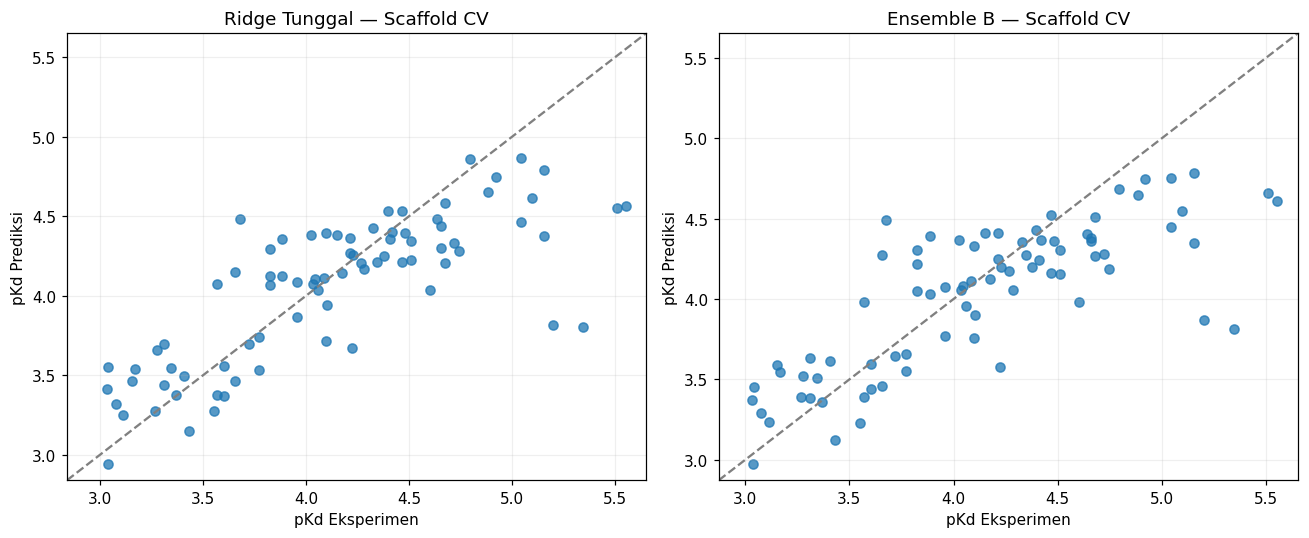

In [21]:

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, model in zip(
    axes, ["Ridge Tunggal", "Ensemble B"]
):
    d = fokus[fokus["Model"] == model]

    ax.scatter(
        d["pKd_eksperimen"],
        d["pKd_prediksi"],
        alpha=0.75
    )

    batas = [
        min(d["pKd_eksperimen"].min(),
            d["pKd_prediksi"].min()) - 0.1,
        max(d["pKd_eksperimen"].max(),
            d["pKd_prediksi"].max()) + 0.1
    ]

    ax.plot(batas, batas, "--", color="gray")
    ax.set_xlim(batas)
    ax.set_ylim(batas)
    ax.set_xlabel("pKd Eksperimen")
    ax.set_ylabel("pKd Prediksi")
    ax.set_title(model + " — Scaffold CV")
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.savefig(
    OUT / "Scaffold_Aktual_vs_Prediksi.png",
    dpi=200
)
plt.show()



### 8.3 Hasil dan Interpretasi Scaffold Cross-Validation

Scaffold Cross-Validation dilakukan menggunakan GroupKFold 5-fold pada 80 senyawa inhibitor USP5 dengan 38 scaffold unik.

#### Ringkasan Hasil

| Model | R² | RMSE | MAE |
|---|---:|---:|---:|
| Ridge Tunggal | **0,5945** | **0,4033** | **0,2866** |
| Ensemble A | 0,5890 | 0,4061 | 0,2868 |
| Ensemble B | 0,5881 | 0,4065 | 0,2973 |
| ML Ensemble Pak Ridwan (referensi) | 0,5805 | 0,4102 | 0,2992 |

#### Interpretasi

1. Ridge Tunggal menghasilkan R² scaffold tertinggi sebesar 0,5945, sedikit melampaui nilai referensi Pak Ridwan sebesar 0,5805.
2. Ketiga model menunjukkan kemampuan generalisasi terhadap scaffold yang tidak ditemukan selama pelatihan, tetapi performanya masih lebih rendah dibandingkan Random CV.
3. Fold 3 dan 4 memiliki RMSE relatif tinggi, yaitu sekitar 0,52 dan 0,62 pada Ridge Tunggal. Hal ini menunjukkan adanya perbedaan tingkat kesulitan prediksi antar-fold.
4. Beberapa senyawa dengan pKd tinggi mengalami underprediction, khususnya CHEMBL5410606 dan CHEMBL5426708.
5. Ensemble tidak memberikan peningkatan scaffold CV dibandingkan Ridge Tunggal.

#### Kesimpulan

Ridge Tunggal menjadi kandidat terbaik berdasarkan Scaffold CV pada eksperimen ini, sedangkan Ensemble B tetap menjadi kandidat berdasarkan Repeated Random CV.

Meskipun seluruh model menghasilkan angka yang sedikit lebih baik dibandingkan referensi Pak Ridwan pada scaffold CV, perbedaan protokol dan pembagian data belum memungkinkan klaim keunggulan secara langsung.

Tahap berikutnya adalah analisis residual untuk mengidentifikasi pola dan sumber kesalahan prediksi.



## 9. Analisis Error dan Residual Model

Analisis residual dilakukan untuk mengevaluasi selisih antara nilai pKd eksperimen dan pKd prediksi pada model Ridge Tunggal dan Ensemble B.

Residual dihitung sebagai:

**Residual = pKd eksperimen − pKd prediksi**

Interpretasi:
- Residual positif: model memprediksi pKd terlalu rendah (underprediction).
- Residual negatif: model memprediksi pKd terlalu tinggi (overprediction).
- Residual mendekati nol: prediksi mendekati nilai eksperimen.

Analisis dilakukan menggunakan prediksi out-of-fold dari Scaffold Cross-Validation, sehingga setiap nilai prediksi berasal dari model yang tidak dilatih menggunakan senyawa tersebut.


In [22]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Menggunakan prediksi Scaffold CV dari Tahap 8
residual_df = fokus.copy()

residual_df["Residual"] = (
    residual_df["pKd_eksperimen"] -
    residual_df["pKd_prediksi"]
)

residual_df["Error_Absolut"] = residual_df["Residual"].abs()

# Kelompok aktivitas berdasarkan rentang nilai pKd
bins = [-np.inf, 4.0, 5.0, np.inf]
labels = ["pKd < 4", "4 <= pKd < 5", "pKd >= 5"]

residual_df["Rentang_pKd"] = pd.cut(
    residual_df["pKd_eksperimen"],
    bins=bins,
    labels=labels,
    right=False
)

ringkasan_residual = (
    residual_df
    .groupby(["Model", "Rentang_pKd"], observed=True)
    .agg(
        Jumlah=("Residual", "size"),
        Bias_Rata_Rata=("Residual", "mean"),
        MAE=("Error_Absolut", "mean"),
        Error_Maksimum=("Error_Absolut", "max")
    )
    .round(4)
)

print("=== ANALISIS RESIDUAL BERDASARKAN RENTANG pKd ===")
display(ringkasan_residual)

ringkasan_residual.to_csv(
    OUT / "Analisis_Residual_Per_Rentang.csv"
)


=== ANALISIS RESIDUAL BERDASARKAN RENTANG pKd ===


Jumlah  Bias_Rata_Rata     MAE  Error_Maksimum
Model         Rentang_pKd                                                 
Ensemble B    pKd < 4           33         -0.1492  0.2603          0.8142
              4 <= pKd < 5      38          0.1429  0.2083          0.6446
              pKd >= 5           9          0.8085  0.8085          1.5316
Ridge Tunggal pKd < 4           33         -0.1548  0.2577          0.8071
              4 <= pKd < 5      38          0.1041  0.1889          0.5639
              pKd >= 5           9          0.8055  0.8055          1.5443

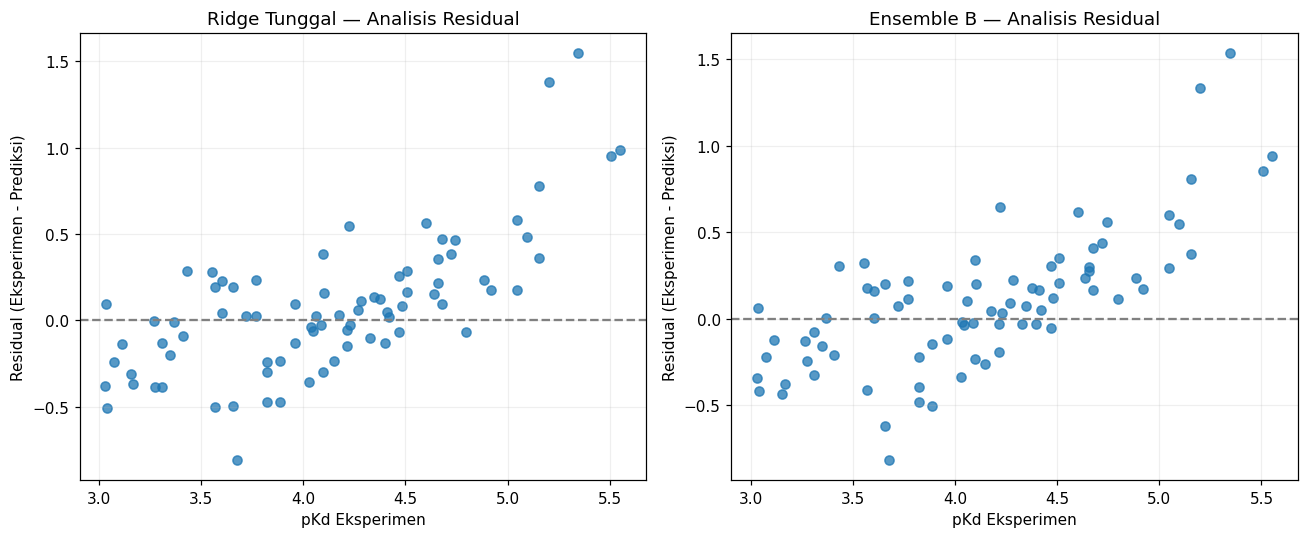

In [23]:

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, model in zip(
    axes, ["Ridge Tunggal", "Ensemble B"]
):
    d = residual_df[residual_df["Model"] == model]

    ax.scatter(
        d["pKd_eksperimen"],
        d["Residual"],
        alpha=0.75
    )

    ax.axhline(
        0, linestyle="--", color="gray"
    )

    ax.set_xlabel("pKd Eksperimen")
    ax.set_ylabel("Residual (Eksperimen - Prediksi)")
    ax.set_title(model + " — Analisis Residual")
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.savefig(
    OUT / "Grafik_Residual_Scaffold.png",
    dpi=200
)
plt.show()



### 9.1 Hasil dan Interpretasi Analisis Residual

Analisis residual dilakukan menggunakan prediksi out-of-fold Scaffold Cross-Validation pada 80 senyawa inhibitor USP5.

Dua model yang dianalisis adalah Ridge Tunggal dan Ensemble B.

#### Hasil Analisis Berdasarkan Rentang pKd

| Rentang pKd | Jumlah Senyawa | MAE Ridge | MAE Ensemble B |
|---|---:|---:|---:|
| pKd < 4 | 33 | 0,2577 | 0,2603 |
| 4 ≤ pKd < 5 | 38 | **0,1889** | 0,2083 |
| pKd ≥ 5 | 9 | **0,8055** | 0,8085 |

#### Interpretasi

1. **Rentang pKd 4–5 menghasilkan kesalahan prediksi terendah**, menunjukkan kemampuan prediksi yang relatif lebih baik pada rentang aktivitas menengah.

2. **Senyawa dengan pKd ≥ 5 menghasilkan kesalahan terbesar**, dengan MAE sekitar 0,81 pada kedua model. Hanya terdapat 9 senyawa dalam kelompok ini.

3. **Terjadi underprediction sistematis pada kelompok pKd ≥ 5.** Seluruh sembilan senyawa dalam kelompok ini mengalami residual positif, dengan bias rata-rata +0,8055 pada Ridge dan +0,8085 pada Ensemble B.

4. **Senyawa dengan pKd < 4 cenderung mengalami overprediction**, ditunjukkan oleh bias rata-rata negatif, yaitu -0,1548 pada Ridge dan -0,1492 pada Ensemble B.

5. Kedua model menunjukkan kecenderungan prediksi menuju rentang aktivitas menengah (*regression to the mean*), sehingga kemampuan membedakan senyawa dengan aktivitas rendah dan tinggi masih terbatas.

6. Ridge Tunggal memberikan MAE sedikit lebih rendah dibandingkan Ensemble B pada seluruh kelompok pKd.

#### Kesimpulan

Analisis residual menunjukkan bahwa keterbatasan utama kedua model adalah prediksi terhadap senyawa dengan nilai pKd tinggi (≥ 5).

Walaupun model menghasilkan R² scaffold sekitar 0,59, kesalahan prediksi tidak tersebar merata pada seluruh rentang aktivitas.

Oleh karena itu, nilai R² keseluruhan perlu dilaporkan bersama analisis residual agar keterbatasan model tetap terlihat.

**Rekomendasi:** Pada pengembangan berikutnya, perlu dilakukan pemeriksaan representasi senyawa dengan pKd tinggi dan evaluasi terhadap variasi data training sebelum mencoba optimasi model.

Hasil ini merupakan analisis validasi internal, bukan pengujian eksternal independen.



## 9.2 Analisis Korelasi Error Antaranggota Ensemble

### Tujuan

Analisis ini dilakukan untuk mengetahui apakah Ridge Regression, Bayesian Ridge, dan XGBoost menghasilkan pola kesalahan prediksi yang berbeda.

Ketiga algoritma merupakan anggota Ensemble B yang dipilih berdasarkan hasil screening pada 80 senyawa inhibitor USP5.

### Mengapa analisis ini diperlukan?

Ensemble tidak selalu lebih baik daripada model tunggal. Jika seluruh anggota menghasilkan kesalahan yang sangat mirip, penggabungan prediksi mungkin hanya memberikan peningkatan kecil.

Sebaliknya, jika kesalahan antaranggota berbeda atau saling melengkapi, ensemble berpotensi mengurangi kesalahan prediksi secara keseluruhan.

Analisis dilakukan menggunakan prediksi out-of-fold agar kesalahan dihitung pada senyawa yang tidak digunakan dalam pelatihan fold terkait.


In [26]:

print("=== KONFIGURASI ENSEMBLE B ===")

print("Anggota model:")
for nama in EXPERIMENTS["Ensemble B"]:
    print("-", nama)

print("\nDataset:", X_model.shape)
print("Jumlah scaffold:", len(set(scaffold_groups)))

print("\nSeed evaluasi:", [200, 201, 202, 203, 204])


=== KONFIGURASI ENSEMBLE B ===
Anggota model:
- Ridge
- Bayesian Ridge
- XGBoost

Dataset: (80, 1191)
Jumlah scaffold: 38

Seed evaluasi: [200, 201, 202, 203, 204]



### 9.3 Evaluasi Korelasi Error Antaranggota Ensemble B

Analisis dilakukan terhadap tiga algoritma penyusun Ensemble B:

1. Ridge Regression
2. Bayesian Ridge
3. XGBoost

#### Tujuan

Mengidentifikasi hubungan kesalahan prediksi antaranggota ensemble dan mengevaluasi apakah penggabungan ketiga algoritma memberikan manfaat dibandingkan model tunggal.

#### Metode

- Dataset: 80 senyawa inhibitor USP5.
- Representasi fitur: Morgan Count Fingerprint + MACCS Keys.
- Validasi: Scaffold 5-Fold Cross-Validation.
- Prediksi: Out-of-Fold (OOF).
- Analisis: Korelasi Pearson antar-residual.

#### Interpretasi

- Korelasi mendekati +1: pola kesalahan antar-model sangat mirip.
- Korelasi mendekati 0: kesalahan tidak memiliki hubungan linear yang kuat.
- Korelasi negatif: kesalahan cenderung bergerak berlawanan arah.

Korelasi error yang lebih rendah dapat memberikan peluang bagi ensemble untuk meningkatkan prediksi, tetapi tidak menjamin peningkatan performa.


In [27]:

from sklearn.model_selection import GroupKFold
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import numpy as np
import pandas as pd

anggota = EXPERIMENTS["Ensemble B"]

cv = GroupKFold(n_splits=5)

prediksi_anggota = {
    nama: np.full(len(y_model), np.nan)
    for nama in anggota
}

# Evaluasi setiap anggota pada fold yang sama
for fold, (tr, te) in enumerate(
    cv.split(X_model, y_model, scaffold_groups), 1
):
    for nama in anggota:
        model = build_model(nama)
        model.fit(X_model[tr], y_model[tr])

        prediksi_anggota[nama][te] = (
            np.asarray(model.predict(X_model[te])).reshape(-1)
        )

    print(f"Scaffold fold {fold}/5 selesai")

# Gabungkan hasil prediksi
hasil_anggota = pd.DataFrame({
    "chembl_id": df["chembl_id"].to_numpy(),
    "pKd_eksperimen": y_model
})

for nama in anggota:
    hasil_anggota[f"pred_{nama}"] = prediksi_anggota[nama]
    hasil_anggota[f"error_{nama}"] = (
        y_model - prediksi_anggota[nama]
    )

# Prediksi gabungan dengan bobot sama
hasil_anggota["pred_Ensemble_B"] = np.mean(
    np.column_stack([
        prediksi_anggota[nama] for nama in anggota
    ]),
    axis=1
)

assert hasil_anggota.select_dtypes(
    include="number"
).notna().all().all()

# Metrik masing-masing model
records = []

for nama in anggota + ["Ensemble_B"]:
    pred = hasil_anggota[f"pred_{nama}"]

    records.append({
        "Model": nama,
        "R2": r2_score(y_model, pred),
        "RMSE": np.sqrt(mean_squared_error(y_model, pred)),
        "MAE": mean_absolute_error(y_model, pred)
    })

metrik_anggota = pd.DataFrame(records)

print("\n=== PERFORMA ANGGOTA ENSEMBLE B ===")
display(metrik_anggota.round(4))

hasil_anggota.to_csv(
    OUT / "Prediksi_OOF_Anggota_Ensemble_B.csv",
    index=False
)


Scaffold fold 1/5 selesai
Scaffold fold 2/5 selesai
Scaffold fold 3/5 selesai
Scaffold fold 4/5 selesai
Scaffold fold 5/5 selesai

=== PERFORMA ANGGOTA ENSEMBLE B ===


,Model,R2,RMSE,MAE
0,Ridge,0.5945,0.4033,0.2866
1,Bayesian Ridge,0.5954,0.4029,0.2804
2,XGBoost,0.5038,0.4461,0.3433
3,Ensemble_B,0.5881,0.4065,0.2973


=== KORELASI ERROR ANTARANGGOTA ===


,Ridge,Bayesian Ridge,XGBoost
Ridge,1.0000,0.9963,0.8971
Bayesian Ridge,0.9963,1.0000,0.8916
XGBoost,0.8971,0.8916,1.0000


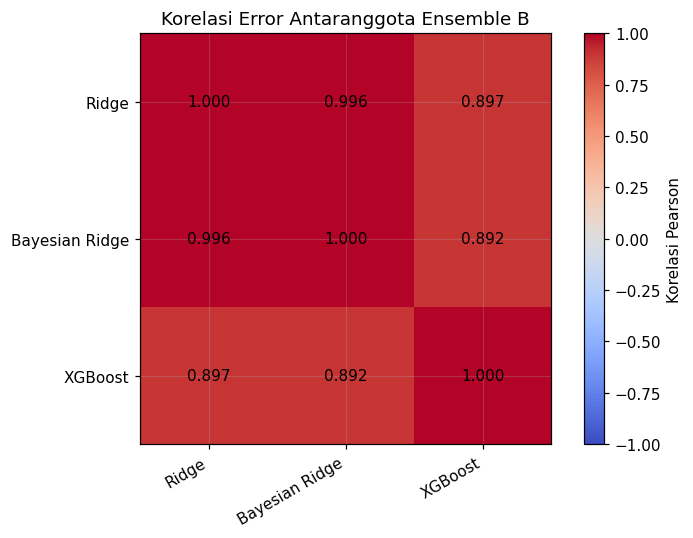

In [28]:

import matplotlib.pyplot as plt

# Matriks error masing-masing algoritma
kolom_error = [
    f"error_{nama}" for nama in anggota
]

error_matrix = hasil_anggota[kolom_error].copy()
error_matrix.columns = anggota

# Korelasi Pearson
korelasi = error_matrix.corr(method="pearson")

print("=== KORELASI ERROR ANTARANGGOTA ===")
display(korelasi.round(4))

# Visualisasi matriks korelasi
fig, ax = plt.subplots(figsize=(7, 5))

im = ax.imshow(
    korelasi,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

ax.set_xticks(range(len(anggota)))
ax.set_yticks(range(len(anggota)))

ax.set_xticklabels(anggota, rotation=30, ha="right")
ax.set_yticklabels(anggota)

for i in range(len(anggota)):
    for j in range(len(anggota)):
        ax.text(
            j, i,
            f"{korelasi.iloc[i, j]:.3f}",
            ha="center",
            va="center",
            color="black"
        )

fig.colorbar(im, ax=ax, label="Korelasi Pearson")
ax.set_title("Korelasi Error Antaranggota Ensemble B")

plt.tight_layout()

plt.savefig(
    OUT / "Korelasi_Error_Ensemble_B.png",
    dpi=200
)

plt.show()

korelasi.to_csv(
    OUT / "Korelasi_Error_Ensemble_B.csv"
)



### 9.4 Hasil dan Interpretasi Korelasi Error Antaranggota Ensemble B

Analisis dilakukan menggunakan prediksi out-of-fold dari Scaffold 5-Fold Cross-Validation pada dataset 80 senyawa inhibitor USP5.

Tujuan analisis adalah mengevaluasi performa individual dan hubungan kesalahan prediksi antara Ridge Regression, Bayesian Ridge, dan XGBoost sebagai anggota Ensemble B.

#### Performa Individual dan Ensemble

| Model | R² | RMSE | MAE |
|---|---:|---:|---:|
| Ridge Regression | 0,5945 | 0,4033 | 0,2866 |
| **Bayesian Ridge** | **0,5954** | **0,4029** | **0,2804** |
| XGBoost | 0,5038 | 0,4461 | 0,3433 |
| Ensemble B | 0,5881 | 0,4065 | 0,2973 |

Bayesian Ridge menghasilkan performa individual terbaik dengan R² sebesar 0,5954, RMSE 0,4029, dan MAE 0,2804.

Sebaliknya, XGBoost menghasilkan performa paling rendah di antara ketiga anggota ensemble.

#### Korelasi Error Antaranggota

| Pasangan Algoritma | Korelasi Pearson |
|---|---:|
| Ridge – Bayesian Ridge | 0,9963 |
| Ridge – XGBoost | 0,8971 |
| Bayesian Ridge – XGBoost | 0,8916 |

#### Interpretasi

1. **Ridge dan Bayesian Ridge memiliki korelasi error sangat tinggi (0,9963)**, menunjukkan pola kesalahan prediksi yang hampir identik.

2. **XGBoost memiliki korelasi error yang sedikit lebih rendah**, tetapi masih cukup tinggi terhadap kedua model linear.

3. **Kontribusi XGBoost belum meningkatkan performa ensemble**, karena performa individualnya lebih rendah dan pola kesalahannya masih berkorelasi kuat dengan anggota lainnya.

4. **Ensemble B menghasilkan performa lebih rendah dibandingkan Ridge dan Bayesian Ridge secara individual** pada Scaffold CV, sehingga equal-weight averaging belum memberikan keuntungan dalam protokol evaluasi ini.

5. Hasil tersebut menunjukkan bahwa keberagaman algoritma saja tidak cukup untuk menjamin peningkatan performa. Kualitas prediksi masing-masing anggota dan hubungan kesalahannya juga perlu diperhatikan.

#### Kesimpulan

Analisis korelasi error menunjukkan bahwa Ensemble B belum memberikan peningkatan performa pada Scaffold Cross-Validation.

**Bayesian Ridge menjadi kandidat model tunggal dengan performa scaffold terbaik**, meskipun keunggulannya dibandingkan Ridge sangat kecil.

Ensemble B tetap memiliki performa rata-rata tertinggi pada Repeated Random CV, tetapi keunggulan tersebut tidak konsisten pada Scaffold CV.

Dengan demikian, Bayesian Ridge, Ridge Tunggal, dan Ensemble B tetap dapat dipertahankan sebagai kandidat evaluasi lanjutan. Pemilihan model akhir memerlukan pertimbangan terhadap kedua protokol validasi dan keterbatasan prediksi pada senyawa dengan pKd tinggi.



## 10. Evaluasi Hold-Out 64/16 dengan 20 Pengulangan

### 10.1 Tujuan

Evaluasi hold-out dilakukan untuk mengetahui kemampuan dan kestabilan prediksi model pada pembagian data training dan testing yang berbeda.

Tahap ini melanjutkan hasil screening, repeated random CV, scaffold CV, serta analisis korelasi error pada tahap sebelumnya.

### Model yang Dievaluasi

1. **Ridge Regression:** kandidat terbaik pada screening awal.
2. **Bayesian Ridge:** model tunggal dengan performa scaffold CV tertinggi.
3. **Ensemble B:** kombinasi Ridge, Bayesian Ridge, dan XGBoost yang unggul pada repeated random CV.

### Protokol Evaluasi

- Dataset: 80 senyawa inhibitor USP5.
- Training: 64 senyawa (80%).
- Testing: 16 senyawa (20%).
- Metode: StratifiedShuffleSplit berdasarkan kuartil pKd.
- Pengulangan: 20 kali.
- Random seed: 42.
- Metrik: R², RMSE, MAE.

### Mengapa Menggunakan Stratifikasi?

Dataset memiliki jumlah senyawa yang tidak merata pada berbagai rentang pKd, terutama hanya 9 senyawa dengan pKd ≥ 5.

Stratifikasi berdasarkan kuartil membantu menjaga keterwakilan rentang aktivitas dalam setiap pembagian data.

Hasil ini merupakan evaluasi hold-out berulang untuk analisis sensitivitas model, bukan pengujian eksternal independen, karena dataset sebelumnya sudah digunakan dalam proses pemilihan model.


In [29]:

from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.metrics import (
    r2_score, mean_squared_error, mean_absolute_error
)
import numpy as np
import pandas as pd

# Model berdasarkan hasil penelitian sebelumnya
HOLDOUT_MODELS = {
    "Ridge Tunggal": ["Ridge"],
    "Bayesian Ridge": ["Bayesian Ridge"],
    "Ensemble B": ["Ridge", "Bayesian Ridge", "XGBoost"]
}

# Stratifikasi kuartil pKd
bins_holdout = np.digitize(
    y_model,
    np.quantile(y_model, [0.25, 0.50, 0.75])
)

sss = StratifiedShuffleSplit(
    n_splits=20,
    test_size=16,
    random_state=42
)

hasil_holdout = []
prediksi_holdout = []

for nomor, (tr, te) in enumerate(
    sss.split(X_model, bins_holdout), 1
):
    # Latih tiap algoritma satu kali per split
    pred_member = {}

    for nama in ["Ridge", "Bayesian Ridge", "XGBoost"]:
        mdl = build_model(nama)
        mdl.fit(X_model[tr], y_model[tr])

        pred_member[nama] = np.asarray(
            mdl.predict(X_model[te])
        ).reshape(-1)

    for model_nama, members in HOLDOUT_MODELS.items():
        pred = np.mean(
            np.column_stack([
                pred_member[nama] for nama in members
            ]),
            axis=1
        )

        hasil_holdout.append({
            "Model": model_nama,
            "Split": nomor,
            "R2": r2_score(y_model[te], pred),
            "RMSE": np.sqrt(
                mean_squared_error(y_model[te], pred)
            ),
            "MAE": mean_absolute_error(y_model[te], pred),
            "Jumlah_pKd_5": int(
                (y_model[te] >= 5).sum()
            )
        })

        prediksi_holdout.append(pd.DataFrame({
            "Model": model_nama,
            "Split": nomor,
            "chembl_id": df["chembl_id"].iloc[te].to_numpy(),
            "pKd_eksperimen": y_model[te],
            "pKd_prediksi": pred
        }))

    print(f"Hold-out split {nomor}/20 selesai")

# Gabungkan hasil
holdout_df = pd.DataFrame(hasil_holdout)
holdout_preds = pd.concat(
    prediksi_holdout, ignore_index=True
)

ringkasan_holdout = (
    holdout_df
    .groupby("Model")[["R2", "RMSE", "MAE"]]
    .agg(["mean", "std"])
    .round(4)
)

print("\n=== HASIL HOLD-OUT 64/16 ===")
display(ringkasan_holdout)

# Simpan hasil
holdout_df.to_csv(
    OUT / "Holdout_20_Split_Hasil.csv",
    index=False
)

holdout_preds.to_csv(
    OUT / "Holdout_20_Split_Prediksi.csv",
    index=False
)

ringkasan_holdout.to_csv(
    OUT / "Holdout_20_Split_Ringkasan.csv"
)

print("Hasil tersimpan di:", OUT)


Hold-out split 1/20 selesai
Hold-out split 2/20 selesai
Hold-out split 3/20 selesai
Hold-out split 4/20 selesai
Hold-out split 5/20 selesai
Hold-out split 6/20 selesai
Hold-out split 7/20 selesai
Hold-out split 8/20 selesai
Hold-out split 9/20 selesai
Hold-out split 10/20 selesai
Hold-out split 11/20 selesai
Hold-out split 12/20 selesai
Hold-out split 13/20 selesai
Hold-out split 14/20 selesai
Hold-out split 15/20 selesai
Hold-out split 16/20 selesai
Hold-out split 17/20 selesai
Hold-out split 18/20 selesai
Hold-out split 19/20 selesai
Hold-out split 20/20 selesai

=== HASIL HOLD-OUT 64/16 ===


R2            RMSE             MAE        
                  mean     std    mean     std    mean     std
Model                                                         
Bayesian Ridge  0.7681  0.1674  0.2802  0.0799  0.2217  0.0498
Ensemble B      0.7792  0.1685  0.2723  0.0808  0.2155  0.0509
Ridge Tunggal   0.7710  0.1677  0.2777  0.0818  0.2186  0.0554

Hasil tersimpan di: /data/Aliya/model/Hasil_Ensemble_80


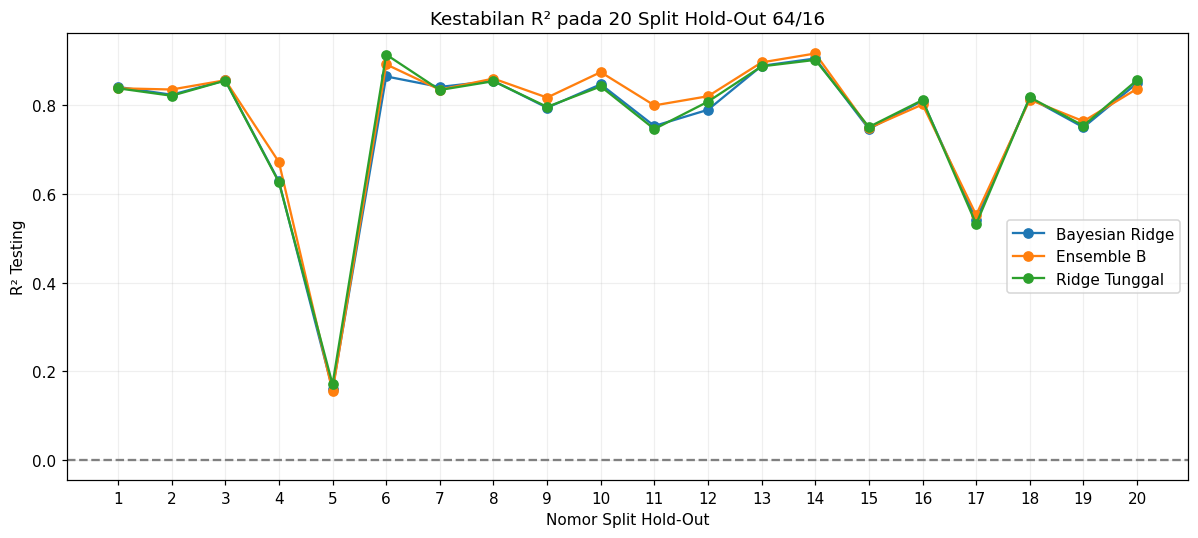

In [30]:

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(11, 5))

for nama, grup in holdout_df.groupby("Model"):
    grup = grup.sort_values("Split")

    ax.plot(
        grup["Split"],
        grup["R2"],
        marker="o",
        label=nama
    )

ax.axhline(0, linestyle="--", color="gray")
ax.set_xlabel("Nomor Split Hold-Out")
ax.set_ylabel("R² Testing")
ax.set_title("Kestabilan R² pada 20 Split Hold-Out 64/16")
ax.set_xticks(range(1, 21))
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.savefig(
    OUT / "Grafik_Holdout_20_Split.png",
    dpi=200
)
plt.show()


In [31]:

# Analisis diagnostik hold-out split ke-5
diagnostik_5 = holdout_preds[
    holdout_preds["Split"] == 5
].copy()

diagnostik_5["Error_Absolut"] = abs(
    diagnostik_5["pKd_eksperimen"] -
    diagnostik_5["pKd_prediksi"]
)

print("=== ANALISIS SPLIT KE-5 ===")

for nama, grup in diagnostik_5.groupby("Model"):
    print(f"\nModel: {nama}")
    print("Jumlah senyawa:", len(grup))
    print("pKd minimum:", round(grup["pKd_eksperimen"].min(), 4))
    print("pKd maksimum:", round(grup["pKd_eksperimen"].max(), 4))
    print("Jumlah pKd >= 5:", (grup["pKd_eksperimen"] >= 5).sum())
    print("MAE:", round(grup["Error_Absolut"].mean(), 4))
    print("Error maksimum:", round(grup["Error_Absolut"].max(), 4))

print("\n=== 10 ERROR TERBESAR ENSEMBLE B SPLIT 5 ===")

display(
    diagnostik_5[
        diagnostik_5["Model"] == "Ensemble B"
    ]
    .sort_values("Error_Absolut", ascending=False)
    .head(10)
)

diagnostik_5.to_csv(
    OUT / "Analisis_Holdout_Split_5.csv",
    index=False
)


=== ANALISIS SPLIT KE-5 ===

Model: Bayesian Ridge
Jumlah senyawa: 16
pKd minimum: 3.3098
pKd maksimum: 5.3468
Jumlah pKd >= 5: 2
MAE: 0.3479
Error maksimum: 1.4722

Model: Ensemble B
Jumlah senyawa: 16
pKd minimum: 3.3098
pKd maksimum: 5.3468
Jumlah pKd >= 5: 2
MAE: 0.3491
Error maksimum: 1.4753

Model: Ridge Tunggal
Jumlah senyawa: 16
pKd minimum: 3.3098
pKd maksimum: 5.3468
Jumlah pKd >= 5: 2
MAE: 0.3538
Error maksimum: 1.4553

=== 10 ERROR TERBESAR ENSEMBLE B SPLIT 5 ===


,Model,Split,chembl_id,pKd_eksperimen,pKd_prediksi,Error_Absolut
235,Ensemble B,5,CHEMBL5410606,5.346787,3.871479,1.475308
225,Ensemble B,5,CHEMBL5426708,5.200659,3.882624,1.318035
239,Ensemble B,5,CHEMBL5268432,4.602060,4.126858,0.475202
232,Ensemble B,5,CHEMBL5269641,3.568636,3.993093,0.424457
234,Ensemble B,5,CHEMBL4442518,3.431798,3.106930,0.324868
229,Ensemble B,5,CHEMBL5274321,3.657577,3.955508,0.297931
226,Ensemble B,5,CHEMBL4460800,3.769551,3.492807,0.276744
237,Ensemble B,5,CHEMBL5273898,4.096910,4.367878,0.270968
224,Ensemble B,5,CHEMBL5281654,4.677781,4.871052,0.193271
236,Ensemble B,5,CHEMBL5289065,4.229148,4.380792,0.151644



### 10.2 Hasil dan Interpretasi Hold-Out 64/16

Evaluasi dilakukan pada 80 senyawa inhibitor USP5 menggunakan StratifiedShuffleSplit sebanyak 20 pengulangan, dengan 64 senyawa training dan 16 senyawa testing pada setiap pembagian.

Tiga kandidat yang digunakan adalah Ridge Tunggal, Bayesian Ridge, dan Ensemble B.

#### Hasil Evaluasi

| Model | R² Mean ± SD | RMSE Mean ± SD | MAE Mean |
|---|---|---|---|
| Bayesian Ridge | 0,7681 ± 0,1674 | 0,2802 ± 0,0799 | 0,2217 |
| **Ensemble B** | **0,7792 ± 0,1685** | **0,2723 ± 0,0808** | **0,2155** |
| Ridge Tunggal | 0,7710 ± 0,1677 | 0,2777 ± 0,0818 | 0,2186 |

#### Interpretasi Hasil

1. Ensemble B menghasilkan performa rata-rata terbaik dengan R² sebesar 0,7792, RMSE 0,2723, dan MAE 0,2155.

2. Perbedaan performa antar-model relatif kecil sehingga belum menunjukkan keunggulan yang signifikan secara statistik.

3. Standar deviasi R² yang relatif besar (sekitar 0,17) menunjukkan sensitivitas performa model terhadap pembagian training dan testing.

4. Pada split ke-5, ketiga model mengalami penurunan R² yang tajam. Hal ini menunjukkan adanya pembagian data testing yang lebih sulit diprediksi.

---

### 10.3 Analisis Penurunan R² pada Split ke-5

Split ke-5 terdiri atas 16 senyawa testing dengan rentang pKd 3,3098–5,3468. Dua senyawa memiliki pKd ≥ 5.

#### Kesalahan Terbesar pada Ensemble B

| Molecule ChEMBL ID | pKd Eksperimen | pKd Prediksi | Error Absolut |
|---|---:|---:|---:|
| CHEMBL5410606 | 5,3468 | 3,8715 | 1,4753 |
| CHEMBL5426708 | 5,2007 | 3,8826 | 1,3180 |

Kedua senyawa mengalami underprediction yang besar dan menyumbang sekitar 84% dari total kuadrat kesalahan prediksi Ensemble B pada split ke-5.

#### Interpretasi

1. Dua senyawa dengan pKd tinggi memberikan kontribusi dominan terhadap peningkatan RMSE dan penurunan R².

2. Ketiga model mengalami pola penurunan yang serupa, menunjukkan keterbatasan prediksi yang tidak hanya terjadi pada satu algoritma.

3. Temuan tersebut konsisten dengan analisis residual pada Tahap 9, yang menunjukkan bahwa senyawa dengan pKd ≥ 5 memiliki kesalahan prediksi tertinggi.

4. Penyebab struktural kesalahan belum dapat dipastikan tanpa analisis kemiripan molekul antara senyawa testing dan training.

5. Split ke-5 tetap dipertahankan dalam evaluasi karena penghapusan pembagian dengan hasil rendah dapat menyebabkan bias pelaporan.

---

### 10.4 Perbandingan dengan Referensi Pak Ridwan

| Model | R² Hold-Out | RMSE |
|---|---:|---:|
| ML Ensemble Pak Ridwan | 0,7960 | 0,2639 |
| Ensemble B penelitian ini | 0,7792 | 0,2723 |

Hasil referensi Pak Ridwan menunjukkan nilai R² sedikit lebih tinggi dan RMSE lebih rendah dibandingkan Ensemble B.

Namun, kedua model menggunakan komposisi algoritma yang berbeda, sehingga hasil ini merupakan perbandingan deskriptif dan bukan bukti keunggulan yang definitif.

---

### 10.5 Kesimpulan Tahap 10

1. **Ensemble B memberikan performa rata-rata terbaik** pada evaluasi hold-out 64/16 sebanyak 20 pengulangan.

2. Performa ketiga model dipengaruhi oleh komposisi senyawa dalam pembagian testing.

3. Penurunan R² pada split ke-5 berkaitan terutama dengan kesalahan prediksi yang besar pada dua senyawa dengan pKd tinggi.

4. Hasil tersebut memperkuat temuan bahwa keterbatasan utama model adalah prediksi senyawa dengan pKd ≥ 5.

5. Ensemble B tetap menjadi kandidat utama berdasarkan repeated random CV dan hold-out berulang, sedangkan Bayesian Ridge dan Ridge Tunggal tetap dipertahankan sebagai pembanding berdasarkan hasil scaffold CV.

Seluruh evaluasi merupakan analisis internal dan belum dapat dinyatakan sebagai pengujian eksternal independen, karena dataset 80 senyawa sebelumnya telah digunakan dalam proses pemilihan model.

**Tahap berikutnya:** Visualisasi diagnostik untuk menganalisis hubungan nilai pKd eksperimen, prediksi, dan residual secara keseluruhan.



## 11. Visualisasi Diagnostik Model Machine Learning USP5

### 11.1 Tujuan

Visualisasi diagnostik dilakukan untuk mengevaluasi hubungan antara nilai pKd eksperimen dan pKd prediksi, sekaligus mengidentifikasi pola kesalahan model.

Analisis ini melanjutkan hasil Repeated Random CV, Scaffold CV, dan Hold-Out 64/16 pada 80 senyawa inhibitor USP5.

### Model yang Dievaluasi

1. **Ridge Tunggal:** kandidat terbaik pada screening awal.
2. **Bayesian Ridge:** model tunggal dengan performa terbaik pada Scaffold CV.
3. **Ensemble B:** kombinasi Ridge, Bayesian Ridge, dan XGBoost yang menunjukkan performa terbaik pada Repeated Random CV dan Hold-Out berulang.

### Jenis Visualisasi

1. Actual vs Predicted pada Random CV.
2. Actual vs Predicted pada Scaffold CV.
3. Residual vs Predicted pada Scaffold CV.
4. Distribusi residual untuk membandingkan model.

### Mengapa Visualisasi Diperlukan?

Nilai R², RMSE, dan MAE memberikan informasi performa secara keseluruhan, tetapi tidak memperlihatkan pola kesalahan pada masing-masing senyawa.

Visualisasi membantu mengidentifikasi underprediction, overprediction, kesalahan ekstrem, dan kecenderungan prediksi menuju nilai tengah.

Analisis menggunakan prediksi out-of-fold (OOF) dari validasi internal, bukan prediksi training.


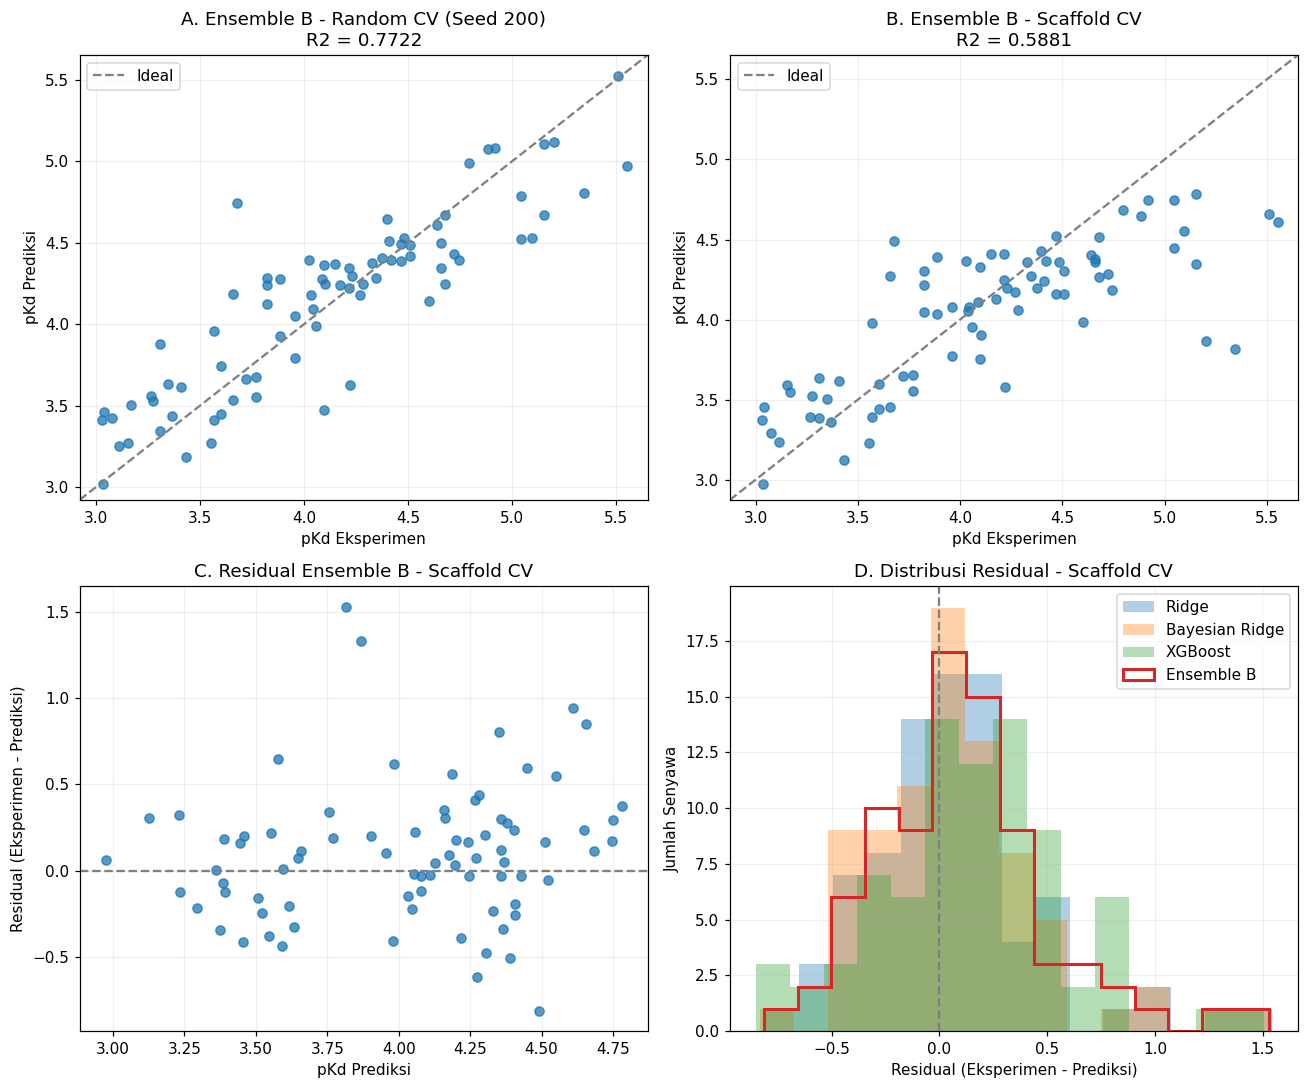

=== VISUALISASI DIAGNOSTIK SELESAI ===
Grafik tersimpan di: /data/Aliya/model/Hasil_Ensemble_80


In [32]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    r2_score, mean_squared_error, mean_absolute_error
)

# Ambil hasil Ensemble B dari validasi sebelumnya
random_B = preds_df[
    (preds_df["Model"] == "Ensemble B") &
    (preds_df["Protokol"] == "random") &
    (preds_df["Seed"] == 200)
].copy()

scaffold_B = preds_df[
    (preds_df["Model"] == "Ensemble B") &
    (preds_df["Protokol"] == "scaffold")
].copy()

assert len(random_B) == 80
assert len(scaffold_B) == 80
assert random_B["chembl_id"].is_unique
assert scaffold_B["chembl_id"].is_unique

# Residual = eksperimen - prediksi
scaffold_B["Residual"] = (
    scaffold_B["pKd_eksperimen"] -
    scaffold_B["pKd_prediksi"]
)

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

# A. Actual vs Predicted Random CV
ax = axes[0, 0]
ax.scatter(
    random_B["pKd_eksperimen"],
    random_B["pKd_prediksi"],
    alpha=0.75
)

lim = [
    min(random_B["pKd_eksperimen"].min(),
        random_B["pKd_prediksi"].min()) - 0.1,
    max(random_B["pKd_eksperimen"].max(),
        random_B["pKd_prediksi"].max()) + 0.1
]

ax.plot(lim, lim, "--", color="gray", label="Ideal")
ax.set_xlim(lim)
ax.set_ylim(lim)
ax.set_title(
    "A. Ensemble B - Random CV (Seed 200)\n"
    f"R2 = {r2_score(random_B['pKd_eksperimen'], random_B['pKd_prediksi']):.4f}"
)
ax.set_xlabel("pKd Eksperimen")
ax.set_ylabel("pKd Prediksi")
ax.legend()

# B. Actual vs Predicted Scaffold CV
ax = axes[0, 1]
ax.scatter(
    scaffold_B["pKd_eksperimen"],
    scaffold_B["pKd_prediksi"],
    alpha=0.75
)

lim = [
    min(scaffold_B["pKd_eksperimen"].min(),
        scaffold_B["pKd_prediksi"].min()) - 0.1,
    max(scaffold_B["pKd_eksperimen"].max(),
        scaffold_B["pKd_prediksi"].max()) + 0.1
]

ax.plot(lim, lim, "--", color="gray", label="Ideal")
ax.set_xlim(lim)
ax.set_ylim(lim)
ax.set_title(
    "B. Ensemble B - Scaffold CV\n"
    f"R2 = {r2_score(scaffold_B['pKd_eksperimen'], scaffold_B['pKd_prediksi']):.4f}"
)
ax.set_xlabel("pKd Eksperimen")
ax.set_ylabel("pKd Prediksi")
ax.legend()

# C. Residual vs Predicted
ax = axes[1, 0]
ax.scatter(
    scaffold_B["pKd_prediksi"],
    scaffold_B["Residual"],
    alpha=0.75
)
ax.axhline(0, linestyle="--", color="gray")
ax.set_title("C. Residual Ensemble B - Scaffold CV")
ax.set_xlabel("pKd Prediksi")
ax.set_ylabel("Residual (Eksperimen - Prediksi)")

# D. Distribusi residual ketiga model
ax = axes[1, 1]

for nama in ["Ridge", "Bayesian Ridge", "XGBoost"]:
    error = hasil_anggota[f"error_{nama}"]
    ax.hist(
        error,
        bins=15,
        alpha=0.35,
        label=nama
    )

ax.hist(
    scaffold_B["Residual"],
    bins=15,
    histtype="step",
    linewidth=2,
    label="Ensemble B"
)

ax.axvline(0, linestyle="--", color="gray")
ax.set_title("D. Distribusi Residual - Scaffold CV")
ax.set_xlabel("Residual (Eksperimen - Prediksi)")
ax.set_ylabel("Jumlah Senyawa")
ax.legend()

for ax in axes.flat:
    ax.grid(alpha=0.2)

plt.tight_layout()

plt.savefig(
    OUT / "Visualisasi_Diagnostik_USP5.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("=== VISUALISASI DIAGNOSTIK SELESAI ===")
print("Grafik tersimpan di:", OUT)


In [33]:

def hitung_metrik(df_pred, nama):
    aktual = df_pred["pKd_eksperimen"].to_numpy()
    prediksi = df_pred["pKd_prediksi"].to_numpy()

    return {
        "Evaluasi": nama,
        "R2": r2_score(aktual, prediksi),
        "RMSE": np.sqrt(
            mean_squared_error(aktual, prediksi)
        ),
        "MAE": mean_absolute_error(aktual, prediksi),
        "Bias": np.mean(aktual - prediksi)
    }

diagnostik_summary = pd.DataFrame([
    hitung_metrik(
        random_B, "Ensemble B - Random CV seed 200"
    ),
    hitung_metrik(
        scaffold_B, "Ensemble B - Scaffold CV"
    )
])

print("=== RINGKASAN DIAGNOSTIK USP5 ===")
display(diagnostik_summary.round(4))

diagnostik_summary.to_csv(
    OUT / "Ringkasan_Diagnostik_USP5.csv",
    index=False
)


=== RINGKASAN DIAGNOSTIK USP5 ===


,Evaluasi,R2,RMSE,MAE,Bias
0,Ensemble B - Random CV seed 200,0.7722,0.3023,0.2295,-0.0211
1,Ensemble B - Scaffold CV,0.5881,0.4065,0.2973,0.0973



### 11.2 Hasil dan Interpretasi Visualisasi Diagnostik

Visualisasi diagnostik dilakukan untuk mengevaluasi performa Ensemble B dalam memprediksi nilai pKd pada 80 senyawa inhibitor USP5.

Analisis menggunakan prediksi out-of-fold (OOF) dari Random 5-Fold Cross-Validation (seed 200) dan Scaffold 5-Fold Cross-Validation.

#### Ringkasan Hasil

| Parameter | Random CV (Seed 200) | Scaffold CV |
|---|---:|---:|
| R² | 0,7722 | 0,5881 |
| RMSE | 0,3023 | 0,4065 |
| MAE | 0,2295 | 0,2973 |
| Bias (Eksperimen − Prediksi) | −0,0211 | +0,0973 |

#### A. Actual vs Predicted — Random Cross-Validation

Pada Random CV, sebagian besar prediksi berada relatif dekat dengan garis ideal (y = x).

Nilai R² sebesar 0,7722 menunjukkan bahwa model memberikan performa prediksi yang cukup baik pada pembagian acak yang digunakan.

Namun, beberapa senyawa masih menunjukkan penyimpangan yang cukup besar dari nilai eksperimen.

#### B. Actual vs Predicted — Scaffold Cross-Validation

Pada Scaffold CV, nilai R² menurun menjadi 0,5881 dan RMSE meningkat menjadi 0,4065.

Penyebaran titik lebih jauh dari garis ideal dibandingkan Random CV, terutama pada sebagian senyawa dengan pKd tinggi.

Hal ini menunjukkan bahwa prediksi terhadap scaffold yang tidak muncul dalam training lebih sulit dibandingkan evaluasi dengan pembagian acak.

#### C. Analisis Residual

Residual dihitung sebagai selisih antara pKd eksperimen dan pKd prediksi.

Grafik menunjukkan adanya residual positif dan negatif dengan beberapa kesalahan ekstrem.

Bias rata-rata Scaffold CV sebesar +0,0973 menunjukkan kecenderungan underprediction secara keseluruhan.

Hasil ini konsisten dengan analisis Tahap 9, yang menemukan kesalahan lebih besar pada senyawa dengan pKd ≥ 5.

#### D. Distribusi Residual Antaralgoritma

Histogram residual menunjukkan bahwa sebagian besar kesalahan prediksi terkonsentrasi di sekitar nol, tetapi terdapat beberapa residual dengan nilai absolut besar.

Distribusi residual Ridge, Bayesian Ridge, XGBoost, dan Ensemble B saling tumpang tindih.

Hasil ini sejalan dengan analisis korelasi error pada Tahap 9, yang menunjukkan bahwa anggota Ensemble B memiliki pola kesalahan yang cukup mirip.

#### Kesimpulan Tahap 11

1. Ensemble B menunjukkan performa lebih baik pada Random CV dibandingkan Scaffold CV.
2. Penurunan performa Scaffold CV menunjukkan keterbatasan generalisasi terhadap kerangka molekul yang berbeda.
3. Senyawa dengan pKd tinggi masih menjadi sumber kesalahan prediksi yang penting.
4. Analisis residual menunjukkan bahwa nilai R² saja belum cukup untuk menggambarkan seluruh kemampuan prediksi model.
5. Hasil visualisasi memperkuat temuan dari evaluasi dan analisis error pada tahap sebelumnya.

**Tahap berikutnya:** Applicability Domain (AD), untuk mengevaluasi sejauh mana struktur kimia senyawa berada dalam ruang kemiripan molekul yang terwakili oleh data training.



## 12. Analisis Applicability Domain (AD)

### 12.1 Tujuan

Applicability Domain (AD) digunakan untuk mengevaluasi keterwakilan struktur kimia senyawa terhadap data training model QSAR inhibitor USP5.

Tahap ini melanjutkan hasil evaluasi Ensemble B, analisis scaffold, dan diagnostik residual pada tahap sebelumnya.

### Metode

- Dataset: 80 senyawa inhibitor USP5.
- Model: Ensemble B (Ridge + Bayesian Ridge + XGBoost).
- Representasi AD: Morgan Binary Fingerprint, radius 2, 2048 bit.
- Kemiripan molekul: Tanimoto Similarity.
- Evaluasi: Random 5-Fold CV (seed 200) dan Scaffold 5-Fold CV.
- Analisis statistik: Korelasi Spearman antara kemiripan maksimum dan kesalahan absolut prediksi.

### Mengapa Menggunakan Tanimoto Similarity?

Tanimoto Similarity digunakan untuk mengukur kesamaan pola struktur molekul berdasarkan fingerprint.

Nilainya berada pada rentang 0–1:
- Mendekati 1: kemiripan fingerprint tinggi.
- Mendekati 0: kemiripan fingerprint rendah.

Kemiripan dihitung terhadap data training pada masing-masing fold untuk menghindari penggunaan senyawa validasi sebagai referensi kemiripan.

### Mengapa Menggunakan Korelasi Spearman?

Korelasi Spearman digunakan untuk menguji hubungan monotonik antara kemiripan struktur dan besar kesalahan prediksi.

Korelasi negatif mengindikasikan bahwa semakin tinggi kemiripan struktur, kesalahan prediksi cenderung semakin kecil.

Namun, hubungan tersebut tidak selalu muncul karena kesalahan prediksi juga dapat dipengaruhi distribusi pKd, variasi scaffold, dan keterbatasan model.

Analisis AD ini merupakan pendekatan berbasis kemiripan molekul, bukan jaminan ketepatan prediksi.


In [34]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from rdkit import DataStructs
from rdkit.Chem import rdFingerprintGenerator
from sklearn.model_selection import KFold, GroupKFold
from scipy.stats import spearmanr

# Dataset dan struktur yang sama dengan tahap sebelumnya
assert len(mols) == len(y_model) == 80

# Morgan Binary Fingerprint untuk analisis AD
ad_gen = rdFingerprintGenerator.GetMorganGenerator(
    radius=2,
    fpSize=2048
)

ad_fps = [ad_gen.GetFingerprint(m) for m in mols]

def hitung_kemiripan(splits):
    hasil = np.full(len(mols), np.nan)
    fold_id = np.zeros(len(mols), dtype=int)

    for fold, (tr, te) in enumerate(splits, 1):
        fps_train = [ad_fps[i] for i in tr]

        for i in te:
            similarity = DataStructs.BulkTanimotoSimilarity(
                ad_fps[i], fps_train
            )
            hasil[i] = max(similarity)

        fold_id[te] = fold

    assert np.isfinite(hasil).all()
    return hasil, fold_id

# Random CV seed 200
cv_random_ad = KFold(
    n_splits=5,
    shuffle=True,
    random_state=200
)

sim_random, fold_random = hitung_kemiripan(
    cv_random_ad.split(X_model)
)

# Scaffold CV
cv_scaffold_ad = GroupKFold(n_splits=5)

sim_scaffold, fold_scaffold = hitung_kemiripan(
    cv_scaffold_ad.split(
        X_model, y_model, scaffold_groups
    )
)

# Ambil prediksi OOF Ensemble B yang sudah ada
def ambil_prediksi(protokol, seed=None):
    d = preds_df[
        (preds_df["Model"] == "Ensemble B") &
        (preds_df["Protokol"] == protokol)
    ].copy()

    if seed is not None:
        d = d[d["Seed"] == seed]

    assert len(d) == 80
    assert d["chembl_id"].is_unique

    # Samakan urutan dengan dataset asli
    d = d.set_index("chembl_id").loc[
        df["chembl_id"].to_numpy()
    ]

    assert np.allclose(
        d["pKd_eksperimen"].to_numpy(),
        y_model
    )

    return d["pKd_prediksi"].to_numpy()

pred_random_ad = ambil_prediksi("random", 200)
pred_scaffold_ad = ambil_prediksi("scaffold")

# Tabel analisis AD
ad_df = pd.DataFrame({
    "chembl_id": df["chembl_id"].to_numpy(),
    "pKd_eksperimen": y_model,
    "Similarity_Random": sim_random,
    "Similarity_Scaffold": sim_scaffold,
    "Fold_Random": fold_random,
    "Fold_Scaffold": fold_scaffold,
    "Error_Random": np.abs(y_model - pred_random_ad),
    "Error_Scaffold": np.abs(y_model - pred_scaffold_ad)
})

# Korelasi Spearman
rho_random, p_random = spearmanr(
    ad_df["Similarity_Random"],
    ad_df["Error_Random"]
)

rho_scaffold, p_scaffold = spearmanr(
    ad_df["Similarity_Scaffold"],
    ad_df["Error_Scaffold"]
)

print("=== ANALISIS APPLICABILITY DOMAIN USP5 ===")
print("Jumlah senyawa:", len(ad_df))

print("\nRandom CV:")
print("Median Tanimoto:", round(np.median(sim_random), 4))
print("Spearman rho:", round(rho_random, 4))
print("p-value:", round(p_random, 4))

print("\nScaffold CV:")
print("Median Tanimoto:", round(np.median(sim_scaffold), 4))
print("Spearman rho:", round(rho_scaffold, 4))
print("p-value:", round(p_scaffold, 4))

# Ambang eksploratif, bukan batas AD tervalidasi
print("\nJumlah kemiripan < 0.40:")
print("Random:", int((sim_random < 0.40).sum()))
print("Scaffold:", int((sim_scaffold < 0.40).sum()))

ad_df.to_csv(
    OUT / "Applicability_Domain_USP5.csv",
    index=False
)

print("\n=== DATA AD BERHASIL DISIMPAN ===")


=== ANALISIS APPLICABILITY DOMAIN USP5 ===
Jumlah senyawa: 80

Random CV:
Median Tanimoto: 0.7048
Spearman rho: -0.2813
p-value: 0.0115

Scaffold CV:
Median Tanimoto: 0.6735
Spearman rho: -0.1059
p-value: 0.3498

Jumlah kemiripan < 0.40:
Random: 6
Scaffold: 13

=== DATA AD BERHASIL DISIMPAN ===


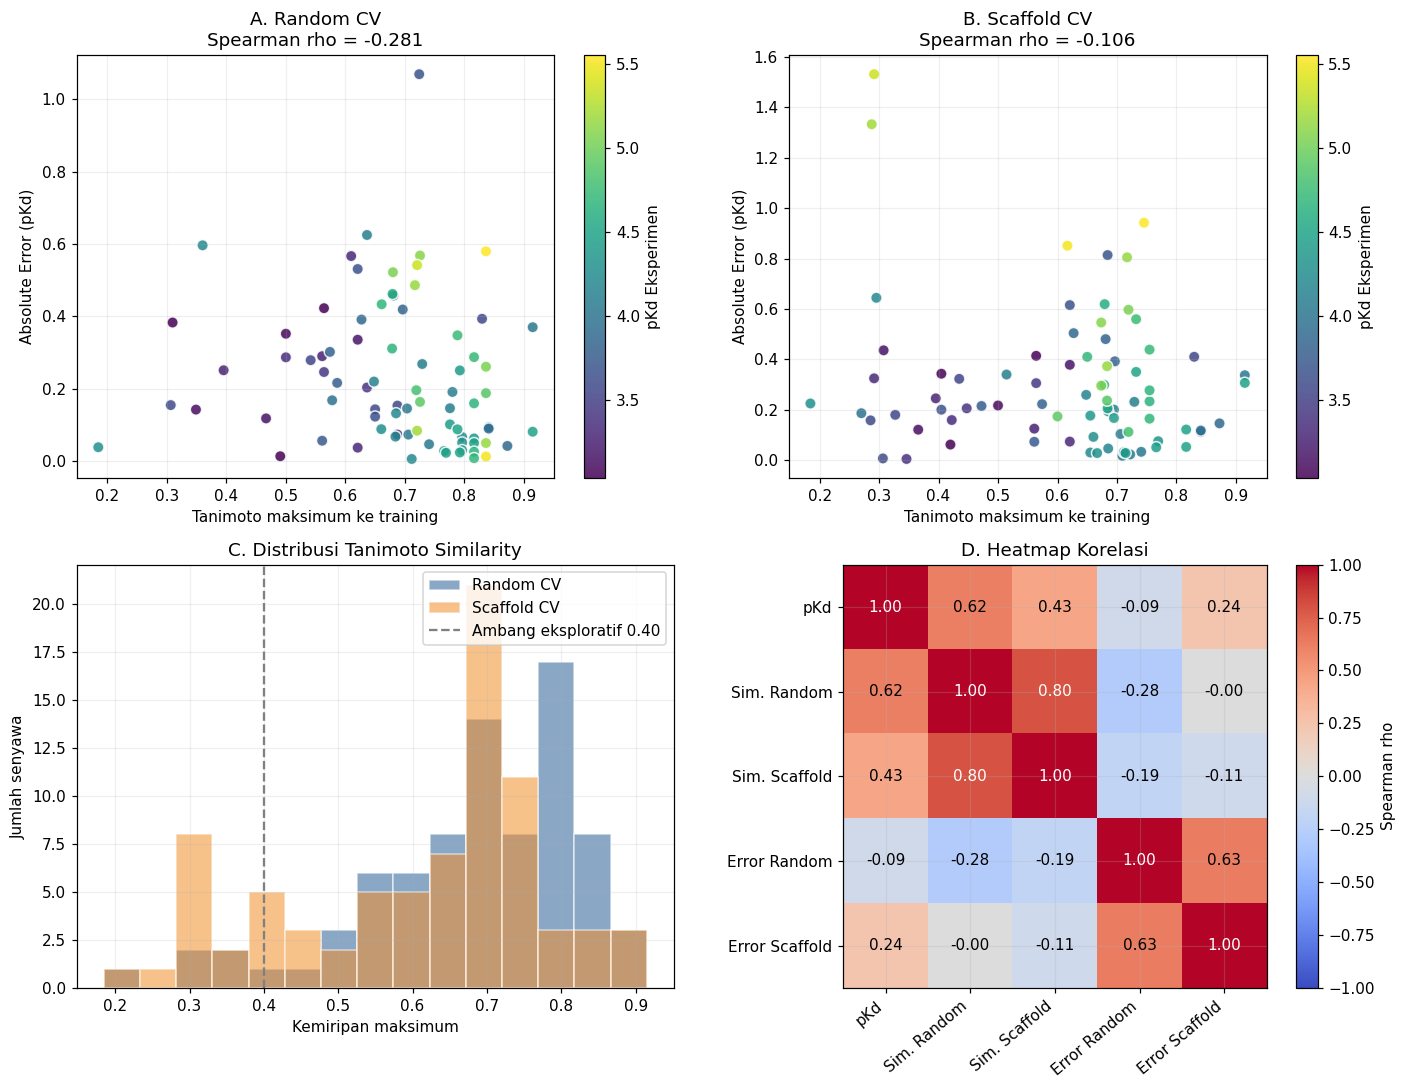

In [35]:

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

fig, axes = plt.subplots(2, 2, figsize=(13, 10))

# A. Random CV
sc1 = axes[0, 0].scatter(
    ad_df["Similarity_Random"],
    ad_df["Error_Random"],
    c=ad_df["pKd_eksperimen"],
    cmap="viridis",
    s=55,
    alpha=0.85,
    edgecolors="white"
)

axes[0, 0].set_title(
    f"A. Random CV\nSpearman rho = {rho_random:.3f}"
)
axes[0, 0].set_xlabel("Tanimoto maksimum ke training")
axes[0, 0].set_ylabel("Absolute Error (pKd)")
fig.colorbar(sc1, ax=axes[0, 0], label="pKd Eksperimen")

# B. Scaffold CV
sc2 = axes[0, 1].scatter(
    ad_df["Similarity_Scaffold"],
    ad_df["Error_Scaffold"],
    c=ad_df["pKd_eksperimen"],
    cmap="viridis",
    s=55,
    alpha=0.85,
    edgecolors="white"
)

axes[0, 1].set_title(
    f"B. Scaffold CV\nSpearman rho = {rho_scaffold:.3f}"
)
axes[0, 1].set_xlabel("Tanimoto maksimum ke training")
axes[0, 1].set_ylabel("Absolute Error (pKd)")
fig.colorbar(sc2, ax=axes[0, 1], label="pKd Eksperimen")

# C. Distribusi kemiripan
axes[1, 0].hist(
    sim_random,
    bins=15,
    alpha=0.65,
    color="#4C78A8",
    edgecolor="white",
    label="Random CV"
)

axes[1, 0].hist(
    sim_scaffold,
    bins=15,
    alpha=0.55,
    color="#F28E2B",
    edgecolor="white",
    label="Scaffold CV"
)

axes[1, 0].axvline(
    0.40, color="gray", linestyle="--",
    label="Ambang eksploratif 0.40"
)
axes[1, 0].set_title("C. Distribusi Tanimoto Similarity")
axes[1, 0].set_xlabel("Kemiripan maksimum")
axes[1, 0].set_ylabel("Jumlah senyawa")
axes[1, 0].legend()

# D. Heatmap korelasi antarvariabel
kolom = [
    "pKd_eksperimen",
    "Similarity_Random",
    "Similarity_Scaffold",
    "Error_Random",
    "Error_Scaffold"
]

corr = ad_df[kolom].corr(method="spearman")

ax = axes[1, 1]
im = ax.imshow(
    corr,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

nama = [
    "pKd",
    "Sim. Random",
    "Sim. Scaffold",
    "Error Random",
    "Error Scaffold"
]

ax.set_xticks(range(len(nama)))
ax.set_yticks(range(len(nama)))
ax.set_xticklabels(nama, rotation=40, ha="right")
ax.set_yticklabels(nama)

for i in range(len(nama)):
    for j in range(len(nama)):
        nilai = corr.iloc[i, j]
        ax.text(
            j, i, f"{nilai:.2f}",
            ha="center", va="center",
            color="white" if abs(nilai) > 0.65 else "black"
        )

fig.colorbar(im, ax=ax, label="Spearman rho")
ax.set_title("D. Heatmap Korelasi")

for a in axes.flat[:3]:
    a.grid(alpha=0.20)

plt.tight_layout()

plt.savefig(
    OUT / "Applicability_Domain_Visualisasi.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [36]:

# Kuartil berdasarkan kemiripan scaffold CV
ad_df["Kuartil_Similarity"] = pd.qcut(
    ad_df["Similarity_Scaffold"].rank(method="first"),
    q=4,
    labels=["Q1 Rendah", "Q2", "Q3", "Q4 Tinggi"]
)

ringkasan_ad = (
    ad_df
    .groupby("Kuartil_Similarity", observed=True)
    .agg(
        Jumlah=("Error_Scaffold", "size"),
        Median_Tanimoto=("Similarity_Scaffold", "median"),
        MAE_Scaffold=("Error_Scaffold", "mean"),
        Error_Maksimum=("Error_Scaffold", "max")
    )
    .round(4)
)

print("=== ERROR BERDASARKAN KUARTIL KEMIRIPAN ===")
display(ringkasan_ad)

ringkasan_ad.to_csv(
    OUT / "AD_Error_Berdasarkan_Kuartil.csv"
)


=== ERROR BERDASARKAN KUARTIL KEMIRIPAN ===


,Jumlah,Median_Tanimoto,MAE_Scaffold,Error_Maksimum
Kuartil_Similarity,,,,
Q1 Rendah,20,0.3367,0.3457,1.5316
Q2,20,0.6207,0.2798,0.8514
Q3,20,0.6901,0.3139,0.8142
Q4 Tinggi,20,0.7603,0.2497,0.9424



### 12.2 Hasil dan Interpretasi Applicability Domain

Analisis Applicability Domain (AD) dilakukan pada 80 senyawa inhibitor USP5 menggunakan Morgan Binary Fingerprint (radius 2, 2048 bit) dan Tanimoto Similarity.

Kemiripan maksimum dihitung terhadap senyawa training pada setiap fold. Analisis dilakukan menggunakan prediksi out-of-fold Ensemble B dari Random 5-Fold CV (seed 200) dan Scaffold 5-Fold CV.

#### A. Hasil Kemiripan dan Korelasi Error

| Parameter | Random CV | Scaffold CV |
|---|---:|---:|
| Median Tanimoto | 0,7048 | 0,6735 |
| Spearman ρ | -0,2813 | -0,1059 |
| p-value | 0,0115 | 0,3498 |
| Jumlah senyawa dengan Tanimoto < 0,40 | 6 | 13 |

**Interpretasi:**

1. Random CV menghasilkan median Tanimoto lebih tinggi dibandingkan Scaffold CV, menunjukkan bahwa senyawa validasi pada pembagian acak cenderung memiliki kemiripan fingerprint yang lebih tinggi terhadap data training.

2. Pada Random CV, terdapat korelasi negatif yang lemah antara kemiripan molekul dan kesalahan absolut prediksi (ρ = -0,2813; p = 0,0115). Hubungan ini signifikan secara statistik pada taraf 0,05.

3. Pada Scaffold CV, korelasi yang diperoleh sangat lemah (ρ = -0,1059; p = 0,3498) dan tidak signifikan secara statistik.

4. Jumlah senyawa dengan kemiripan Tanimoto di bawah 0,40 meningkat dari 6 pada Random CV menjadi 13 pada Scaffold CV.

5. Hasil menunjukkan bahwa penggunaan scaffold-based splitting meningkatkan tantangan generalisasi struktural dibandingkan pembagian acak, tetapi hubungan kemiripan dan kesalahan prediksi belum konsisten pada seluruh kondisi.

---

### 12.3 Interpretasi Visualisasi Applicability Domain

#### A. Scatter Plot Random CV

Scatter plot menunjukkan kecenderungan hubungan negatif antara kemiripan maksimum Tanimoto dan kesalahan absolut prediksi.

Senyawa dengan kemiripan lebih tinggi cenderung memiliki kesalahan lebih kecil, meskipun masih terdapat beberapa senyawa dengan error cukup tinggi pada tingkat kemiripan sedang hingga tinggi.

#### B. Scatter Plot Scaffold CV

Pada Scaffold CV, hubungan antara kemiripan molekul dan error tampak lebih lemah.

Beberapa senyawa dengan kemiripan rendah menunjukkan error besar, tetapi terdapat pula senyawa dengan kemiripan relatif tinggi yang tetap mengalami kesalahan prediksi.

Hal ini menunjukkan bahwa tingkat kemiripan fingerprint tidak cukup untuk menjelaskan seluruh variasi kesalahan model.

#### C. Distribusi Tanimoto Similarity

Distribusi menunjukkan bahwa senyawa pada Scaffold CV lebih banyak berada pada rentang kemiripan rendah dibandingkan Random CV.

Ambang Tanimoto 0,40 digunakan sebagai batas eksploratif untuk mengidentifikasi senyawa dengan kemiripan rendah. Ambang ini belum divalidasi sebagai batas keandalan prediksi model.

#### D. Heatmap Korelasi

Heatmap memperlihatkan beberapa hubungan antarvariabel:

- Kemiripan Random dan Scaffold CV memiliki korelasi positif yang kuat (ρ ≈ 0,80).
- Kemiripan Random CV dan error Random CV memiliki korelasi sekitar -0,28.
- Kemiripan Scaffold CV dan error Scaffold CV memiliki korelasi sekitar -0,11.
- pKd eksperimen dan error Scaffold CV memiliki korelasi positif sekitar +0,24.

Hasil ini mengindikasikan bahwa kesalahan prediksi dapat berkaitan dengan kemiripan struktur maupun rentang aktivitas senyawa.

Namun, korelasi tersebut tidak membuktikan hubungan sebab-akibat.

---

### 12.4 Analisis Error Berdasarkan Kuartil Kemiripan

Senyawa dibagi menjadi empat kelompok berdasarkan tingkat kemiripan maksimum Tanimoto pada Scaffold CV.

| Kuartil | Jumlah Senyawa | Median Tanimoto | MAE Scaffold |
|---|---:|---:|---:|
| Q1 — Kemiripan rendah | 20 | 0,3367 | 0,3457 |
| Q2 | 20 | 0,6207 | 0,2798 |
| Q3 | 20 | 0,6901 | 0,3139 |
| Q4 — Kemiripan tinggi | 20 | 0,7603 | 0,2497 |

**Interpretasi:**

1. Kelompok Q1 memiliki MAE tertinggi sebesar 0,3457, menunjukkan kesalahan rata-rata yang relatif besar pada senyawa dengan kemiripan terendah.

2. Kelompok Q4 menghasilkan MAE terendah sebesar 0,2497, menunjukkan performa relatif lebih baik pada kelompok dengan kemiripan tertinggi.

3. Perubahan MAE tidak berlangsung secara monoton karena Q3 menghasilkan MAE lebih tinggi daripada Q2.

4. Pola tersebut menunjukkan bahwa kemiripan struktur dapat berkaitan dengan performa prediksi, tetapi bukan satu-satunya faktor yang menentukan besarnya error.

---

### 12.5 Hubungan dengan Temuan Tahap Sebelumnya

Pada Tahap 9–11 ditemukan bahwa model mengalami kesalahan prediksi yang lebih besar pada senyawa dengan pKd ≥ 5.

Hasil Applicability Domain menunjukkan bahwa hubungan kemiripan struktur dan kesalahan prediksi pada Scaffold CV relatif lemah dan tidak signifikan.

Dengan demikian, kesalahan besar pada senyawa ber-pKd tinggi belum dapat dijelaskan hanya berdasarkan kemiripan fingerprint terhadap data training.

Faktor lain yang perlu dipertimbangkan meliputi distribusi aktivitas, representasi fitur molekul, dan hubungan struktur–aktivitas yang belum sepenuhnya dipelajari model.

---

### 12.6 Kesimpulan Tahap 12

1. Random CV menunjukkan korelasi negatif yang lemah tetapi signifikan antara Tanimoto Similarity dan kesalahan prediksi.

2. Scaffold CV menghasilkan korelasi yang sangat lemah dan tidak signifikan, sehingga kemiripan struktur belum dapat digunakan sebagai indikator tunggal keandalan prediksi.

3. Scaffold CV memiliki lebih banyak senyawa dengan kemiripan rendah terhadap data training.

4. Kelompok dengan kemiripan tertinggi memiliki MAE paling rendah, tetapi hubungan antar-kuartil tidak menunjukkan pola yang konsisten.

5. Analisis AD berbasis Tanimoto memberikan informasi tambahan mengenai keterwakilan struktur molekul, tetapi belum menghasilkan batas Applicability Domain yang tervalidasi secara prospektif.

**Kesimpulan utama:** Kemampuan generalisasi Ensemble B tidak hanya dipengaruhi oleh kemiripan struktur molekul. Prediksi senyawa dengan pKd tinggi tetap menjadi keterbatasan penting yang perlu dipertimbangkan dalam interpretasi hasil penelitian.

**Tahap berikutnya:** Interpretasi Model dan Identifikasi Fitur Molekul yang Berpengaruh terhadap Prediksi pKd.



## 13. Interpretasi Model — Analisis Feature Importance

### 13.1 Tujuan

Analisis interpretasi model dilakukan untuk mengidentifikasi fitur molekul yang berkontribusi terhadap kemampuan prediksi pKd inhibitor USP5.

Tahap ini melanjutkan hasil screening algoritma, evaluasi ensemble, scaffold cross-validation, analisis residual, dan applicability domain.

### Metode Interpretasi

Metode yang digunakan adalah **Permutation Feature Importance**, yaitu mengukur perubahan performa prediksi ketika nilai suatu fitur diacak pada data validasi.

Apabila pengacakan fitur meningkatkan kesalahan prediksi, fitur tersebut dianggap memberikan informasi penting bagi model.

### Model yang Dianalisis

1. Ridge Regression.
2. Bayesian Ridge.
3. Ensemble B (Ridge + Bayesian Ridge + XGBoost).

### Representasi Molekul

- Morgan Count Fingerprint: 1.024 fitur.
- MACCS Keys: 167 fitur.
- Total: 1.191 fitur.

### Mengapa Analisis Ini Diperlukan?

Nilai R² dan RMSE menunjukkan seberapa baik model memprediksi aktivitas, tetapi tidak menjelaskan informasi molekul yang digunakan untuk menghasilkan prediksi.

Analisis feature importance membantu mengidentifikasi fitur yang berperan dalam prediksi serta mengevaluasi apakah model lebih bergantung pada Morgan Fingerprint atau MACCS Keys.

### Batasan Interpretasi

Fingerprint merupakan representasi komputasional struktur kimia. Nilai importance tidak langsung membuktikan hubungan sebab-akibat dengan aktivitas biologis.

Analisis dilakukan pada data validasi yang tidak digunakan untuk fitting model, dan hasilnya bersifat eksploratif karena dataset sebelumnya telah digunakan untuk pemilihan model.


In [37]:

import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.metrics import mean_squared_error

# Verifikasi dataset
assert X_model.shape == (80, 1191)
assert len(y_model) == 80

# Stratifikasi kuartil pKd, seperti Tahap 10
bins_13 = np.digitize(
    y_model,
    np.quantile(y_model, [0.25, 0.50, 0.75])
)

splitter_13 = StratifiedShuffleSplit(
    n_splits=1,
    test_size=16,
    random_state=42
)

tr13, te13 = next(
    splitter_13.split(X_model, bins_13)
)

X_train13 = X_model[tr13]
X_valid13 = X_model[te13]
y_train13 = y_model[tr13]
y_valid13 = y_model[te13]

# Latih anggota model
model13 = {}

for nama in ["Ridge", "Bayesian Ridge", "XGBoost"]:
    mdl = build_model(nama)
    mdl.fit(X_train13, y_train13)
    model13[nama] = mdl

def prediksi13(nama, Xm):
    if nama == "Ensemble B":
        return np.mean([
            np.asarray(model13[m].predict(Xm)).reshape(-1)
            for m in ["Ridge", "Bayesian Ridge", "XGBoost"]
        ], axis=0)

    return np.asarray(
        model13[nama].predict(Xm)
    ).reshape(-1)

# Kelompok fitur sesuai X_model
blok_fitur = {
    "Morgan Fingerprint": np.arange(0, 1024),
    "MACCS Keys": np.arange(1024, 1191)
}

rng13 = np.random.default_rng(42)
hasil_importance13 = []

for nama in ["Ridge", "Bayesian Ridge", "Ensemble B"]:
    pred_asli = prediksi13(nama, X_valid13)
    mse_asli = mean_squared_error(y_valid13, pred_asli)

    for blok, indeks in blok_fitur.items():
        perubahan = []

        for ulang in range(30):
            X_acak = X_valid13.copy()

            urutan = rng13.permutation(len(X_valid13))
            X_acak[:, indeks] = X_valid13[urutan][:, indeks]

            pred_acak = prediksi13(nama, X_acak)
            mse_acak = mean_squared_error(y_valid13, pred_acak)

            perubahan.append(mse_acak - mse_asli)

        hasil_importance13.append({
            "Model": nama,
            "Blok_Fitur": blok,
            "Importance_Mean": np.mean(perubahan),
            "Importance_SD": np.std(perubahan, ddof=1),
            "MSE_Asli": mse_asli
        })

importance_blok13 = pd.DataFrame(hasil_importance13)

print("=== PERMUTATION IMPORTANCE USP5 ===")
print("Training:", len(tr13), "senyawa")
print("Validasi:", len(te13), "senyawa")

display(importance_blok13.round(5))

importance_blok13.to_csv(
    OUT / "Importance_Blok_Fitur_USP5.csv",
    index=False
)


=== PERMUTATION IMPORTANCE USP5 ===
Training: 64 senyawa
Validasi: 16 senyawa


,Model,Blok_Fitur,Importance_Mean,Importance_SD,MSE_Asli
0,Ridge,Morgan Fingerprint,0.27335,0.08070,0.06958
1,Ridge,MACCS Keys,0.20574,0.06736,0.06958
2,Bayesian Ridge,Morgan Fingerprint,0.27228,0.07880,0.06827
3,Bayesian Ridge,MACCS Keys,0.18325,0.06485,0.06827
4,Ensemble B,Morgan Fingerprint,0.30219,0.07748,0.06957
5,Ensemble B,MACCS Keys,0.17920,0.05564,0.06957


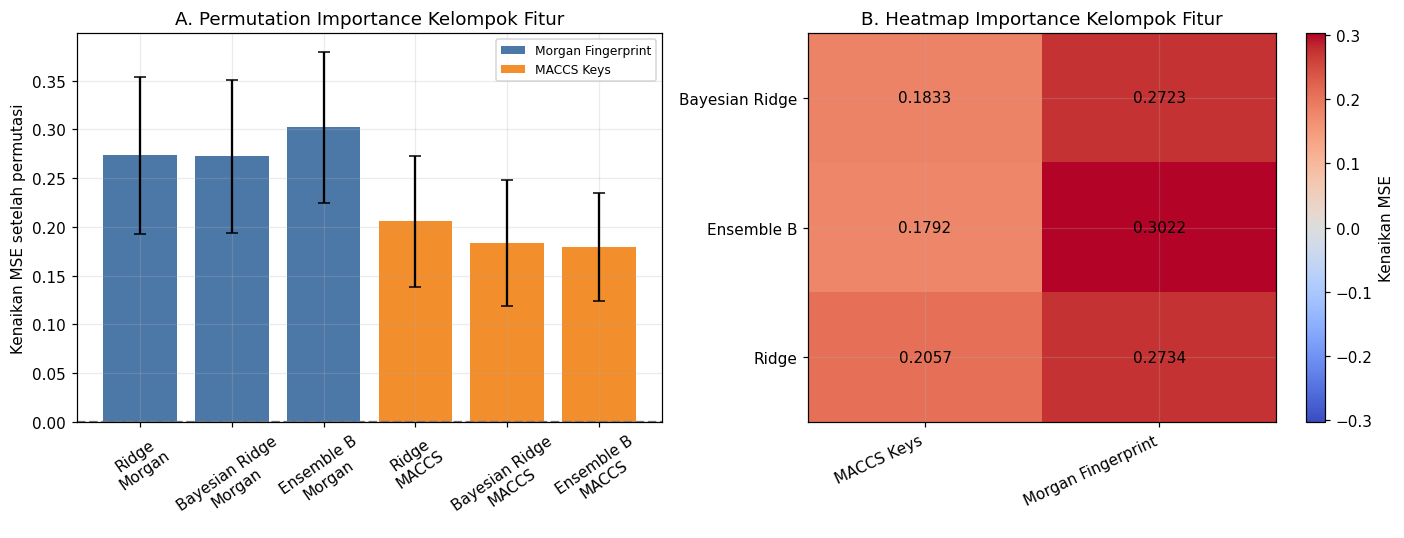

In [38]:

import matplotlib.pyplot as plt

# Heatmap kelompok fitur
pivot13 = importance_blok13.pivot(
    index="Model",
    columns="Blok_Fitur",
    values="Importance_Mean"
)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Grafik batang
colors = {
    "Morgan Fingerprint": "#4C78A8",
    "MACCS Keys": "#F28E2B"
}

for blok in blok_fitur:
    d = importance_blok13[
        importance_blok13["Blok_Fitur"] == blok
    ]
    axes[0].bar(
        [f"{m}\n{blok.split()[0]}" for m in d["Model"]],
        d["Importance_Mean"],
        yerr=d["Importance_SD"],
        capsize=4,
        color=colors[blok],
        label=blok
    )

axes[0].axhline(0, color="gray", linestyle="--")
axes[0].set_title("A. Permutation Importance Kelompok Fitur")
axes[0].set_ylabel("Kenaikan MSE setelah permutasi")
axes[0].tick_params(axis="x", labelrotation=35)
axes[0].legend(fontsize=8)

# Heatmap
v = np.max(np.abs(pivot13.to_numpy()))
v = max(v, 1e-9)

im = axes[1].imshow(
    pivot13.to_numpy(),
    cmap="coolwarm",
    vmin=-v,
    vmax=v,
    aspect="auto"
)

axes[1].set_xticks(range(len(pivot13.columns)))
axes[1].set_yticks(range(len(pivot13.index)))
axes[1].set_xticklabels(pivot13.columns, rotation=25, ha="right")
axes[1].set_yticklabels(pivot13.index)

for i in range(len(pivot13.index)):
    for j in range(len(pivot13.columns)):
        axes[1].text(
            j, i,
            f"{pivot13.iloc[i, j]:.4f}",
            ha="center",
            va="center",
            color="black"
        )

axes[1].set_title("B. Heatmap Importance Kelompok Fitur")
fig.colorbar(im, ax=axes[1], label="Kenaikan MSE")

plt.tight_layout()
plt.savefig(
    OUT / "Importance_Blok_Heatmap_USP5.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


=== 15 FITUR PALING INFORMATIF ===


,Fitur,Importance,SD,Jenis
573,Morgan_573,0.01432,0.01002,Morgan
290,Morgan_290,0.00421,0.00136,Morgan
879,Morgan_879,0.00412,0.00110,Morgan
802,Morgan_802,0.00408,0.00259,Morgan
1122,MACCS_98,0.00391,0.00185,MACCS
797,Morgan_797,0.00348,0.00225,Morgan
63,Morgan_63,0.00345,0.00115,Morgan
961,Morgan_961,0.00337,0.00160,Morgan
594,Morgan_594,0.00327,0.00343,Morgan
301,Morgan_301,0.00319,0.00086,Morgan


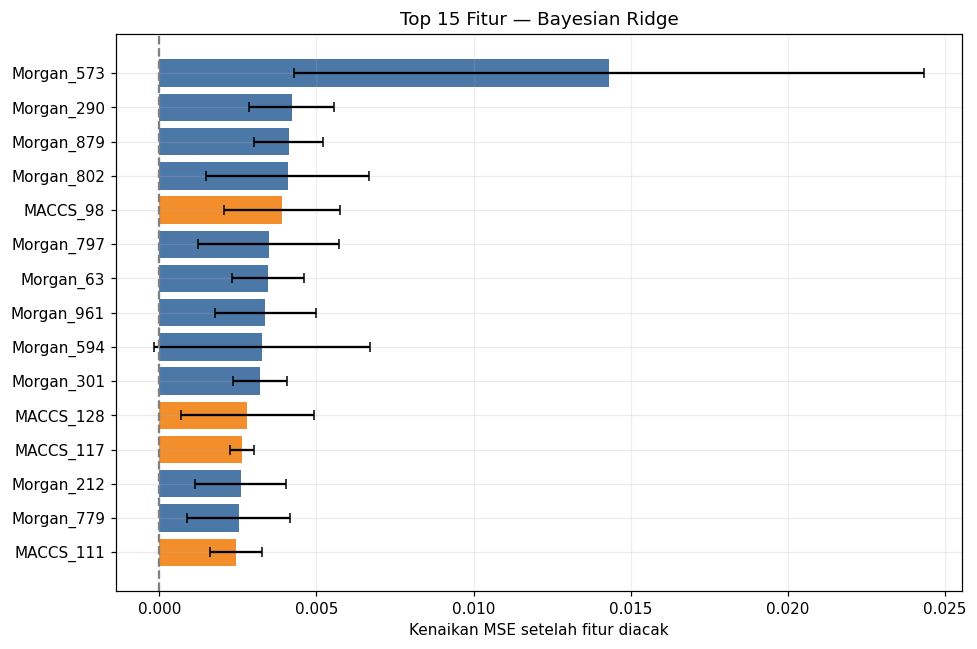

In [40]:

from sklearn.inspection import permutation_importance

# Mengukur importance pada 16 senyawa validasi
hasil_pi13 = permutation_importance(
    model13["Bayesian Ridge"],
    X_valid13,
    y_valid13,
    scoring="neg_mean_squared_error",
    n_repeats=5,
    random_state=42,
    n_jobs=1
)

nama_fitur13 = (
    [f"Morgan_{i}" for i in range(1024)] +
    [f"MACCS_{i}" for i in range(167)]
)

importance_individu13 = pd.DataFrame({
    "Fitur": nama_fitur13,
    "Importance": hasil_pi13.importances_mean,
    "SD": hasil_pi13.importances_std
})

importance_individu13["Jenis"] = np.where(
    importance_individu13["Fitur"].str.startswith("Morgan"),
    "Morgan", "MACCS"
)

top15_13 = (
    importance_individu13
    .sort_values("Importance", ascending=False)
    .head(15)
)

print("=== 15 FITUR PALING INFORMATIF ===")
display(top15_13.round(5))

# Grafik horizontal
plot13 = top15_13.iloc[::-1]

warna13 = [
    "#4C78A8" if jenis == "Morgan" else "#F28E2B"
    for jenis in plot13["Jenis"]
]

fig, ax = plt.subplots(figsize=(9, 6))

ax.barh(
    plot13["Fitur"],
    plot13["Importance"],
    xerr=plot13["SD"],
    color=warna13,
    capsize=3
)

ax.axvline(0, color="gray", linestyle="--")
ax.set_title("Top 15 Fitur — Bayesian Ridge")
ax.set_xlabel("Kenaikan MSE setelah fitur diacak")
ax.grid(axis="x", alpha=0.2)

plt.tight_layout()
plt.savefig(
    OUT / "Top15_Fitur_Bayesian_Ridge.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

importance_individu13.to_csv(
    OUT / "Importance_Individual_Bayesian_Ridge.csv",
    index=False
)




### 13.2 Hasil dan Interpretasi Feature Importance

Analisis feature importance dilakukan menggunakan metode permutation importance untuk mengevaluasi kontribusi fitur molekul terhadap prediksi pKd inhibitor USP5.

Pengujian menggunakan 64 senyawa training dan 16 senyawa validasi dengan pembagian stratifikasi berdasarkan kuartil pKd.

Representasi molekul terdiri atas Morgan Count Fingerprint (1.024 fitur) dan MACCS Keys (167 fitur).

#### A. Hasil Permutation Importance Kelompok Fitur

| Model | Morgan Fingerprint | MACCS Keys |
|---|---:|---:|
| Ridge Regression | 0,2734 | 0,2057 |
| Bayesian Ridge | 0,2723 | 0,1833 |
| Ensemble B | 0,3022 | 0,1792 |

Nilai importance menunjukkan rata-rata kenaikan Mean Squared Error (MSE) setelah kelompok fitur diacak pada data validasi.

**Interpretasi:**

1. Kelompok Morgan Fingerprint menghasilkan kenaikan MSE yang lebih besar daripada MACCS Keys pada ketiga model.

2. Ensemble B menunjukkan nilai importance Morgan tertinggi sebesar 0,3022.

3. MACCS Keys tetap memberikan kontribusi positif terhadap prediksi, sehingga kedua representasi molekul menyediakan informasi yang berguna.

4. Perbedaan importance tidak dapat langsung diartikan sebagai keunggulan per fitur karena jumlah fitur Morgan dan MACCS berbeda.

5. Hasil merupakan pengujian pada satu pembagian validasi berisi 16 senyawa, sehingga kestabilan ranking perlu dievaluasi pada pembagian lain.

---

### 13.3 Identifikasi Fitur Individual pada Bayesian Ridge

Permutation importance individual digunakan untuk mengidentifikasi fitur yang paling informatif pada Bayesian Ridge.

#### Lima Fitur dengan Importance Tertinggi

| Peringkat | Fitur | Importance | SD |
|---|---|---:|---:|
| 1 | Morgan_573 | 0,01432 | 0,01002 |
| 2 | Morgan_290 | 0,00421 | 0,00136 |
| 3 | Morgan_879 | 0,00412 | 0,00110 |
| 4 | Morgan_802 | 0,00408 | 0,00259 |
| 5 | MACCS_98 | 0,00391 | 0,00185 |

**Interpretasi:**

1. Morgan_573 menghasilkan nilai permutation importance tertinggi, sehingga pengacakan fitur tersebut memberikan peningkatan MSE terbesar dalam pengujian ini.

2. Morgan Fingerprint mendominasi lima fitur teratas, sedangkan MACCS_98 juga menunjukkan kontribusi terhadap performa prediksi.

3. Standar deviasi Morgan_573 relatif besar dibandingkan nilai importance rata-ratanya. Hal ini menunjukkan variasi hasil antar-pengulangan permutasi.

4. Fitur fingerprint yang saling berkorelasi dapat berbagi informasi, sehingga nilai permutation importance individual tidak selalu mencerminkan seluruh kontribusi kimiawinya.

5. Identitas gugus fungsi atau lingkungan atom yang terkait dengan fitur fingerprint belum dapat dipastikan hanya berdasarkan indeks fitur.

---

### 13.4 Hubungan dengan Hasil Pemodelan Sebelumnya

Pada Tahap 5, kombinasi Morgan Fingerprint dan MACCS Keys menghasilkan performa screening tertinggi untuk beberapa algoritma, termasuk Ridge Regression.

Hasil Tahap 13 menunjukkan bahwa kedua kelompok fitur memiliki kontribusi positif terhadap prediksi.

Temuan ini mendukung penggunaan kombinasi Morgan dan MACCS pada model penelitian, tetapi belum membuktikan bahwa kombinasi tersebut merupakan representasi optimal untuk seluruh algoritma dan seluruh pembagian data.

Analisis importance juga tidak membuktikan bahwa fitur yang teridentifikasi secara langsung menyebabkan peningkatan afinitas inhibitor terhadap USP5.

---

### 13.5 Kesimpulan Tahap 13

1. Morgan Fingerprint menunjukkan kontribusi kelompok lebih besar dibandingkan MACCS Keys berdasarkan permutation importance pada pengujian ini.

2. Kedua representasi molekul memberikan informasi yang membantu prediksi pKd.

3. Morgan_573 menjadi fitur individual dengan importance tertinggi pada Bayesian Ridge.

4. Nilai importance individual masih perlu ditafsirkan secara hati-hati karena jumlah data validasi terbatas dan terdapat kemungkinan korelasi antarf fitur.

5. Analisis ini menunjukkan informasi molekul yang digunakan model untuk prediksi, bukan bukti langsung mengenai mekanisme penghambatan USP5.

**Tahap berikutnya:** Pelatihan Model Final dan Penyimpanan Model untuk Prediksi Senyawa Baru.



## 14. Pelatihan Model Final dan Penyimpanan

### 14.1 Tujuan

Tahap ini bertujuan melatih kembali model machine learning pada seluruh 80 senyawa inhibitor USP5 dan menyimpan model untuk penggunaan berikutnya.

Model yang dipertahankan berdasarkan hasil evaluasi sebelumnya adalah:

1. **Ridge Regression:** kandidat terbaik screening awal.
2. **Bayesian Ridge:** performa scaffold CV tertinggi.
3. **Ensemble B:** kombinasi Ridge, Bayesian Ridge, dan XGBoost, dengan performa terbaik pada repeated random CV dan hold-out.

### Mengapa Dilatih Menggunakan 80 Senyawa?

Setelah evaluasi cross-validation selesai, seluruh data yang tersedia dapat digunakan untuk melatih model operasional agar informasi dari 80 senyawa dimanfaatkan.

Model final digunakan untuk prediksi senyawa baru, sedangkan performa yang dilaporkan tetap berasal dari validasi sebelumnya.

**Penting:** R² dan RMSE pada data training tidak digunakan untuk menyatakan performa generalisasi model.


In [41]:

import numpy as np
import pandas as pd
import joblib
import sklearn
import rdkit
import xgboost
from pathlib import Path
from sklearn.metrics import r2_score, mean_squared_error

OUT = Path("/data/Aliya/model/Hasil_Ensemble_80")
OUT.mkdir(parents=True, exist_ok=True)

assert X_model.shape == (80, 1191)
assert len(y_model) == 80
assert np.isfinite(X_model).all()

# Training seluruh 80 senyawa
final_models = {}

for nama in ["Ridge", "Bayesian Ridge", "XGBoost"]:
    model = build_model(nama)
    model.fit(X_model, y_model)
    final_models[nama] = model
    print(nama, "selesai dilatih")

# Fungsi prediksi Ensemble B
def prediksi_ensemble_final(X_input):
    prediksi = [
        np.asarray(final_models[nama].predict(X_input)).reshape(-1)
        for nama in ["Ridge", "Bayesian Ridge", "XGBoost"]
    ]
    return np.mean(prediksi, axis=0)

# Sanity check saja, bukan performa validasi
pred_train = prediksi_ensemble_final(X_model)

print("\n=== SANITY CHECK MODEL FINAL ===")
print("R2 training:", round(r2_score(y_model, pred_train), 4))
print(
    "RMSE training:",
    round(np.sqrt(mean_squared_error(y_model, pred_train)), 4)
)

# Simpan seluruh model dan spesifikasi fiturnya
bundle = {
    "models": final_models,
    "ensemble_members": ["Ridge", "Bayesian Ridge", "XGBoost"],
    "ensemble_method": "equal_weight_average",
    "feature_spec": {
        "order": ["Morgan_Count", "MACCS"],
        "morgan_radius": 2,
        "morgan_bits": 1024,
        "maccs_bits": 167
    },
    "training_data": {
        "n_compounds": 80,
        "chembl_id": df["chembl_id"].tolist()
    },
    "versions": {
        "sklearn": sklearn.__version__,
        "rdkit": rdkit.__version__,
        "xgboost": xgboost.__version__
    },
    "evaluation_note": (
        "Performance reported from CV and repeated hold-out, "
        "not from full-data training scores."
    )
}

MODEL_PATH = OUT / "USP5_Model_Final_80.joblib"
joblib.dump(bundle, MODEL_PATH)

print("\n=== MODEL FINAL BERHASIL DISIMPAN ===")
print("Lokasi:", MODEL_PATH)
print("Jumlah senyawa training:", len(y_model))
print("Model tersimpan:", list(final_models.keys()))


Ridge selesai dilatih
Bayesian Ridge selesai dilatih
XGBoost selesai dilatih

=== SANITY CHECK MODEL FINAL ===
R2 training: 0.9944
RMSE training: 0.0476

=== MODEL FINAL BERHASIL DISIMPAN ===
Lokasi: /data/Aliya/model/Hasil_Ensemble_80/USP5_Model_Final_80.joblib
Jumlah senyawa training: 80
Model tersimpan: ['Ridge', 'Bayesian Ridge', 'XGBoost']


In [42]:

# Baca kembali file yang baru kita simpan sendiri
bundle_check = joblib.load(MODEL_PATH)

models_check = bundle_check["models"]
members_check = bundle_check["ensemble_members"]

pred_check = np.mean([
    np.asarray(
        models_check[nama].predict(X_model[:5])
    ).reshape(-1)
    for nama in members_check
], axis=0)

pred_asli = prediksi_ensemble_final(X_model[:5])

assert np.allclose(pred_check, pred_asli)

print("=== VERIFIKASI MODEL FINAL ===")
print("File model: BERHASIL DIMUAT")
print("Prediksi setelah dimuat: SESUAI")
print("Jumlah prediksi uji:", len(pred_check))
print("Prediksi contoh:", np.round(pred_check, 4))


=== VERIFIKASI MODEL FINAL ===
File model: BERHASIL DIMUAT
Prediksi setelah dimuat: SESUAI
Jumlah prediksi uji: 5
Prediksi contoh: [3.0789 3.0487 3.0914 3.1143 3.1353]



## 15. Perbandingan Akhir Performa Model USP5

### 15.1 Tujuan

Tahap ini membandingkan hasil pemodelan machine learning yang dikembangkan pada penelitian ini dengan model ML Ensemble referensi Pak Ridwan dan GraphConvModel (GNN) sebelumnya.

Perbandingan mencakup:

1. Repeated Random Cross-Validation.
2. Scaffold Cross-Validation.
3. Repeated Hold-Out 64/16.

Metrik evaluasi yang digunakan adalah R², RMSE, dan MAE.

### Dasar Perbandingan

Model penelitian ini dikembangkan melalui screening algoritma dan evaluasi lanjutan menggunakan dataset 80 senyawa USP5.

Hasil referensi Pak Ridwan dan GraphConvModel digunakan sebagai pembanding deskriptif.

Karena terdapat perbedaan algoritma, representasi fitur, dan protokol evaluasi, perbandingan antarpenelitian tidak secara otomatis menunjukkan peningkatan performa yang signifikan.

Nilai cross-validation dan hold-out berulang pada penelitian ini merupakan evaluasi internal, bukan pengujian eksternal independen.


In [43]:

import pandas as pd
import numpy as np

# Data penelitian sendiri dari tahap sebelumnya
# Repeated random CV menggunakan 5 seed
data_random = scores_df[
    (scores_df["Protokol"] == "random") &
    (scores_df["Seed"].isin([200, 201, 202, 203, 204]))
].copy()

data_scaffold = scores_df[
    scores_df["Protokol"] == "scaffold"
].copy()

# Bayesian Ridge dari analisis anggota model Tahap 9
data_bayes_scaffold = metrik_anggota[
    metrik_anggota["Model"] == "Bayesian Ridge"
].copy()

records_15 = []

def tambah(nama, protokol, r2, rmse, mae):
    records_15.append({
        "Model": nama,
        "Protokol": protokol,
        "R2": float(r2),
        "RMSE": float(rmse),
        "MAE": float(mae)
    })

# Hasil Random CV
for nama, d in data_random.groupby("Model"):
    tambah(
        nama, "Repeated Random CV",
        d["R2"].mean(),
        d["RMSE"].mean(),
        d["MAE"].mean()
    )

# Hasil Scaffold CV
for _, d in data_scaffold.iterrows():
    tambah(
        d["Model"], "Scaffold CV",
        d["R2"], d["RMSE"], d["MAE"]
    )

# Tambahkan Bayesian Ridge pada Scaffold CV
for _, d in data_bayes_scaffold.iterrows():
    tambah(
        "Bayesian Ridge", "Scaffold CV",
        d["R2"], d["RMSE"], d["MAE"]
    )

# Hasil Hold-Out 20 split
for nama, d in holdout_df.groupby("Model"):
    tambah(
        nama, "Hold-Out 64/16",
        d["R2"].mean(),
        d["RMSE"].mean(),
        d["MAE"].mean()
    )

# Referensi Pak Ridwan dari notebook asli
referensi = [
    ("ML Ensemble Pak Ridwan", "Repeated Random CV",
     0.7656, 0.3064, 0.2336),
    ("ML Ensemble Pak Ridwan", "Scaffold CV",
     0.5805, 0.4102, 0.2992),
    ("ML Ensemble Pak Ridwan", "Hold-Out 64/16",
     0.7960, 0.2639, 0.2100)
]

for nama, protokol, r2, rmse, mae in referensi:
    tambah(nama, protokol, r2, rmse, mae)

tabel_final15 = pd.DataFrame(records_15)

print("=== TABEL PERBANDINGAN AKHIR USP5 ===")
display(
    tabel_final15.sort_values(
        ["Protokol", "R2"],
        ascending=[True, False]
    ).round(4)
)

tabel_final15.to_csv(
    OUT / "USP5_Tabel_Perbandingan_Akhir.csv",
    index=False
)

print("Tabel perbandingan berhasil disimpan")


=== TABEL PERBANDINGAN AKHIR USP5 ===


,Model,Protokol,R2,RMSE,MAE
12,ML Ensemble Pak Ridwan,Hold-Out 64/16,0.7960,0.2639,0.2100
8,Ensemble B,Hold-Out 64/16,0.7792,0.2723,0.2155
9,Ridge Tunggal,Hold-Out 64/16,0.7710,0.2777,0.2186
7,Bayesian Ridge,Hold-Out 64/16,0.7681,0.2802,0.2217
10,ML Ensemble Pak Ridwan,Repeated Random CV,0.7656,0.3064,0.2336
1,Ensemble B,Repeated Random CV,0.7578,0.3115,0.2358
0,Ensemble A,Repeated Random CV,0.7497,0.3165,0.2403
2,Ridge Tunggal,Repeated Random CV,0.7486,0.3171,0.2416
6,Bayesian Ridge,Scaffold CV,0.5954,0.4029,0.2804
3,Ridge Tunggal,Scaffold CV,0.5945,0.4033,0.2866


Tabel perbandingan berhasil disimpan


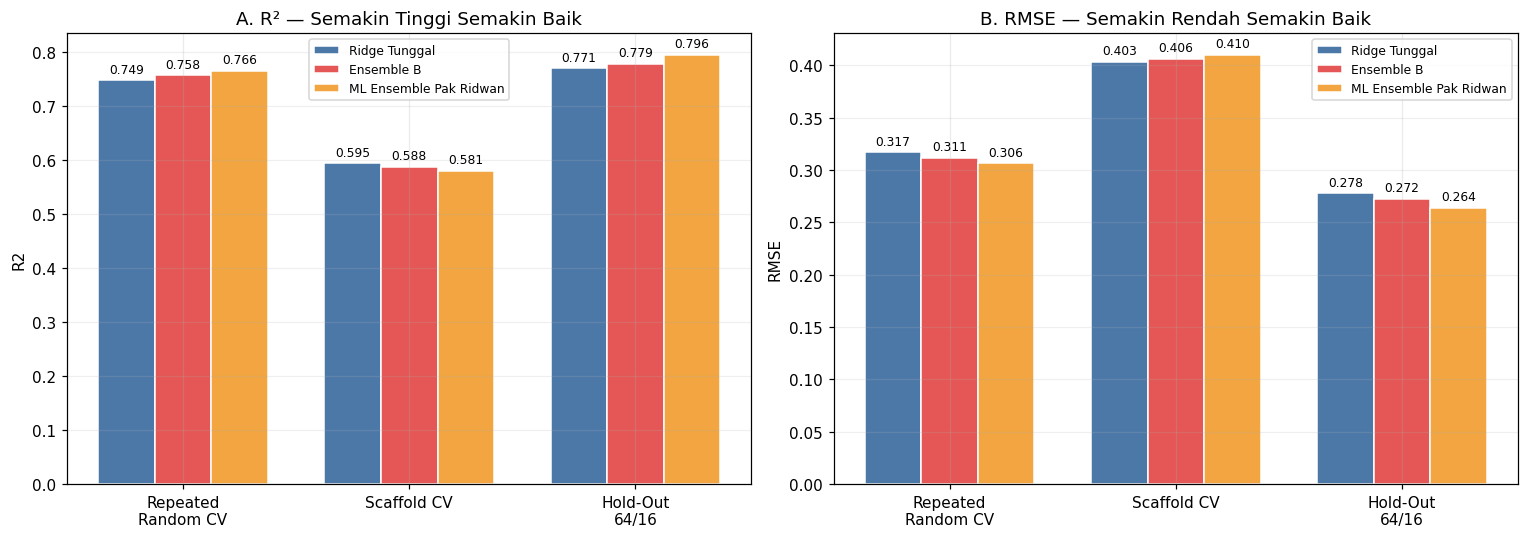

In [44]:

import matplotlib.pyplot as plt
import numpy as np

# Fokus pada dua kandidat dan model referensi
pilihan = [
    "Ridge Tunggal",
    "Ensemble B",
    "ML Ensemble Pak Ridwan"
]

urutan = [
    "Repeated Random CV",
    "Scaffold CV",
    "Hold-Out 64/16"
]

plot15 = tabel_final15[
    tabel_final15["Model"].isin(pilihan)
].copy()

warna = {
    "Ridge Tunggal": "#4C78A8",
    "Ensemble B": "#E45756",
    "ML Ensemble Pak Ridwan": "#F2A541"
}

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

x = np.arange(len(urutan))
w = 0.25

for i, nama in enumerate(pilihan):
    d = plot15[plot15["Model"] == nama].set_index("Protokol")
    d = d.reindex(urutan)

    posisi = x + (i - 1) * w

    for ax, metrik in zip(axes, ["R2", "RMSE"]):
        bars = ax.bar(
            posisi, d[metrik],
            width=w,
            label=nama,
            color=warna[nama],
            edgecolor="white"
        )

        ax.bar_label(
            bars,
            fmt="%.3f",
            padding=3,
            fontsize=8
        )

for ax, metrik, judul in zip(
    axes,
    ["R2", "RMSE"],
    ["A. R² — Semakin Tinggi Semakin Baik",
     "B. RMSE — Semakin Rendah Semakin Baik"]
):
    ax.set_xticks(x)
    ax.set_xticklabels(
        ["Repeated\nRandom CV", "Scaffold CV", "Hold-Out\n64/16"]
    )
    ax.set_ylabel(metrik)
    ax.set_title(judul)
    ax.legend(fontsize=8)
    ax.grid(axis="y", alpha=0.2)

plt.tight_layout()

plt.savefig(
    OUT / "USP5_Grafik_Perbandingan_Akhir.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


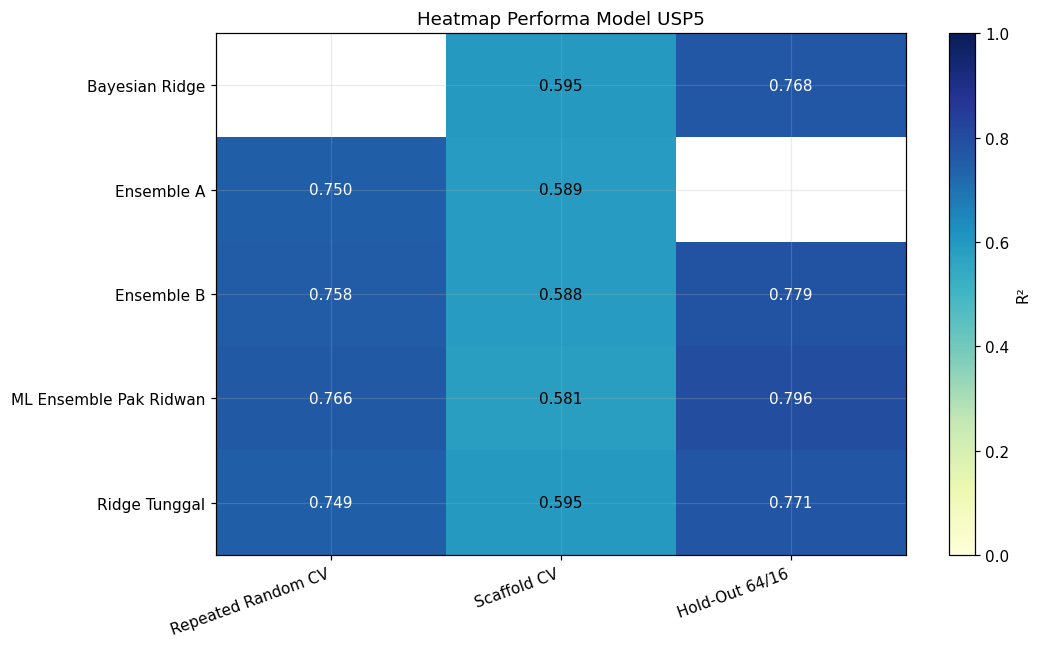

In [45]:

import matplotlib.pyplot as plt
import numpy as np

heat15 = tabel_final15.pivot(
    index="Model",
    columns="Protokol",
    values="R2"
).reindex(columns=[
    "Repeated Random CV",
    "Scaffold CV",
    "Hold-Out 64/16"
])

fig, ax = plt.subplots(figsize=(10, 6))

im = ax.imshow(
    heat15.to_numpy(),
    cmap="YlGnBu",
    vmin=0,
    vmax=1,
    aspect="auto"
)

ax.set_xticks(range(len(heat15.columns)))
ax.set_xticklabels(heat15.columns, rotation=20, ha="right")
ax.set_yticks(range(len(heat15.index)))
ax.set_yticklabels(heat15.index)

for i in range(len(heat15.index)):
    for j in range(len(heat15.columns)):
        nilai = heat15.iloc[i, j]
        if np.isfinite(nilai):
            ax.text(
                j, i, f"{nilai:.3f}",
                ha="center", va="center",
                color="white" if nilai > 0.7 else "black"
            )

fig.colorbar(im, ax=ax, label="R²")
ax.set_title("Heatmap Performa Model USP5")

plt.tight_layout()
plt.savefig(
    OUT / "USP5_Heatmap_Performa_Akhir.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()



# 16. Kesimpulan Akhir, Keterbatasan, dan Pengembangan Penelitian

## 16.1 Ringkasan Penelitian

Penelitian ini mengembangkan model machine learning berbasis representasi struktur molekul untuk memprediksi afinitas inhibitor USP5 dalam bentuk nilai pKd.

Dataset yang digunakan terdiri atas **80 senyawa inhibitor USP5** hasil kurasi data menggunakan KNIME. Penelitian ini merupakan pengembangan dan eksplorasi mandiri berdasarkan alur pemodelan ML Ensemble pada notebook referensi Pak Ridwan.

Pendekatan penelitian mencakup:

1. Eksplorasi data dan analisis scaffold molekul.
2. Featurization menggunakan RDKit Descriptors, Morgan Fingerprint, dan MACCS Keys.
3. Screening terhadap 13 algoritma machine learning.
4. Pemilihan model berdasarkan hasil screening.
5. Pembentukan Ridge Tunggal, Ensemble A, dan Ensemble B.
6. Evaluasi Repeated Random 5-Fold Cross-Validation.
7. Evaluasi Scaffold 5-Fold Cross-Validation.
8. Analisis residual dan korelasi error antaralgoritma.
9. Evaluasi Repeated Hold-Out 64/16.
10. Visualisasi diagnostik prediksi.
11. Analisis Applicability Domain berbasis Tanimoto Similarity.
12. Interpretasi model menggunakan Permutation Importance.
13. Pelatihan dan penyimpanan model final.
14. Perbandingan performa dengan model referensi.

Seluruh tahapan dilakukan untuk mengevaluasi performa prediksi, kestabilan model, kemampuan generalisasi struktural, dan keterbatasan penerapan model QSAR pada dataset inhibitor USP5.

---

## 16.2 Hasil Screening Algoritma

Screening awal dilakukan terhadap 13 algoritma menggunakan dua kombinasi fitur molekul, sehingga menghasilkan **26 konfigurasi pengujian**.

Kombinasi fitur yang diuji adalah:

- Morgan Fingerprint + MACCS Keys.
- RDKit Descriptors + Morgan Fingerprint.

Hasil screening menunjukkan bahwa **Ridge Regression menggunakan Morgan + MACCS memperoleh R² tertinggi sebesar 0,7729**, dengan RMSE 0,3018.

Algoritma lain yang menunjukkan performa kompetitif adalah PLS Regression, Bayesian Ridge, XGBoost, dan Random Forest.

Berdasarkan hasil tersebut, dilakukan pembentukan dua kandidat ensemble:

- **Ensemble A:** Ridge + PLS Regression + Bayesian Ridge.
- **Ensemble B:** Ridge + Bayesian Ridge + XGBoost.

Ridge Tunggal dipertahankan sebagai pembanding untuk mengetahui apakah penggabungan beberapa algoritma benar-benar meningkatkan kemampuan prediksi.

---

## 16.3 Evaluasi Repeated Random Cross-Validation

Evaluasi dilakukan menggunakan Random 5-Fold Cross-Validation sebanyak lima pengulangan dengan seed 200–204.

### Ringkasan Performa

| Model | R² Mean ± SD | RMSE Mean ± SD | MAE Mean |
|---|---|---|---|
| Ridge Tunggal | 0,7486 ± 0,0334 | 0,3171 ± 0,0205 | 0,2416 |
| Ensemble A | 0,7497 ± 0,0287 | 0,3165 ± 0,0176 | 0,2403 |
| **Ensemble B** | **0,7578 ± 0,0223** | **0,3115 ± 0,0140** | **0,2358** |

Ensemble B memberikan performa rata-rata terbaik berdasarkan nilai R² tertinggi serta RMSE dan MAE terendah.

Standar deviasi R² Ensemble B juga paling rendah, menunjukkan variasi performa yang lebih kecil dibandingkan kandidat lainnya pada lima pengulangan yang diuji.

Namun, penurunan performa ditemukan pada seed 204. Analisis lebih lanjut menunjukkan peningkatan jumlah senyawa dengan kesalahan prediksi besar, sehingga menegaskan bahwa performa model dipengaruhi oleh pembagian training dan validasi.

**Kesimpulan:** Ensemble B merupakan kandidat terbaik berdasarkan repeated random CV, tetapi keunggulannya terhadap model lain relatif kecil.

---

## 16.4 Evaluasi Scaffold Cross-Validation

Scaffold Cross-Validation dilakukan menggunakan GroupKFold 5-fold berdasarkan kerangka molekul Bemis–Murcko.

Dataset memiliki 38 scaffold unik, sehingga metode ini digunakan untuk mengevaluasi kemampuan model dalam memprediksi senyawa dengan kerangka molekul yang tidak muncul selama pelatihan.

### Ringkasan Performa

| Model | R² | RMSE | MAE |
|---|---:|---:|---:|
| **Bayesian Ridge** | **0,5954** | **0,4029** | **0,2804** |
| Ridge Tunggal | 0,5945 | 0,4033 | 0,2866 |
| Ensemble A | 0,5890 | 0,4061 | 0,2868 |
| Ensemble B | 0,5881 | 0,4065 | 0,2973 |

Bayesian Ridge menghasilkan performa scaffold CV tertinggi, meskipun perbedaannya terhadap Ridge Tunggal sangat kecil.

Ensemble B tidak memberikan peningkatan performa dibandingkan model tunggal pada protokol ini.

Performa scaffold CV secara umum lebih rendah daripada repeated random CV, menunjukkan keterbatasan prediksi terhadap struktur molekul dengan scaffold yang berbeda dari data training.

Analisis per fold menunjukkan bahwa fold 3 dan 4 memiliki RMSE relatif tinggi, terutama pada beberapa senyawa dengan pKd tinggi.

**Kesimpulan:** Bayesian Ridge menjadi kandidat model tunggal terbaik pada scaffold CV, sedangkan Ensemble B belum menunjukkan peningkatan generalisasi struktural yang konsisten.

---

## 16.5 Analisis Korelasi Error Antaranggota Ensemble

Analisis korelasi residual dilakukan terhadap Ridge, Bayesian Ridge, dan XGBoost sebagai penyusun Ensemble B.

Diperoleh korelasi Pearson:

| Pasangan Model | Korelasi Error |
|---|---:|
| Ridge – Bayesian Ridge | 0,9963 |
| Ridge – XGBoost | 0,8971 |
| Bayesian Ridge – XGBoost | 0,8916 |

Ridge dan Bayesian Ridge menghasilkan pola kesalahan yang hampir identik.

XGBoost memberikan pola kesalahan yang sedikit berbeda, tetapi korelasinya masih tinggi dan performa individualnya lebih rendah dibandingkan kedua model linear.

Hasil ini menunjukkan bahwa keberagaman algoritma tidak selalu memberikan peningkatan performa ensemble.

Penggabungan model menggunakan rata-rata berbobot sama belum mampu meningkatkan performa scaffold dibandingkan Bayesian Ridge dan Ridge secara individual.

---

## 16.6 Evaluasi Repeated Hold-Out 64/16

Evaluasi dilakukan menggunakan 64 senyawa training dan 16 senyawa testing, dengan StratifiedShuffleSplit sebanyak 20 pengulangan berdasarkan kuartil pKd.

### Ringkasan Performa

| Model | R² Mean ± SD | RMSE Mean ± SD | MAE Mean |
|---|---|---|---|
| Bayesian Ridge | 0,7681 ± 0,1674 | 0,2802 ± 0,0799 | 0,2217 |
| Ridge Tunggal | 0,7710 ± 0,1677 | 0,2777 ± 0,0818 | 0,2186 |
| **Ensemble B** | **0,7792 ± 0,1685** | **0,2723 ± 0,0808** | **0,2155** |

Ensemble B menghasilkan performa rata-rata terbaik pada evaluasi hold-out berulang.

Namun, standar deviasi R² yang cukup besar menunjukkan bahwa hasil prediksi masih sensitif terhadap komposisi data testing.

Penurunan R² yang tajam terjadi pada split ke-5, terutama akibat kesalahan prediksi besar pada CHEMBL5410606 dan CHEMBL5426708.

Kedua senyawa memiliki pKd eksperimen tinggi, tetapi diprediksi jauh lebih rendah oleh model.

Temuan tersebut konsisten dengan analisis residual sebelumnya.

**Kesimpulan:** Ensemble B menunjukkan performa rata-rata terbaik pada hold-out berulang, tetapi kestabilan model masih dipengaruhi oleh komposisi senyawa testing.

Evaluasi ini merupakan pengujian internal dengan data yang telah digunakan pada tahap pengembangan dan pemilihan model, bukan pengujian eksternal independen.

---

## 16.7 Analisis Kesalahan Prediksi dan Residual

Analisis residual menunjukkan bahwa kesalahan prediksi tidak tersebar merata pada seluruh rentang pKd.

### MAE Berdasarkan Rentang pKd pada Scaffold CV

| Rentang pKd | Jumlah Senyawa | MAE Ridge | MAE Ensemble B |
|---|---:|---:|---:|
| pKd < 4 | 33 | 0,2577 | 0,2603 |
| 4 ≤ pKd < 5 | 38 | 0,1889 | 0,2083 |
| pKd ≥ 5 | 9 | 0,8055 | 0,8085 |

Kesalahan terbesar terjadi pada kelompok dengan pKd ≥ 5.

Senyawa ber-pKd tinggi cenderung mengalami underprediction, sedangkan sebagian senyawa dengan pKd rendah mengalami overprediction.

Pola tersebut menunjukkan kecenderungan prediksi menuju nilai aktivitas menengah (*regression to the mean*).

Karena hanya terdapat 9 senyawa dengan pKd ≥ 5, kemampuan model mempelajari pola struktur–aktivitas pada rentang afinitas tinggi masih terbatas.

**Kesimpulan:** Keterbatasan utama model adalah kesalahan prediksi yang relatif besar pada senyawa dengan pKd tinggi.

---

## 16.8 Analisis Applicability Domain

Applicability Domain dianalisis menggunakan Morgan Binary Fingerprint radius 2 berukuran 2048 bit dan Tanimoto Similarity terhadap data training pada masing-masing fold.

### Hasil Analisis

| Parameter | Random CV | Scaffold CV |
|---|---:|---:|
| Median Tanimoto | 0,7048 | 0,6735 |
| Korelasi Spearman | -0,2813 | -0,1059 |
| p-value | 0,0115 | 0,3498 |
| Jumlah senyawa dengan Tanimoto < 0,40 | 6 | 13 |

Pada Random CV ditemukan hubungan negatif yang lemah tetapi signifikan secara statistik antara kemiripan molekul dan kesalahan prediksi.

Sebaliknya, pada Scaffold CV hubungan tersebut sangat lemah dan tidak signifikan.

Analisis kuartil juga menunjukkan bahwa kelompok dengan kemiripan tertinggi memiliki kesalahan rata-rata paling rendah, tetapi hubungan antar-kuartil tidak sepenuhnya konsisten.

Dengan demikian, kemiripan molekul dapat memberikan informasi mengenai keterwakilan struktur, tetapi belum cukup untuk menjadi satu-satunya indikator keandalan prediksi.

Ambang Tanimoto 0,40 yang digunakan dalam analisis masih bersifat eksploratif dan belum merupakan batas applicability domain yang tervalidasi.

---

## 16.9 Interpretasi Fitur Molekul

Interpretasi model dilakukan menggunakan permutation importance pada fitur Morgan Fingerprint dan MACCS Keys.

### Kontribusi Kelompok Fitur

| Model | Morgan Importance | MACCS Importance |
|---|---:|---:|
| Ridge | 0,2734 | 0,2057 |
| Bayesian Ridge | 0,2723 | 0,1833 |
| Ensemble B | 0,3022 | 0,1792 |

Pengacakan kelompok Morgan Fingerprint menghasilkan peningkatan MSE lebih besar dibandingkan pengacakan MACCS Keys pada ketiga model.

Hal tersebut menunjukkan bahwa kelompok Morgan memberikan kontribusi prediktif lebih besar dalam pembagian validasi yang dianalisis.

Namun, jumlah fitur Morgan lebih banyak daripada MACCS, sehingga nilai importance kelompok tidak dapat ditafsirkan sebagai importance rata-rata setiap fitur.

### Fitur Individual

Pada Bayesian Ridge, lima fitur dengan permutation importance tertinggi adalah:

1. Morgan_573: 0,01432
2. Morgan_290: 0,00421
3. Morgan_879: 0,00412
4. Morgan_802: 0,00408
5. MACCS_98: 0,00391

Morgan_573 menunjukkan importance tertinggi, tetapi nilai standar deviasinya juga relatif besar.

Fitur fingerprint merepresentasikan pola struktur kimia dan tidak langsung menunjukkan mekanisme inhibisi USP5.

Oleh karena itu, interpretasi struktur atom dan relevansi biologis fitur masih memerlukan analisis tambahan.

---

## 16.10 Pelatihan dan Penyimpanan Model Final

Setelah proses evaluasi selesai, dilakukan pelatihan ulang Ridge, Bayesian Ridge, dan XGBoost menggunakan seluruh 80 senyawa inhibitor USP5.

Ketiga model kemudian disimpan sebagai komponen Ensemble B dengan metode equal-weight averaging.

### Hasil Pelatihan

| Parameter | Hasil |
|---|---:|
| Jumlah senyawa training | 80 |
| Jumlah fitur molekul | 1.191 |
| R² training Ensemble B | 0,9944 |
| RMSE training Ensemble B | 0,0476 |
| Status penyimpanan | Berhasil |
| Verifikasi pemuatan model | Berhasil |
| Konsistensi prediksi setelah dimuat | Sesuai |

Model disimpan pada:

`/data/Aliya/model/Hasil_Ensemble_80/USP5_Model_Final_80.joblib`

Nilai R² training yang sangat tinggi menunjukkan kemampuan model menyesuaikan prediksi terhadap data pelatihan.

Namun, hasil training tersebut tidak menunjukkan kemampuan generalisasi pada senyawa baru.

Perbedaan antara R² training (0,9944) dan R² scaffold CV (0,5881) menunjukkan adanya kesenjangan performa antara data training dan data validasi dengan scaffold berbeda. Hal ini dapat mengindikasikan overfitting atau keterbatasan generalisasi struktural, meskipun penyebabnya belum dapat ditentukan hanya dari kedua angka tersebut.

Oleh karena itu, performa model tetap dilaporkan berdasarkan hasil cross-validation dan hold-out, bukan hasil training.

---

## 16.11 Perbandingan dengan ML Ensemble Referensi Pak Ridwan

### Perbandingan R²

| Protokol | ML Ensemble Pak Ridwan | Ensemble B Penelitian Ini |
|---|---:|---:|
| Repeated Random CV | **0,7656** | 0,7578 |
| Scaffold CV | 0,5805 | **0,5881** |
| Hold-Out 64/16 | **0,7960** | 0,7792 |

### Perbandingan RMSE

| Protokol | ML Ensemble Pak Ridwan | Ensemble B Penelitian Ini |
|---|---:|---:|
| Repeated Random CV | **0,3064** | 0,3115 |
| Scaffold CV | 0,4102 | **0,4065** |
| Hold-Out 64/16 | **0,2639** | 0,2723 |

Hasil referensi Pak Ridwan menunjukkan performa sedikit lebih baik pada repeated random CV dan hold-out.

Sementara itu, Ensemble B penelitian ini menunjukkan hasil scaffold CV sedikit lebih tinggi berdasarkan R² dan lebih rendah berdasarkan RMSE.

Perbedaan performa relatif kecil dan belum dapat dinyatakan signifikan secara statistik.

Selain itu, komposisi algoritma, pengaturan model, dan prosedur evaluasi tidak seluruhnya identik, sehingga perbandingan hanya bersifat deskriptif.

Penelitian ini tetap memberikan kontribusi berupa pelaksanaan screening mandiri, pemilihan kandidat berdasarkan hasil eksperimen, serta analisis tambahan terhadap kestabilan prediksi, residual, applicability domain, dan kontribusi fitur molekul.

---

## 16.12 Keterbatasan Penelitian

Beberapa keterbatasan yang perlu diperhatikan adalah:

1. **Ukuran dataset kecil.** Jumlah 80 senyawa membatasi variasi struktur molekul dan kemampuan model mempelajari hubungan struktur–aktivitas.

2. **Distribusi pKd tidak merata.** Hanya 9 senyawa memiliki pKd ≥ 5, sehingga model mengalami kesulitan memprediksi kelompok afinitas tinggi.

3. **Belum terdapat pengujian eksternal independen.** Seluruh hasil evaluasi berasal dari dataset yang sama dengan data pengembangan dan pemilihan model.

4. **Potensi bias pemilihan model.** Kandidat dipilih berdasarkan screening dan dievaluasi kembali menggunakan dataset yang sama, sehingga hasil evaluasi dapat bersifat optimistis.

5. **Performa scaffold CV lebih rendah.** Model belum menunjukkan kemampuan generalisasi struktural yang setara dengan performa random CV.

6. **Kesalahan antaralgoritma berkorelasi tinggi.** Hal ini membatasi peningkatan performa yang dapat diperoleh melalui equal-weight averaging.

7. **Heterogenitas data assay.** Perbedaan kondisi pengukuran dan konstruksi protein berpotensi memengaruhi keseragaman nilai pKd.

8. **Applicability domain belum tervalidasi secara prospektif.** Kemiripan fingerprint belum terbukti sebagai indikator yang cukup untuk menjamin keandalan prediksi.

9. **Interpretasi fitur masih terbatas.** Importance fingerprint belum dapat langsung digunakan untuk menyimpulkan mekanisme penghambatan atau hubungan sebab-akibat biologis.

10. **Performa tinggi pada data training.** Nilai R² training 0,9944 jauh melebihi R² scaffold CV, sehingga hasil prediksi pada data baru perlu ditafsirkan secara hati-hati.

---

## 16.13 Rekomendasi Pengembangan Penelitian

Penelitian lanjutan disarankan untuk:

1. Menambah jumlah senyawa inhibitor USP5, terutama senyawa dengan pKd tinggi.
2. Melakukan validasi eksternal pada senyawa yang belum digunakan selama screening dan pengembangan model.
3. Memeriksa konsistensi assay serta konstruksi protein sebelum menggabungkan data aktivitas.
4. Menerapkan nested cross-validation untuk mengurangi bias pemilihan model dan hyperparameter.
5. Menelusuri struktur kimia yang direpresentasikan oleh fitur Morgan dan MACCS dengan importance tinggi.
6. Mengembangkan metode estimasi ketidakpastian prediksi.
7. Menguji applicability domain menggunakan data eksternal.
8. Membandingkan model fingerprint dengan pendekatan representasi molekul lain pada protokol evaluasi yang setara.

---

## 16.14 Kesimpulan Akhir

Penelitian ini berhasil mengembangkan, mengevaluasi, dan menyimpan model machine learning berbasis fingerprint molekul untuk prediksi nilai pKd inhibitor USP5 menggunakan dataset 80 senyawa.

**Ensemble B, yang terdiri atas Ridge Regression, Bayesian Ridge, dan XGBoost, menunjukkan performa rata-rata terbaik pada Repeated Random Cross-Validation dan Repeated Hold-Out 64/16.**

Pada Repeated Random 5-Fold CV, Ensemble B menghasilkan R² sebesar 0,7578 ± 0,0223 dengan RMSE 0,3115 ± 0,0140.

Pada Repeated Hold-Out 64/16, Ensemble B menghasilkan R² sebesar 0,7792 ± 0,1685 dengan RMSE 0,2723 ± 0,0808.

Sebaliknya, Bayesian Ridge menghasilkan performa tertinggi pada Scaffold Cross-Validation dengan R² sebesar 0,5954 dan RMSE 0,4029.

Hasil tersebut menunjukkan bahwa penggunaan ensemble tidak selalu menghasilkan generalisasi struktural yang lebih baik daripada model tunggal.

Analisis residual, applicability domain, dan feature importance juga menunjukkan bahwa keterbatasan utama penelitian terdapat pada prediksi senyawa dengan pKd tinggi, keterwakilan struktur molekul, serta jumlah data yang relatif terbatas.

Model final berhasil dilatih menggunakan seluruh 80 senyawa dan disimpan dalam format Joblib untuk mendukung penggunaan serta pengembangan berikutnya.

**Secara keseluruhan, Ensemble B merupakan kandidat model yang menjanjikan berdasarkan evaluasi internal, tetapi belum dapat dinyatakan sebagai model dengan kemampuan generalisasi terbaik secara definitif tanpa validasi eksternal independen.**

Hasil penelitian ini memberikan dasar pengembangan model QSAR inhibitor USP5 yang lebih lanjut, sekaligus menunjukkan pentingnya evaluasi menggunakan beberapa protokol validasi dan interpretasi kesalahan prediksi sebelum model digunakan untuk mendukung penapisan senyawa baru.

---

## 16.15 Status Akhir Penelitian

**Seluruh 16 tahap pemodelan dan evaluasi ML Ensemble USP5 telah diselesaikan secara komputasional.**

Output yang dihasilkan meliputi:

- Dataset dan representasi fitur molekul.
- Hasil screening algoritma.
- Model tunggal dan ensemble.
- Hasil repeated random CV.
- Hasil scaffold CV.
- Hasil repeated hold-out.
- Analisis residual dan kesalahan prediksi.
- Analisis korelasi error.
- Applicability domain.
- Permutation feature importance.
- Grafik diagnostik dan heatmap.
- Tabel perbandingan akhir.
- File model final dalam format Joblib.

Penelitian siap dilanjutkan ke tahap analisis ilmiah, validasi eksternal, interpretasi kimiawi, dan penyusunan laporan atau manuskrip.


# 17. Optimasi Kombinasi Heterogeneous Machine Learning Ensemble

Tahap ini bertujuan mengevaluasi beberapa kombinasi algoritma dari keluarga
yang berbeda untuk memperoleh model prediksi pKd inhibitor USP5 yang
memiliki performa dan kemampuan generalisasi yang baik.

Evaluasi dilakukan menggunakan Random Cross-Validation dan Scaffold
Cross-Validation dengan pembagian data yang konsisten.


# 17. Optimasi Heterogeneous Machine Learning Ensemble

## 17.1 Tujuan Penelitian

Tahap ini bertujuan mengevaluasi beberapa kombinasi algoritma
machine learning dari keluarga berbeda untuk prediksi pKd
inhibitor USP5.

Empat konfigurasi ensemble dibandingkan:
- A: Ridge + Bayesian Ridge + XGBoost
- B: Bayesian Ridge + SVR Linear + Gradient Boosting
- C: Bayesian Ridge + Random Forest + XGBoost
- D: Bayesian Ridge + SVR RBF + Gradient Boosting

Evaluasi dilakukan menggunakan pembagian Random CV dan Scaffold CV
yang konsisten untuk seluruh konfigurasi.

Pemilihan kombinasi terbaik akan mempertimbangkan performa prediksi,
kemampuan generalisasi terhadap scaffold baru, dan keragaman
kesalahan prediksi antaranggota ensemble.


In [46]:

# ==================================================
# 17.2 PERSIAPAN HETEROGENEOUS ML ENSEMBLE
# USP5 - 80 SENYAWA
# ==================================================

import numpy as np
import pandas as pd
from pathlib import Path

from rdkit import Chem
from rdkit.Chem import (
    Descriptors,
    MACCSkeys,
    rdFingerprintGenerator
)
from rdkit.Chem.Scaffolds import MurckoScaffold
from rdkit.ML.Descriptors import MoleculeDescriptors

# Folder hasil Tahap 17
OUT17 = Path(
    "/data/Aliya/model/Hasil_ML_Ensemble_Heterogen_80"
)
OUT17.mkdir(parents=True, exist_ok=True)

# Dataset yang sama seperti eksperimen sebelumnya
url17 = (
    "https://raw.githubusercontent.com/"
    "aliyarahmaazizah/USP5/main/USP5_pKd_80.csv"
)

df17 = pd.read_csv(url17)
assert len(df17) == 80

smiles17 = df17["Smiles"].astype(str).tolist()
y17 = df17["pKd"].to_numpy(dtype=float)

mols17 = [
    Chem.MolFromSmiles(s)
    for s in smiles17
]

assert all(m is not None for m in mols17)

# Deskriptor RDKit
desc_names17 = [d[0] for d in Descriptors._descList]
calc17 = MoleculeDescriptors.MolecularDescriptorCalculator(
    desc_names17
)

DESC17 = np.array([
    calc17.CalcDescriptors(m)
    for m in mols17
], dtype=float)

DESC17 = np.nan_to_num(
    DESC17,
    nan=0.0,
    posinf=0.0,
    neginf=0.0
)

# Morgan Count Fingerprint
mgen17 = rdFingerprintGenerator.GetMorganGenerator(
    radius=2,
    fpSize=1024
)

MORGAN17 = np.array([
    mgen17.GetCountFingerprintAsNumPy(m)
    for m in mols17
], dtype=float)

# MACCS Keys
MACCS17 = np.array([
    np.array(MACCSkeys.GenMACCSKeys(m))
    for m in mols17
], dtype=float)

# Gabungan fitur
X17 = np.hstack([
    DESC17,
    MORGAN17,
    MACCS17
])

n_desc17 = DESC17.shape[1]
n_morgan17 = MORGAN17.shape[1]

IDX_FPMA17 = np.arange(
    n_desc17,
    X17.shape[1]
)

IDX_DESCFP17 = np.arange(
    0,
    n_desc17 + n_morgan17
)

# Scaffold molekul
scaffold17 = np.array([
    MurckoScaffold.MurckoScaffoldSmiles(mol=m)
    for m in mols17
])

print("=== TAHAP 17: PERSIAPAN DATA ===")
print("Jumlah senyawa:", len(df17))
print("Scaffold unik:", len(set(scaffold17)))

print("\n=== FITUR MOLEKUL ===")
print("Descriptors:", DESC17.shape)
print("Morgan:", MORGAN17.shape)
print("MACCS:", MACCS17.shape)
print("Total fitur:", X17.shape)

print("\n=== TARGET ===")
print("pKd minimum:", round(y17.min(), 4))
print("pKd maksimum:", round(y17.max(), 4))

print("\n=== PERSIAPAN BERHASIL ===")


=== TAHAP 17: PERSIAPAN DATA ===
Jumlah senyawa: 80
Scaffold unik: 38

=== FITUR MOLEKUL ===
Descriptors: (80, 217)
Morgan: (80, 1024)
MACCS: (80, 167)
Total fitur: (80, 1408)

=== TARGET ===
pKd minimum: 3.0315
pKd maksimum: 5.5528

=== PERSIAPAN BERHASIL ===


In [47]:

# ==================================================
# 17.3 DEFINISI 4 KOMBINASI HETEROGENEOUS ENSEMBLE
# ==================================================

from sklearn.base import (
    BaseEstimator, RegressorMixin,
    TransformerMixin, clone
)
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import Ridge, BayesianRidge
from sklearn.svm import SVR
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor
)
from xgboost import XGBRegressor

# Pemilih blok fitur
class BlockSelector17(BaseEstimator, TransformerMixin):
    def __init__(self, idx):
        self.idx = idx

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        return np.asarray(X)[:, self.idx]


# Pipeline praproses
def make_pipe17(idx, estimator):
    return Pipeline([
        ("select", BlockSelector17(idx)),
        ("imputer", SimpleImputer(strategy="median")),
        ("variance", VarianceThreshold(0.0)),
        ("scaler", StandardScaler()),
        ("model", estimator)
    ])


# Ensemble rata-rata 3 model
class AverageEnsemble17(BaseEstimator, RegressorMixin):
    def __init__(self, members=None):
        self.members = members

    def fit(self, X, y):
        self.models_ = [
            clone(model).fit(X, y)
            for model in self.members
        ]
        return self

    def predict(self, X):
        predictions = np.array([
            model.predict(X)
            for model in self.models_
        ])
        return predictions.mean(axis=0)

    def predict_members(self, X):
        return np.array([
            model.predict(X)
            for model in self.models_
        ])


# ==========================================
# DEFINISI ALGORITMA
# ==========================================

def make_ensemble17(kombinasi):

    # A: Pendekatan ML Ensemble B sebelumnya
    if kombinasi == "A":
        members = [
            make_pipe17(
                IDX_FPMA17,
                Ridge(alpha=10.0)
            ),
            make_pipe17(
                IDX_FPMA17,
                BayesianRidge()
            ),
            make_pipe17(
                IDX_FPMA17,
                XGBRegressor(
                    n_estimators=300,
                    max_depth=3,
                    learning_rate=0.05,
                    subsample=0.8,
                    random_state=42,
                    n_jobs=1
                )
            )
        ]

    # B: Replikasi model Pak Ridwan
    elif kombinasi == "B":
        members = [
            make_pipe17(
                IDX_FPMA17,
                BayesianRidge()
            ),
            make_pipe17(
                IDX_FPMA17,
                SVR(
                    kernel="linear",
                    C=0.3,
                    epsilon=0.05
                )
            ),
            make_pipe17(
                IDX_DESCFP17,
                GradientBoostingRegressor(
                    n_estimators=400,
                    learning_rate=0.05,
                    max_depth=3,
                    subsample=0.8,
                    random_state=42
                )
            )
        ]

    # C: Linear + Random Forest + XGBoost
    elif kombinasi == "C":
        members = [
            make_pipe17(
                IDX_FPMA17,
                BayesianRidge()
            ),
            make_pipe17(
                IDX_FPMA17,
                RandomForestRegressor(
                    n_estimators=300,
                    random_state=42,
                    n_jobs=-1
                )
            ),
            make_pipe17(
                IDX_FPMA17,
                XGBRegressor(
                    n_estimators=300,
                    max_depth=3,
                    learning_rate=0.05,
                    subsample=0.8,
                    random_state=42,
                    n_jobs=1
                )
            )
        ]

    # D: Linear + Kernel SVR + Boosting
    elif kombinasi == "D":
        members = [
            make_pipe17(
                IDX_FPMA17,
                BayesianRidge()
            ),
            make_pipe17(
                IDX_DESCFP17,
                SVR(
                    kernel="rbf",
                    C=5.0,
                    epsilon=0.05,
                    gamma=0.003
                )
            ),
            make_pipe17(
                IDX_DESCFP17,
                GradientBoostingRegressor(
                    n_estimators=400,
                    learning_rate=0.05,
                    max_depth=3,
                    subsample=0.8,
                    random_state=42
                )
            )
        ]

    else:
        raise ValueError("Pilih A, B, C, atau D")

    return AverageEnsemble17(members=members)


# ==========================================
# VERIFIKASI KOMBINASI
# ==========================================

nama_kombinasi17 = {
    "A": "Ridge + Bayesian Ridge + XGBoost",
    "B": "Bayesian Ridge + SVR Linear + Gradient Boosting",
    "C": "Bayesian Ridge + Random Forest + XGBoost",
    "D": "Bayesian Ridge + SVR RBF + Gradient Boosting"
}

print("=== KOMBINASI HETEROGENEOUS ENSEMBLE ===")

for kode, nama in nama_kombinasi17.items():
    model = make_ensemble17(kode)
    print(f"{kode}: {nama}")
    print(f"   Jumlah anggota: {len(model.members)}")

print("\n=== 4 KOMBINASI BERHASIL DIDEFINISIKAN ===")


=== KOMBINASI HETEROGENEOUS ENSEMBLE ===
A: Ridge + Bayesian Ridge + XGBoost
   Jumlah anggota: 3
B: Bayesian Ridge + SVR Linear + Gradient Boosting
   Jumlah anggota: 3
C: Bayesian Ridge + Random Forest + XGBoost
   Jumlah anggota: 3
D: Bayesian Ridge + SVR RBF + Gradient Boosting
   Jumlah anggota: 3

=== 4 KOMBINASI BERHASIL DIDEFINISIKAN ===


In [48]:

# ==================================================
# 17.4 RANDOM 5-FOLD CROSS-VALIDATION
# PERBANDINGAN 4 KOMBINASI ENSEMBLE
# ==================================================

from sklearn.model_selection import KFold
from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error
)

hasil_random17 = []
prediksi_random17 = {}

kombinasi17 = ["A", "B", "C", "D"]
seeds17 = [200, 201, 202, 203, 204]

print("=== RANDOM 5-FOLD CV: 5 ULANGAN ===")

for kode in kombinasi17:

    print(f"\nMenguji kombinasi {kode}")
    print(nama_kombinasi17[kode])

    prediksi_ulangan = []

    for seed in seeds17:

        cv = KFold(
            n_splits=5,
            shuffle=True,
            random_state=seed
        )

        pred = np.zeros(len(y17))

        for train_idx, test_idx in cv.split(X17):

            model = make_ensemble17(kode)

            model.fit(
                X17[train_idx],
                y17[train_idx]
            )

            pred[test_idx] = model.predict(
                X17[test_idx]
            )

        r2 = r2_score(y17, pred)

        rmse = np.sqrt(
            mean_squared_error(y17, pred)
        )

        mae = mean_absolute_error(y17, pred)

        hasil_random17.append({
            "Kombinasi": kode,
            "Algoritma": nama_kombinasi17[kode],
            "Seed": seed,
            "R2": r2,
            "RMSE": rmse,
            "MAE": mae
        })

        prediksi_ulangan.append(pred.copy())

        print(
            f"Seed {seed}: "
            f"R2={r2:.4f} | "
            f"RMSE={rmse:.4f} | "
            f"MAE={mae:.4f}"
        )

    prediksi_random17[kode] = np.array(
        prediksi_ulangan
    )

# Tabel seluruh hasil
hasil_random17 = pd.DataFrame(hasil_random17)

# Ringkasan rata-rata dan standar deviasi
ringkasan_random17 = (
    hasil_random17
    .groupby(["Kombinasi", "Algoritma"])
    .agg(
        R2_mean=("R2", "mean"),
        R2_sd=("R2", "std"),
        RMSE_mean=("RMSE", "mean"),
        RMSE_sd=("RMSE", "std"),
        MAE_mean=("MAE", "mean")
    )
    .reset_index()
    .sort_values("R2_mean", ascending=False)
)

print("\n=== PERBANDINGAN RANDOM CV ===")
print(
    ringkasan_random17
    .round(4)
    .to_string(index=False)
)

# Simpan hasil
hasil_random17.to_csv(
    OUT17 / "RandomCV_4_Kombinasi_Detail.csv",
    index=False
)

ringkasan_random17.to_csv(
    OUT17 / "RandomCV_4_Kombinasi_Ringkasan.csv",
    index=False
)

print("\n=== RANDOM CV SELESAI ===")
print("Hasil berhasil disimpan.")


=== RANDOM 5-FOLD CV: 5 ULANGAN ===

Menguji kombinasi A
Ridge + Bayesian Ridge + XGBoost
Seed 200: R2=0.7730 | RMSE=0.3018 | MAE=0.2283
Seed 201: R2=0.7749 | RMSE=0.3005 | MAE=0.2229
Seed 202: R2=0.7659 | RMSE=0.3064 | MAE=0.2302
Seed 203: R2=0.7626 | RMSE=0.3086 | MAE=0.2351
Seed 204: R2=0.7206 | RMSE=0.3348 | MAE=0.2552

Menguji kombinasi B
Bayesian Ridge + SVR Linear + Gradient Boosting
Seed 200: R2=0.7678 | RMSE=0.3052 | MAE=0.2347
Seed 201: R2=0.7904 | RMSE=0.2900 | MAE=0.2179
Seed 202: R2=0.7725 | RMSE=0.3021 | MAE=0.2276
Seed 203: R2=0.7665 | RMSE=0.3060 | MAE=0.2355
Seed 204: R2=0.7331 | RMSE=0.3272 | MAE=0.2506

Menguji kombinasi C
Bayesian Ridge + Random Forest + XGBoost
Seed 200: R2=0.7567 | RMSE=0.3124 | MAE=0.2397
Seed 201: R2=0.7634 | RMSE=0.3081 | MAE=0.2313
Seed 202: R2=0.7413 | RMSE=0.3221 | MAE=0.2462
Seed 203: R2=0.7545 | RMSE=0.3138 | MAE=0.2362
Seed 204: R2=0.7093 | RMSE=0.3415 | MAE=0.2533

Menguji kombinasi D
Bayesian Ridge + SVR RBF + Gradient Boosting
Seed 200

,Kombinasi,Algoritma,R2_mean,R2_sd,RMSE_mean,RMSE_sd,MAE_mean
0,B,Bayesian Ridge + SVR Linear + Gradient Boosting,0.7661,0.0208,0.3061,0.0135,0.2333
1,A,Ridge + Bayesian Ridge + XGBoost,0.7594,0.0223,0.3104,0.0140,0.2343
2,C,Bayesian Ridge + Random Forest + XGBoost,0.7450,0.0215,0.3196,0.0132,0.2413
3,D,Bayesian Ridge + SVR RBF + Gradient Boosting,0.7246,0.0253,0.3321,0.0152,0.2533


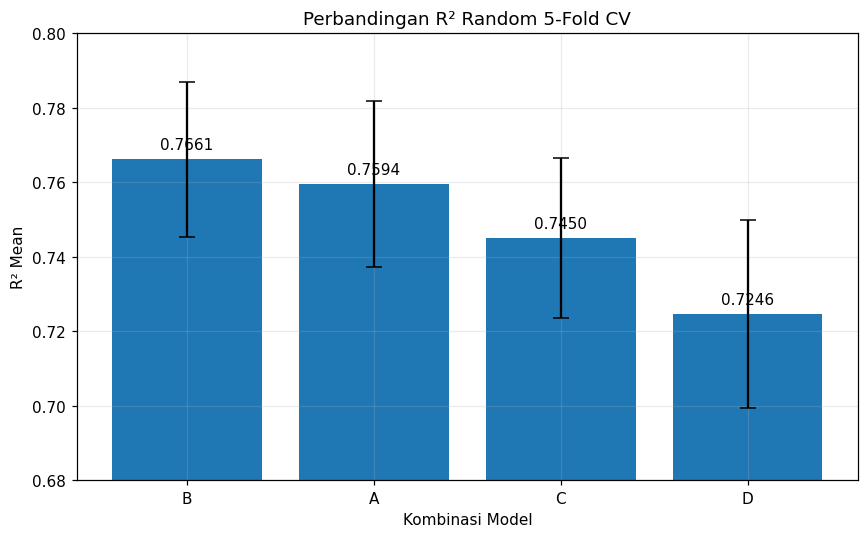

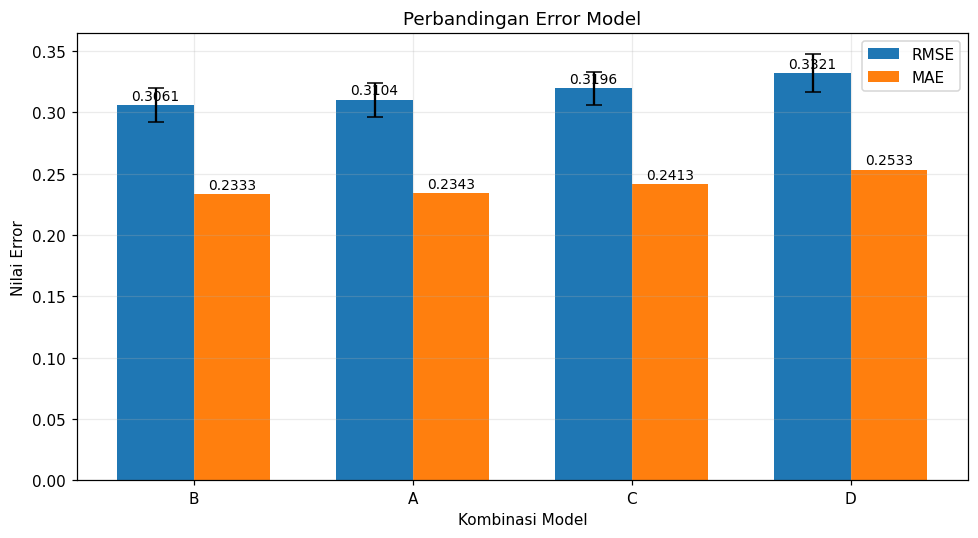

In [49]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Data hasil random CV
df_combo = pd.DataFrame({
    "Kombinasi": ["B", "A", "C", "D"],
    "Algoritma": [
        "Bayesian Ridge + SVR Linear + Gradient Boosting",
        "Ridge + Bayesian Ridge + XGBoost",
        "Bayesian Ridge + Random Forest + XGBoost",
        "Bayesian Ridge + SVR RBF + Gradient Boosting"
    ],
    "R2_mean": [0.7661, 0.7594, 0.7450, 0.7246],
    "R2_sd":   [0.0208, 0.0223, 0.0215, 0.0253],
    "RMSE_mean":[0.3061, 0.3104, 0.3196, 0.3321],
    "RMSE_sd": [0.0135, 0.0140, 0.0132, 0.0152],
    "MAE_mean":[0.2333, 0.2343, 0.2413, 0.2533]
})

# Ranking
df_rank = df_combo.sort_values("R2_mean", ascending=False).reset_index(drop=True)
display(df_rank.round(4))

# ========= GRAFIK 1: R2 =========
fig, ax = plt.subplots(figsize=(8,5))
bars = ax.bar(df_rank["Kombinasi"], df_rank["R2_mean"], yerr=df_rank["R2_sd"], capsize=5)
ax.set_title("Perbandingan R² Random 5-Fold CV")
ax.set_xlabel("Kombinasi Model")
ax.set_ylabel("R² Mean")
ax.set_ylim(0.68, 0.80)

for bar, val in zip(bars, df_rank["R2_mean"]):
    ax.text(bar.get_x() + bar.get_width()/2, val + 0.002, f"{val:.4f}",
            ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.show()

# ========= GRAFIK 2: RMSE dan MAE =========
x = np.arange(len(df_rank))
width = 0.35

fig, ax = plt.subplots(figsize=(9,5))
bars1 = ax.bar(x - width/2, df_rank["RMSE_mean"], width, yerr=df_rank["RMSE_sd"], capsize=5, label="RMSE")
bars2 = ax.bar(x + width/2, df_rank["MAE_mean"], width, label="MAE")

ax.set_title("Perbandingan Error Model")
ax.set_xlabel("Kombinasi Model")
ax.set_ylabel("Nilai Error")
ax.set_xticks(x)
ax.set_xticklabels(df_rank["Kombinasi"])
ax.legend()

for bar, val in zip(bars1, df_rank["RMSE_mean"]):
    ax.text(bar.get_x() + bar.get_width()/2, val + 0.002, f"{val:.4f}",
            ha='center', va='bottom', fontsize=9)

for bar, val in zip(bars2, df_rank["MAE_mean"]):
    ax.text(bar.get_x() + bar.get_width()/2, val + 0.002, f"{val:.4f}",
            ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

## 17.5 Evaluasi Scaffold 5-Fold Cross-Validation

Evaluasi dilakukan menggunakan GroupKFold dengan pengelompokan
berdasarkan Bemis–Murcko scaffold.

Metode ini memastikan scaffold pada data pengujian tidak muncul
dalam data pelatihan pada fold yang sama.

Keempat kombinasi ensemble dievaluasi menggunakan pembagian
fold identik untuk membandingkan kemampuan generalisasi
terhadap scaffold baru.

In [50]:

# ==================================================
# 17.5 SCAFFOLD 5-FOLD CROSS-VALIDATION
# PERBANDINGAN 4 KOMBINASI ENSEMBLE
# ==================================================

from sklearn.model_selection import GroupKFold
from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error
)

gkf17 = GroupKFold(n_splits=5)

hasil_scaffold17 = []
prediksi_scaffold17 = {}

print("=== SCAFFOLD 5-FOLD CROSS-VALIDATION ===")

for kode in ["A", "B", "C", "D"]:

    print(f"\nMenguji kombinasi {kode}")
    print(nama_kombinasi17[kode])

    pred = np.zeros(len(y17))
    overlap_total = 0

    for fold, (train_idx, test_idx) in enumerate(
        gkf17.split(X17, y17, groups=scaffold17),
        start=1
    ):

        scaffold_train = set(scaffold17[train_idx])
        scaffold_test = set(scaffold17[test_idx])

        overlap = len(
            scaffold_train.intersection(scaffold_test)
        )

        overlap_total += overlap

        assert overlap == 0, (
            f"Scaffold overlap ditemukan pada fold {fold}"
        )

        model = make_ensemble17(kode)

        model.fit(
            X17[train_idx],
            y17[train_idx]
        )

        pred[test_idx] = model.predict(
            X17[test_idx]
        )

        print(
            f"Fold {fold}: "
            f"Train={len(train_idx)} | "
            f"Test={len(test_idx)} | "
            f"Overlap={overlap}"
        )

    r2 = r2_score(y17, pred)

    rmse = np.sqrt(
        mean_squared_error(y17, pred)
    )

    mae = mean_absolute_error(y17, pred)

    hasil_scaffold17.append({
        "Kombinasi": kode,
        "Algoritma": nama_kombinasi17[kode],
        "R2": r2,
        "RMSE": rmse,
        "MAE": mae,
        "Scaffold_Overlap": overlap_total
    })

    prediksi_scaffold17[kode] = pred.copy()

    print(f"\nHASIL KOMBINASI {kode}")
    print(f"R2   = {r2:.4f}")
    print(f"RMSE = {rmse:.4f}")
    print(f"MAE  = {mae:.4f}")


# Tabel ringkasan
hasil_scaffold17 = pd.DataFrame(
    hasil_scaffold17
).sort_values(
    "R2",
    ascending=False
)

print("\n=== PERBANDINGAN SCAFFOLD CV ===")
print(
    hasil_scaffold17
    .round(4)
    .to_string(index=False)
)

# Simpan hasil
hasil_scaffold17.to_csv(
    OUT17 / "ScaffoldCV_4_Kombinasi.csv",
    index=False
)

# Simpan prediksi setiap senyawa
pred_df17 = pd.DataFrame({
    "SMILES": smiles17,
    "pKd_eksperimen": y17,
    "Scaffold": scaffold17
})

for kode in ["A", "B", "C", "D"]:
    pred_df17[f"pKd_pred_{kode}"] = (
        prediksi_scaffold17[kode]
    )

pred_df17.to_csv(
    OUT17 / "Prediksi_ScaffoldCV_4_Kombinasi.csv",
    index=False
)

print("\n=== SCAFFOLD CV SELESAI ===")
print("Hasil berhasil disimpan.")

# ==================================================
# 17.5 SCAFFOLD 5-FOLD CROSS-VALIDATION
# PERBANDINGAN 4 KOMBINASI ENSEMBLE
# ==================================================

from sklearn.model_selection import GroupKFold
from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error
)

gkf17 = GroupKFold(n_splits=5)

hasil_scaffold17 = []
prediksi_scaffold17 = {}

print("=== SCAFFOLD 5-FOLD CROSS-VALIDATION ===")

for kode in ["A", "B", "C", "D"]:

    print(f"\nMenguji kombinasi {kode}")
    print(nama_kombinasi17[kode])

    pred = np.zeros(len(y17))
    overlap_total = 0

    for fold, (train_idx, test_idx) in enumerate(
        gkf17.split(X17, y17, groups=scaffold17),
        start=1
    ):

        scaffold_train = set(scaffold17[train_idx])
        scaffold_test = set(scaffold17[test_idx])

        overlap = len(
            scaffold_train.intersection(scaffold_test)
        )

        overlap_total += overlap

        assert overlap == 0, (
            f"Scaffold overlap ditemukan pada fold {fold}"
        )

        model = make_ensemble17(kode)

        model.fit(
            X17[train_idx],
            y17[train_idx]
        )

        pred[test_idx] = model.predict(
            X17[test_idx]
        )

        print(
            f"Fold {fold}: "
            f"Train={len(train_idx)} | "
            f"Test={len(test_idx)} | "
            f"Overlap={overlap}"
        )

    r2 = r2_score(y17, pred)

    rmse = np.sqrt(
        mean_squared_error(y17, pred)
    )

    mae = mean_absolute_error(y17, pred)

    hasil_scaffold17.append({
        "Kombinasi": kode,
        "Algoritma": nama_kombinasi17[kode],
        "R2": r2,
        "RMSE": rmse,
        "MAE": mae,
        "Scaffold_Overlap": overlap_total
    })

    prediksi_scaffold17[kode] = pred.copy()

    print(f"\nHASIL KOMBINASI {kode}")
    print(f"R2   = {r2:.4f}")
    print(f"RMSE = {rmse:.4f}")
    print(f"MAE  = {mae:.4f}")


# Tabel ringkasan
hasil_scaffold17 = pd.DataFrame(
    hasil_scaffold17
).sort_values(
    "R2",
    ascending=False
)

print("\n=== PERBANDINGAN SCAFFOLD CV ===")
print(
    hasil_scaffold17
    .round(4)
    .to_string(index=False)
)

# Simpan hasil
hasil_scaffold17.to_csv(
    OUT17 / "ScaffoldCV_4_Kombinasi.csv",
    index=False
)

# Simpan prediksi setiap senyawa
pred_df17 = pd.DataFrame({
    "SMILES": smiles17,
    "pKd_eksperimen": y17,
    "Scaffold": scaffold17
})

for kode in ["A", "B", "C", "D"]:
    pred_df17[f"pKd_pred_{kode}"] = (
        prediksi_scaffold17[kode]
    )

pred_df17.to_csv(
    OUT17 / "Prediksi_ScaffoldCV_4_Kombinasi.csv",
    index=False
)

print("\n=== SCAFFOLD CV SELESAI ===")
print("Hasil berhasil disimpan.")


=== SCAFFOLD 5-FOLD CROSS-VALIDATION ===

Menguji kombinasi A
Ridge + Bayesian Ridge + XGBoost
Fold 1: Train=57 | Test=23 | Overlap=0
Fold 2: Train=65 | Test=15 | Overlap=0
Fold 3: Train=66 | Test=14 | Overlap=0
Fold 4: Train=66 | Test=14 | Overlap=0
Fold 5: Train=66 | Test=14 | Overlap=0

HASIL KOMBINASI A
R2   = 0.5991
RMSE = 0.4010
MAE  = 0.2888

Menguji kombinasi B
Bayesian Ridge + SVR Linear + Gradient Boosting
Fold 1: Train=57 | Test=23 | Overlap=0
Fold 2: Train=65 | Test=15 | Overlap=0
Fold 3: Train=66 | Test=14 | Overlap=0
Fold 4: Train=66 | Test=14 | Overlap=0
Fold 5: Train=66 | Test=14 | Overlap=0

HASIL KOMBINASI B
R2   = 0.6213
RMSE = 0.3898
MAE  = 0.2855

Menguji kombinasi C
Bayesian Ridge + Random Forest + XGBoost
Fold 1: Train=57 | Test=23 | Overlap=0
Fold 2: Train=65 | Test=15 | Overlap=0
Fold 3: Train=66 | Test=14 | Overlap=0
Fold 4: Train=66 | Test=14 | Overlap=0
Fold 5: Train=66 | Test=14 | Overlap=0

HASIL KOMBINASI C
R2   = 0.5788
RMSE = 0.4110
MAE  = 0.3029

Mengu

## 17.6 Visualisasi Hasil Scaffold CV

Tahap ini menampilkan perbandingan performa keempat kombinasi ensemble
pada evaluasi Scaffold 5-Fold Cross-Validation.

Visualisasi difokuskan pada tiga metrik utama:
- R² (semakin tinggi semakin baik)
- RMSE (semakin rendah semakin baik)
- MAE (semakin rendah semakin baik)

Hasil ini digunakan untuk melihat kombinasi model yang paling stabil
saat diuji pada scaffold yang belum pernah dilihat sebelumnya.

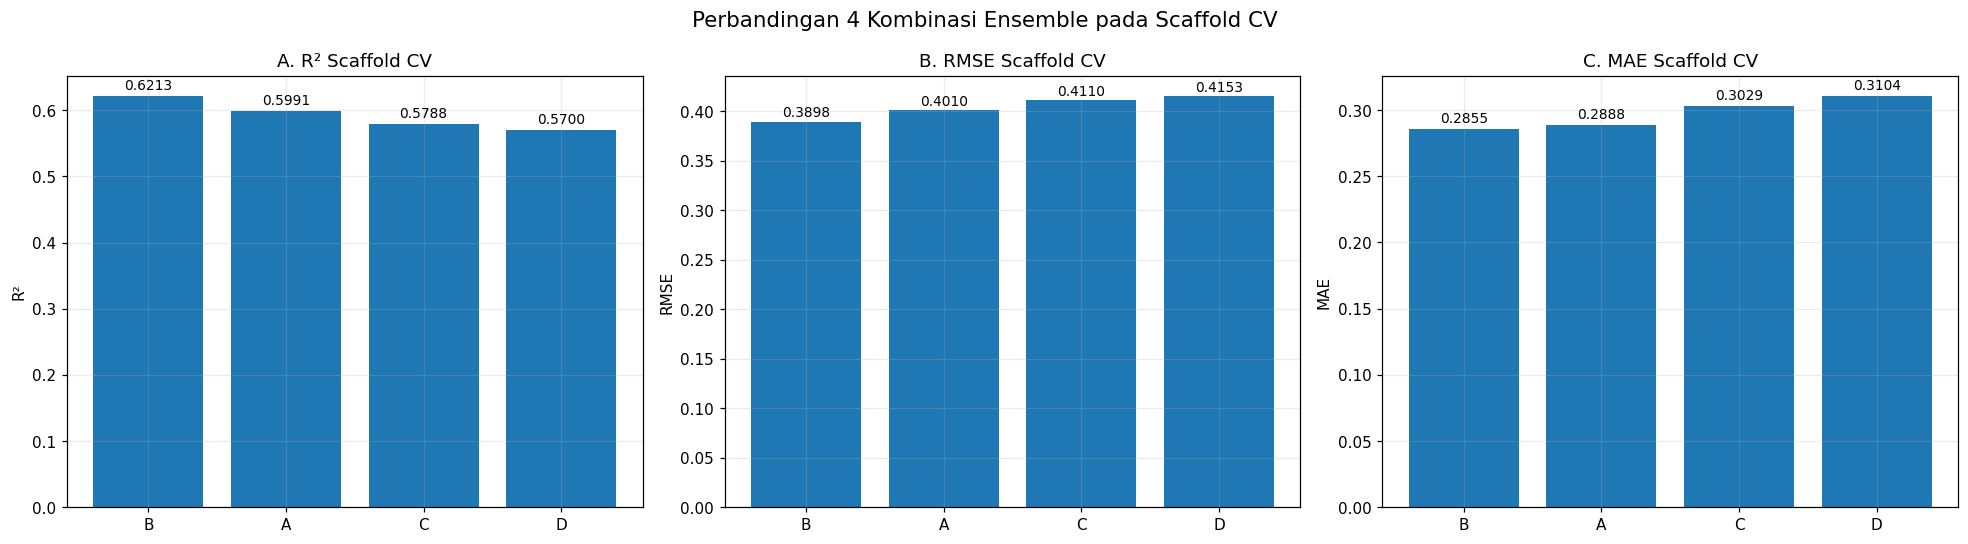

Visualisasi scaffold berhasil disimpan.


In [51]:
import matplotlib.pyplot as plt
import numpy as np

# Urutkan berdasarkan R2 tertinggi
viz_scaf = hasil_scaffold17.sort_values("R2", ascending=False).reset_index(drop=True)

labels = viz_scaf["Kombinasi"].astype(str).tolist()
x = np.arange(len(labels))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# --- Plot R2 ---
axes[0].bar(x, viz_scaf["R2"])
axes[0].set_title("A. R² Scaffold CV")
axes[0].set_xticks(x)
axes[0].set_xticklabels(labels)
axes[0].set_ylabel("R²")
for i, v in enumerate(viz_scaf["R2"]):
    axes[0].text(i, v + 0.01, f"{v:.4f}", ha="center", fontsize=9)

# --- Plot RMSE ---
axes[1].bar(x, viz_scaf["RMSE"])
axes[1].set_title("B. RMSE Scaffold CV")
axes[1].set_xticks(x)
axes[1].set_xticklabels(labels)
axes[1].set_ylabel("RMSE")
for i, v in enumerate(viz_scaf["RMSE"]):
    axes[1].text(i, v + 0.005, f"{v:.4f}", ha="center", fontsize=9)

# --- Plot MAE ---
axes[2].bar(x, viz_scaf["MAE"])
axes[2].set_title("C. MAE Scaffold CV")
axes[2].set_xticks(x)
axes[2].set_xticklabels(labels)
axes[2].set_ylabel("MAE")
for i, v in enumerate(viz_scaf["MAE"]):
    axes[2].text(i, v + 0.005, f"{v:.4f}", ha="center", fontsize=9)

plt.suptitle("Perbandingan 4 Kombinasi Ensemble pada Scaffold CV", fontsize=14)
plt.tight_layout()

plt.savefig(OUT17 / "Visualisasi_ScaffoldCV_4_Kombinasi.png", dpi=300, bbox_inches="tight")
plt.show()

print("Visualisasi scaffold berhasil disimpan.")

## 17.7 Perbandingan Random CV dan Scaffold CV

Tahap ini membandingkan performa keempat kombinasi ensemble
antara protokol Random 5-Fold CV dan Scaffold 5-Fold CV.

Perbandingan ini penting untuk menilai:
1. performa model pada pembagian data acak,
2. kemampuan generalisasi model terhadap scaffold baru, dan
3. apakah kombinasi terbaik pada Random CV tetap unggul pada Scaffold CV.

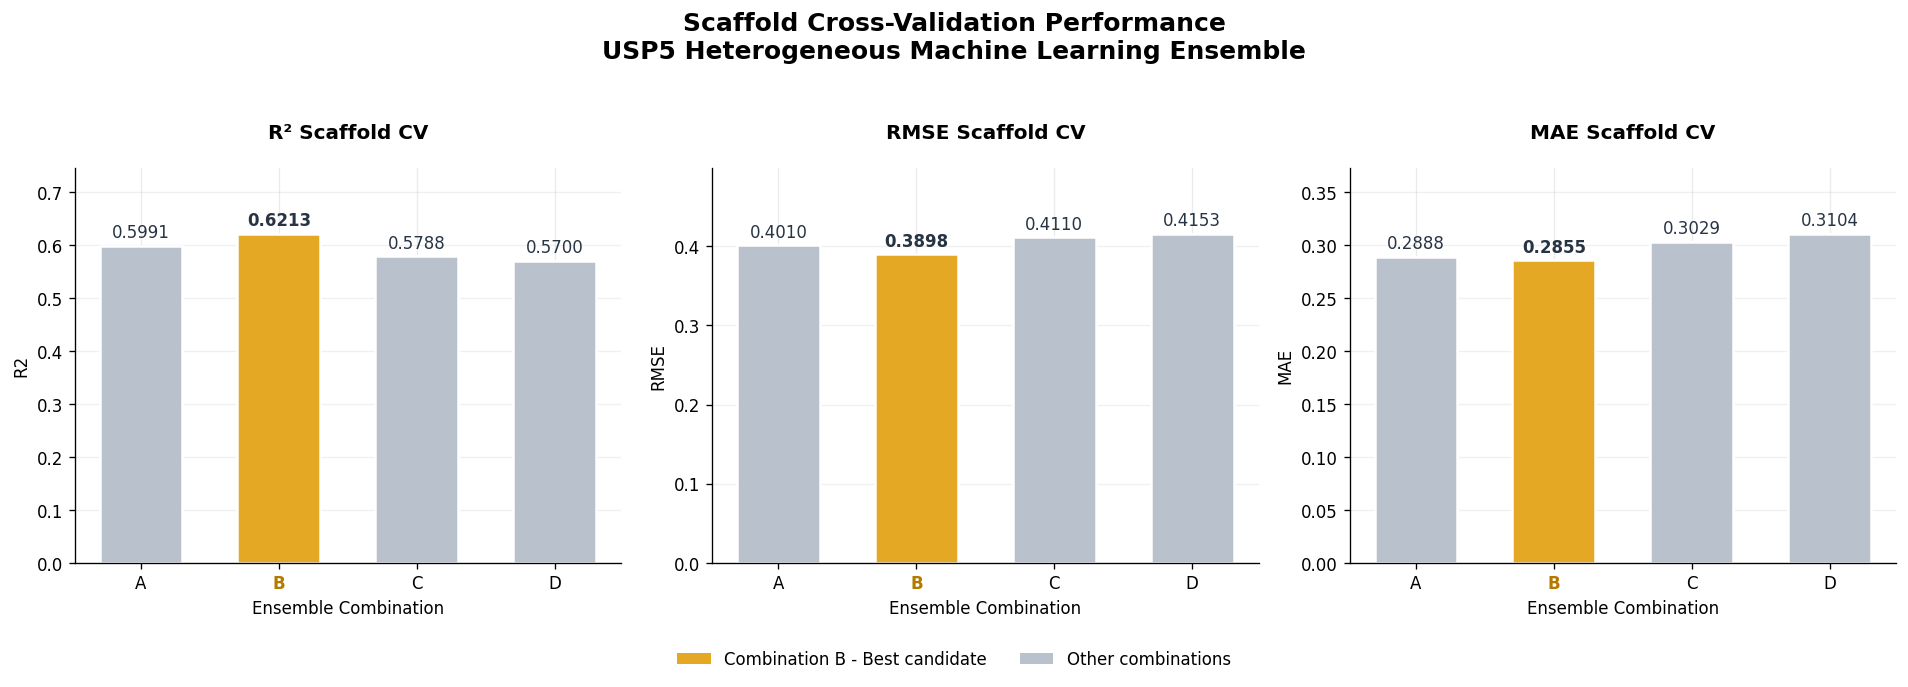

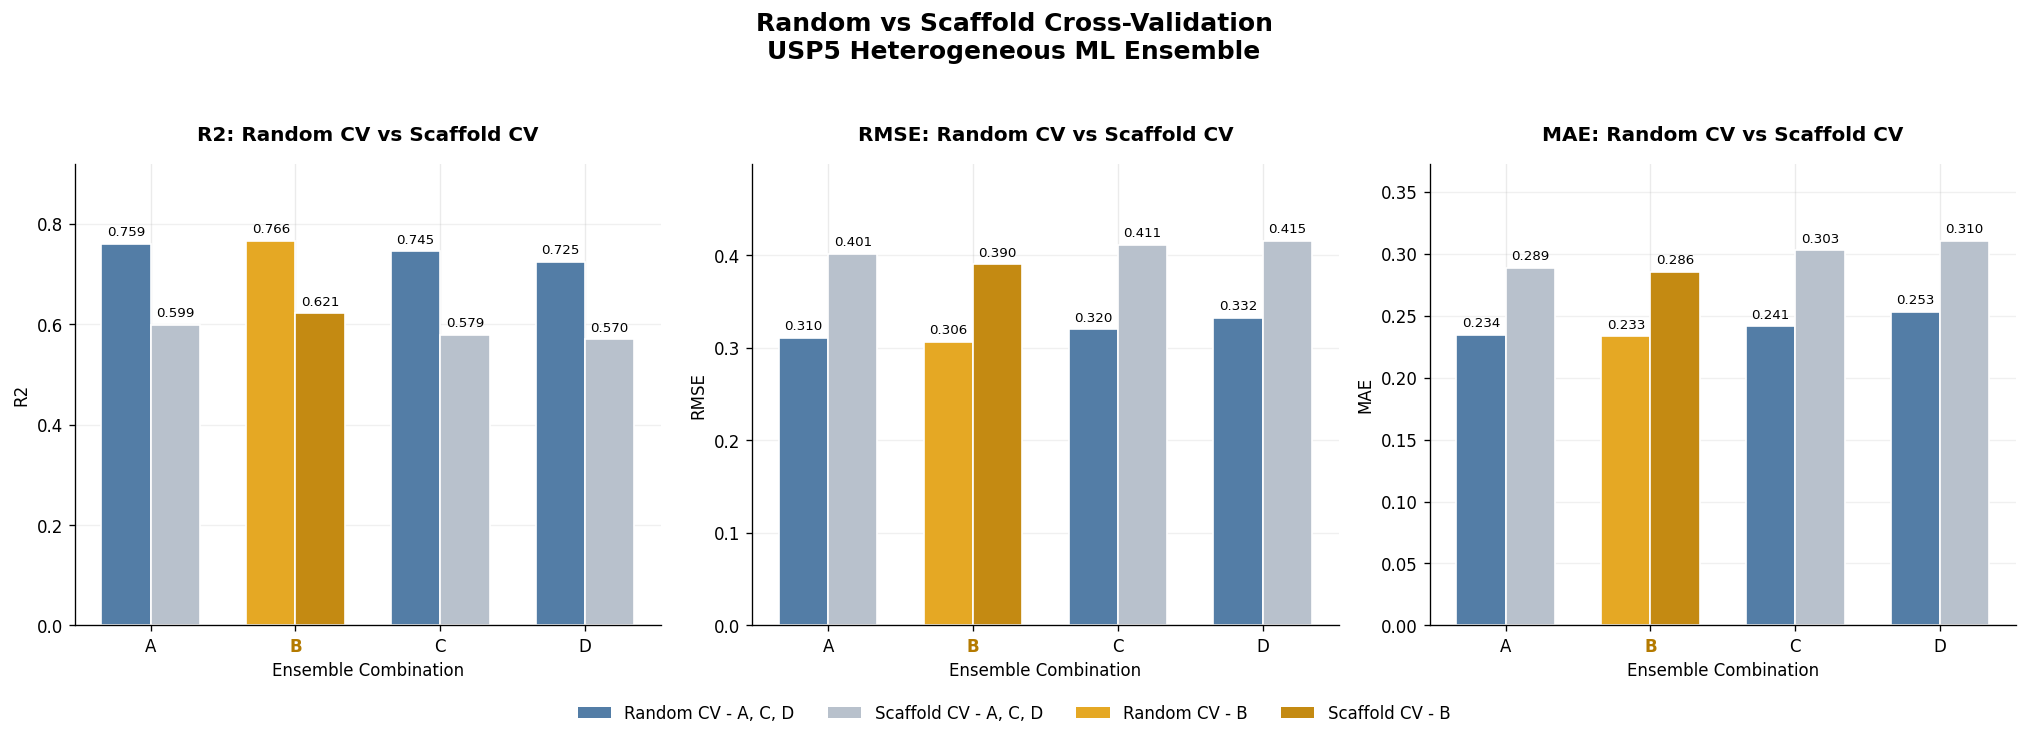

=== VISUALISASI SELESAI ===
1. Scaffold CV dengan highlight B
2. Random vs Scaffold CV dengan highlight B
Folder: /data/Aliya/model/Hasil_ML_Ensemble_Heterogen_80


In [55]:

# ============================================================
# 17.7 VISUALISASI FINAL HETEROGENEOUS ML ENSEMBLE
# HIGHLIGHT KOMBINASI B SEBAGAI KANDIDAT TERBAIK
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# Menggunakan hasil asli eksperimen
order17 = ["A", "B", "C", "D"]

random_viz17 = (
    hasil_random17
    .groupby("Kombinasi")[["R2", "RMSE", "MAE"]]
    .mean()
    .reindex(order17)
)

scaffold_viz17 = (
    hasil_scaffold17
    .set_index("Kombinasi")[["R2", "RMSE", "MAE"]]
    .reindex(order17)
)

assert random_viz17.notna().all().all()
assert scaffold_viz17.notna().all().all()

# Warna
GOLD = "#E5A824"
BLUE = "#537DA6"
GRAY = "#B8C1CC"
DARK = "#273444"

colors17 = [GRAY, GOLD, GRAY, GRAY]

plt.rcParams.update({
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "figure.dpi": 120,
    "savefig.dpi": 300
})

# ============================================================
# GRAFIK 1: SCAFFOLD CV SAJA
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

metrics17 = [
    ("R2", "R² Scaffold CV", "Higher is better"),
    ("RMSE", "RMSE Scaffold CV", "Lower is better"),
    ("MAE", "MAE Scaffold CV", "Lower is better")
]

for ax, (metric, title, subtitle) in zip(axes, metrics17):

    values = scaffold_viz17[metric].to_numpy()

    bars = ax.bar(
        order17,
        values,
        color=colors17,
        width=0.60,
        edgecolor="white",
        linewidth=1.5
    )

    for i, (bar, value) in enumerate(zip(bars, values)):
        ax.annotate(
            f"{value:.4f}",
            xy=(bar.get_x() + bar.get_width()/2, value),
            xytext=(0, 5),
            textcoords="offset points",
            ha="center",
            fontsize=10,
            fontweight="bold" if i == 1 else "normal",
            color=DARK
        )

    ax.set_title(title, fontweight="bold", pad=18)
    ax.set_xlabel("Ensemble Combination")
    ax.set_ylabel(metric)
    ax.set_ylim(0, max(values) * 1.20)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.18)
    ax.set_axisbelow(True)

    # Highlight label B
    for label in ax.get_xticklabels():
        if label.get_text() == "B":
            label.set_fontweight("bold")
            label.set_color("#B47A00")

fig.suptitle(
    "Scaffold Cross-Validation Performance\n"
    "USP5 Heterogeneous Machine Learning Ensemble",
    fontsize=15,
    fontweight="bold",
    y=1.04
)

fig.legend(
    handles=[
        Patch(facecolor=GOLD, label="Combination B - Best candidate"),
        Patch(facecolor=GRAY, label="Other combinations")
    ],
    loc="lower center",
    bbox_to_anchor=(0.5, -0.08),
    ncol=2,
    frameon=False
)

plt.tight_layout()

plt.savefig(
    OUT17 / "17_7_Scaffold_CV_Highlight_B.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


# ============================================================
# GRAFIK 2: RANDOM CV VS SCAFFOLD CV
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(17, 5.5))

x = np.arange(len(order17))
width = 0.34

for ax, (metric, _, subtitle) in zip(axes, metrics17):

    rv = random_viz17[metric].to_numpy()
    sv = scaffold_viz17[metric].to_numpy()

    # Kombinasi lain = biru/abu
    # Kombinasi B = emas terang/emas gelap
    random_colors = [
        GOLD if k == "B" else BLUE
        for k in order17
    ]

    scaffold_colors = [
        "#C48A12" if k == "B" else GRAY
        for k in order17
    ]

    bars_r = ax.bar(
        x - width/2,
        rv,
        width,
        color=random_colors,
        edgecolor="white"
    )

    bars_s = ax.bar(
        x + width/2,
        sv,
        width,
        color=scaffold_colors,
        edgecolor="white"
    )

    for bars in [bars_r, bars_s]:
        for bar in bars:
            height = bar.get_height()

            ax.annotate(
                f"{height:.3f}",
                xy=(bar.get_x() + bar.get_width()/2, height),
                xytext=(0, 5),
                textcoords="offset points",
                ha="center",
                fontsize=8
            )

    ax.set_title(
        f"{metric}: Random CV vs Scaffold CV",
        fontweight="bold",
        pad=14
    )

    ax.set_xticks(x)
    ax.set_xticklabels(order17)
    ax.set_xlabel("Ensemble Combination")
    ax.set_ylabel(metric)
    ax.set_ylim(0, max(rv.max(), sv.max()) * 1.20)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.18)
    ax.set_axisbelow(True)

    for label in ax.get_xticklabels():
        if label.get_text() == "B":
            label.set_fontweight("bold")
            label.set_color("#B47A00")

fig.suptitle(
    "Random vs Scaffold Cross-Validation\n"
    "USP5 Heterogeneous ML Ensemble",
    fontsize=15,
    fontweight="bold",
    y=1.04
)

# Legenda empat warna
fig.legend(
    handles=[
        Patch(facecolor=BLUE, label="Random CV - A, C, D"),
        Patch(facecolor=GRAY, label="Scaffold CV - A, C, D"),
        Patch(facecolor=GOLD, label="Random CV - B"),
        Patch(facecolor="#C48A12", label="Scaffold CV - B")
    ],
    loc="lower center",
    bbox_to_anchor=(0.5, -0.06),
    ncol=4,
    frameon=False
)

plt.tight_layout()

plt.savefig(
    OUT17 / "17_7_Random_vs_Scaffold_Highlight_B.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("=== VISUALISASI SELESAI ===")
print("1. Scaffold CV dengan highlight B")
print("2. Random vs Scaffold CV dengan highlight B")
print("Folder:", OUT17)


In [56]:
best_random = random17_plot.sort_values("R2", ascending=False).iloc[0]
best_scaffold = scaffold17_plot.sort_values("R2", ascending=False).iloc[0]

print("=== RINGKASAN INTERPRETASI ===")
print(
    f"Kombinasi terbaik pada Random CV adalah {best_random['Kombinasi']} "
    f"dengan R2 = {best_random['R2']:.4f}, RMSE = {best_random['RMSE']:.4f}, "
    f"dan MAE = {best_random['MAE']:.4f}."
)
print(
    f"Kombinasi terbaik pada Scaffold CV adalah {best_scaffold['Kombinasi']} "
    f"dengan R2 = {best_scaffold['R2']:.4f}, RMSE = {best_scaffold['RMSE']:.4f}, "
    f"dan MAE = {best_scaffold['MAE']:.4f}."
)

if best_random["Kombinasi"] == best_scaffold["Kombinasi"]:
    print(
        f"Kombinasi {best_random['Kombinasi']} konsisten menjadi yang terbaik "
        f"baik pada Random CV maupun Scaffold CV."
    )
else:
    print(
        "Kombinasi terbaik pada Random CV dan Scaffold CV berbeda, "
        "menunjukkan bahwa performa pada pembagian acak tidak selalu identik "
        "dengan kemampuan generalisasi terhadap scaffold baru."
    )

=== RINGKASAN INTERPRETASI ===
Kombinasi terbaik pada Random CV adalah B dengan R2 = 0.7904, RMSE = 0.2900, dan MAE = 0.2179.
Kombinasi terbaik pada Scaffold CV adalah B dengan R2 = 0.6213, RMSE = 0.3898, dan MAE = 0.2855.
Kombinasi B konsisten menjadi yang terbaik baik pada Random CV maupun Scaffold CV.



## 17.8 Analisis dan Pemilihan Kandidat Model Final

Berdasarkan evaluasi empat kombinasi heterogeneous ensemble,
kombinasi B (Bayesian Ridge + SVR Linear + Gradient Boosting)
menunjukkan performa terbaik pada Random Cross-Validation
dan Scaffold Cross-Validation.

Kombinasi B memperoleh:

Random CV:
- R² = 0,7661
- RMSE = 0,3061
- MAE = 0,2333

Scaffold CV:
- R² = 0,6213
- RMSE = 0,3898
- MAE = 0,2855

Berdasarkan hasil tersebut, kombinasi B dipilih sebagai
kandidat model final untuk prediksi pKd inhibitor USP5.

Model ini selanjutnya dilatih menggunakan seluruh 80 senyawa
untuk menghasilkan artefak model yang dapat digunakan pada
prediksi kandidat senyawa baru.

Hasil cross-validation digunakan sebagai dasar seleksi model,
bukan sebagai hasil pengujian independen setelah seleksi.


In [58]:

# ==================================================
# 17.8.2 TRAINING & PENYIMPANAN MODEL FINAL
# HETEROGENEOUS ML ENSEMBLE USP5
# ==================================================

import joblib
import numpy as np
import pandas as pd
from pathlib import Path

# Folder model final
FINAL_DIR17 = OUT17 / "Model_Final"
FINAL_DIR17.mkdir(parents=True, exist_ok=True)

# 1. Pilih kombinasi B
model_final17 = make_ensemble17("B")

# 2. Training menggunakan 80 senyawa
print("=== TRAINING MODEL FINAL ===")
print("Kombinasi: B")
print("Algoritma:", nama_kombinasi17["B"])
print("Jumlah training:", len(y17))

model_final17.fit(X17, y17)

print("\nTraining berhasil!")

# 3. Simpan model dan informasi fitur
artifact17 = {
    "model": model_final17,
    "kombinasi": "B",
    "algoritma": nama_kombinasi17["B"],
    "jumlah_training": len(y17),
    "jumlah_fitur": X17.shape[1],
    "descriptor_names": desc_names17,
    "morgan_radius": 2,
    "morgan_bits": 1024,
    "maccs_bits": MACCS17.shape[1],
    "training_smiles": smiles17,
    "training_pKd": y17.tolist(),
    "performance": {
        "random_cv": {
            "R2": float(random_viz17.loc["B", "R2"]),
            "RMSE": float(random_viz17.loc["B", "RMSE"]),
            "MAE": float(random_viz17.loc["B", "MAE"])
        },
        "scaffold_cv": {
            "R2": float(scaffold_viz17.loc["B", "R2"]),
            "RMSE": float(scaffold_viz17.loc["B", "RMSE"]),
            "MAE": float(scaffold_viz17.loc["B", "MAE"])
        }
    }
}

model_path17 = (
    FINAL_DIR17 /
    "USP5_Heterogeneous_Ensemble_B_Final_80.joblib"
)

joblib.dump(artifact17, model_path17)

# 4. Verifikasi file tersimpan
assert model_path17.exists()

print("\n=== MODEL BERHASIL DISIMPAN ===")
print("Lokasi:", model_path17)

print("\n=== RINGKASAN MODEL ===")
print("Jumlah training:", len(y17))
print("Jumlah fitur:", X17.shape[1])
print("Model:", nama_kombinasi17["B"])

print("\n=== TAHAP 17.8 SELESAI ===")


=== TRAINING MODEL FINAL ===
Kombinasi: B
Algoritma: Bayesian Ridge + SVR Linear + Gradient Boosting
Jumlah training: 80

Training berhasil!

=== MODEL BERHASIL DISIMPAN ===
Lokasi: /data/Aliya/model/Hasil_ML_Ensemble_Heterogen_80/Model_Final/USP5_Heterogeneous_Ensemble_B_Final_80.joblib

=== RINGKASAN MODEL ===
Jumlah training: 80
Jumlah fitur: 1408
Model: Bayesian Ridge + SVR Linear + Gradient Boosting

=== TAHAP 17.8 SELESAI ===


## 17.10 Analisis Residual dan Applicability Domain

Tahap ini mengevaluasi kesalahan prediksi model terpilih,
yaitu kombinasi B (Bayesian Ridge, SVR Linear, dan
Gradient Boosting).

Analisis residual dilakukan menggunakan prediksi
out-of-fold dari Scaffold 5-Fold Cross-Validation.

Residual dihitung sebagai selisih antara nilai pKd
eksperimen dan nilai pKd prediksi.

Analisis ini bertujuan mengidentifikasi senyawa yang
memiliki kesalahan prediksi terbesar serta mengevaluasi
kecenderungan underprediction dan overprediction.

In [60]:

# ======================================================
# 17.10.1 ANALISIS RESIDUAL MODEL B
# BERDASARKAN SCAFFOLD CROSS-VALIDATION
# ======================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error
)

# Prediksi out-of-fold Scaffold CV kombinasi B
y_true17 = np.asarray(y17, dtype=float)
y_pred_B17 = np.asarray(
    prediksi_scaffold17["B"], dtype=float
)

assert len(y_true17) == len(y_pred_B17) == 80
assert np.isfinite(y_pred_B17).all()

# Residual = eksperimen - prediksi
residual_B17 = y_true17 - y_pred_B17
abs_error_B17 = np.abs(residual_B17)

# Membuat tabel analisis
residual_df17 = pd.DataFrame({
    "SMILES": smiles17,
    "Scaffold": scaffold17,
    "pKd_Eksperimen": y_true17,
    "pKd_Prediksi": y_pred_B17,
    "Residual": residual_B17,
    "Absolute_Error": abs_error_B17
})

# Identifikasi prediksi
residual_df17["Kategori"] = np.where(
    residual_df17["Residual"] > 0,
    "Underprediction",
    np.where(
        residual_df17["Residual"] < 0,
        "Overprediction",
        "Tepat"
    )
)

# Urutkan berdasarkan kesalahan terbesar
residual_rank17 = residual_df17.sort_values(
    "Absolute_Error", ascending=False
)

print("=== ANALISIS RESIDUAL MODEL B ===")
print("Jumlah senyawa:", len(residual_df17))
print("R2:", round(r2_score(y_true17, y_pred_B17), 4))
print("RMSE:", round(np.sqrt(
    mean_squared_error(y_true17, y_pred_B17)
), 4))
print("MAE:", round(mean_absolute_error(
    y_true17, y_pred_B17
), 4))

print("\nUnderprediction:",
      (residual_df17["Kategori"] == "Underprediction").sum())

print("Overprediction:",
      (residual_df17["Kategori"] == "Overprediction").sum())

print("\n=== 10 SENYAWA DENGAN ERROR TERBESAR ===")
display(residual_rank17[[
    "SMILES",
    "pKd_Eksperimen",
    "pKd_Prediksi",
    "Residual",
    "Absolute_Error",
    "Kategori"
]].head(10).round(4))

# Simpan tabel
residual_df17.to_csv(
    OUT17 / "17_10_Residual_Model_B.csv",
    index=False
)

print("\n=== ANALISIS RESIDUAL SELESAI ===")


=== ANALISIS RESIDUAL MODEL B ===
Jumlah senyawa: 80
R2: 0.6213
RMSE: 0.3898
MAE: 0.2855

Underprediction: 41
Overprediction: 39

=== 10 SENYAWA DENGAN ERROR TERBESAR ===


,SMILES,pKd_Eksperimen,pKd_Prediksi,Residual,Absolute_Error,Kategori
77,COc1ccccc1CNC(=O)Cn1c(CCC(=O)O)nc2c(Cl)cccc2c1=O,5.3468,3.9839,1.3629,1.3629,Underprediction
76,COc1ccccc1CN(C)C(=O)Cn1c(CCC(=O)O)nc2c(Cl)cccc...,5.2007,4.0141,1.1865,1.1865,Underprediction
79,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(c3ccc(Cl)cc3...,5.5528,4.5762,0.9766,0.9766,Underprediction
78,O=C([O-])CNC(=O)c1ccc(S(=O)(=O)N2CCC(c3ccc(Cl)...,5.5086,4.5332,0.9755,0.9755,Underprediction
22,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(c3ccccc3)CC2...,3.6778,4.6397,-0.9619,0.9619,Overprediction
74,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(c3ccccc3)CC2...,5.1549,4.3834,0.7715,0.7715,Underprediction
45,CC(C(=O)O)n1cnc2ccccc2c1=O,4.2218,3.5474,0.6744,0.6744,Underprediction
71,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(c3ccccc3)CC2...,5.0458,4.4970,0.5487,0.5487,Underprediction
39,CC(C)c1ccc(C(=O)CCC(=O)O)cc1,4.0969,3.5634,0.5335,0.5335,Underprediction
60,CN1CCC2(CC1)CCN(S(=O)(=O)c1ccc(C(=O)NCC(=O)O)c...,4.6021,4.0814,0.5206,0.5206,Underprediction



=== ANALISIS RESIDUAL SELESAI ===


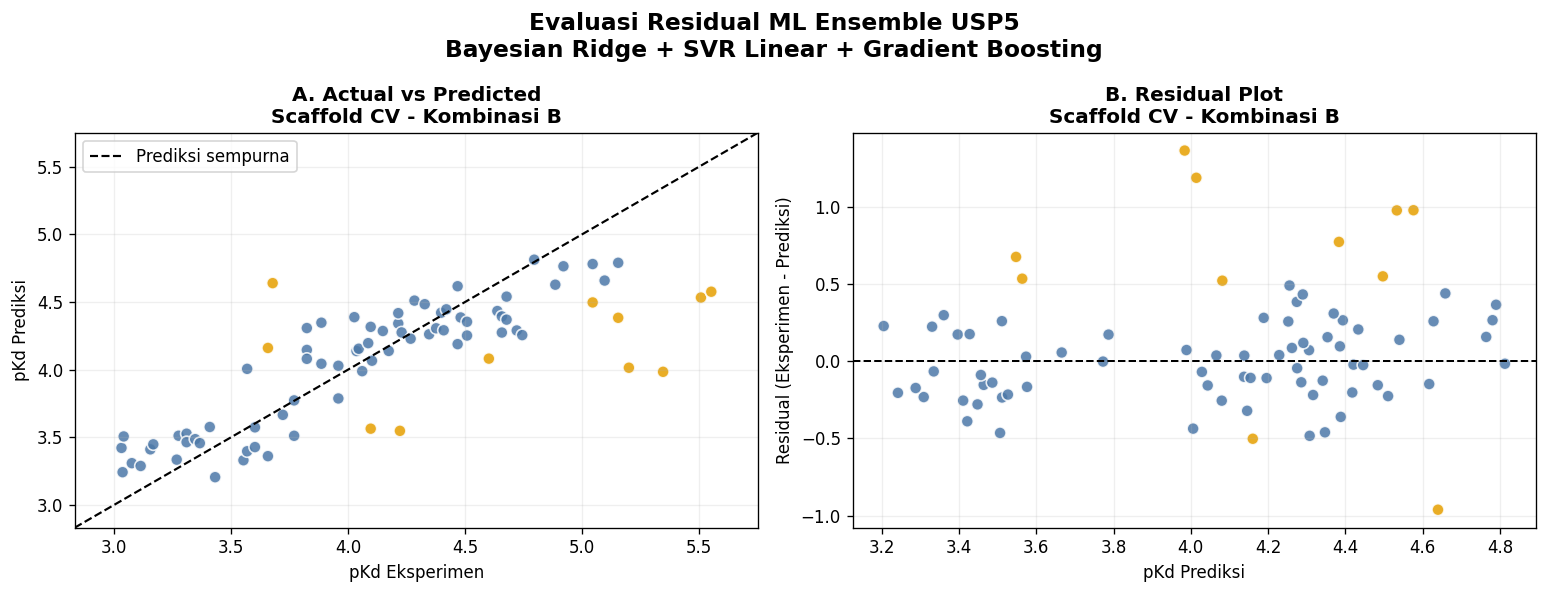

=== VISUALISASI RESIDUAL BERHASIL ===


In [61]:

# ======================================================
# 17.10.2 VISUALISASI RESIDUAL MODEL B
# ======================================================

import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Warna berdasarkan besar error
warna17 = np.where(
    abs_error_B17 >= 0.5,
    "#E69F00",
    "#4C78A8"
)

# Grafik 1: Actual vs Predicted
axes[0].scatter(
    y_true17, y_pred_B17,
    c=warna17, s=52, alpha=0.85,
    edgecolors="white"
)

batas17 = [
    min(y_true17.min(), y_pred_B17.min()) - 0.2,
    max(y_true17.max(), y_pred_B17.max()) + 0.2
]

axes[0].plot(
    batas17, batas17,
    "k--", linewidth=1.3,
    label="Prediksi sempurna"
)

axes[0].set_xlim(batas17)
axes[0].set_ylim(batas17)
axes[0].set_xlabel("pKd Eksperimen")
axes[0].set_ylabel("pKd Prediksi")
axes[0].set_title(
    "A. Actual vs Predicted\n"
    "Scaffold CV - Kombinasi B",
    fontweight="bold"
)
axes[0].legend()
axes[0].grid(alpha=0.2)

# Grafik 2: Residual
axes[1].scatter(
    y_pred_B17, residual_B17,
    c=warna17, s=52, alpha=0.85,
    edgecolors="white"
)

axes[1].axhline(
    0, color="black",
    linestyle="--",
    linewidth=1.2
)

axes[1].set_xlabel("pKd Prediksi")
axes[1].set_ylabel("Residual (Eksperimen - Prediksi)")
axes[1].set_title(
    "B. Residual Plot\n"
    "Scaffold CV - Kombinasi B",
    fontweight="bold"
)
axes[1].grid(alpha=0.2)

fig.suptitle(
    "Evaluasi Residual ML Ensemble USP5\n"
    "Bayesian Ridge + SVR Linear + Gradient Boosting",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    OUT17 / "17_10_Residual_Visualization_Model_B.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("=== VISUALISASI RESIDUAL BERHASIL ===")



### 17.10.3 Interpretasi Hasil Analisis Residual

Berdasarkan evaluasi **Scaffold 5-Fold Cross-Validation**, model Heterogeneous ML Ensemble kombinasi B (Bayesian Ridge + SVR Linear + Gradient Boosting) menghasilkan nilai **R² sebesar 0,6213, RMSE sebesar 0,3898, dan MAE sebesar 0,2855**.

#### A. Interpretasi Actual vs Predicted

Grafik Actual vs Predicted menunjukkan bahwa sebagian besar nilai prediksi pKd mengikuti kecenderungan nilai eksperimen, meskipun masih terdapat penyimpangan dari garis diagonal yang menunjukkan prediksi sempurna.

Pada senyawa dengan nilai pKd eksperimen tinggi (pKd > 5), beberapa titik berada di bawah garis diagonal. Hal ini menunjukkan adanya kecenderungan **underprediction**, yaitu model memprediksi pKd lebih rendah daripada nilai eksperimen.

#### B. Interpretasi Residual Plot

Analisis residual menunjukkan bahwa:
- **41 senyawa (51,25%)** mengalami underprediction.
- **39 senyawa (48,75%)** mengalami overprediction.

Meskipun jumlah kedua kategori relatif seimbang, beberapa senyawa menunjukkan residual positif yang cukup besar, terutama pada kelompok pKd tinggi.

Kesalahan prediksi terbesar ditemukan pada senyawa dengan pKd eksperimen sebesar **5,3468** dan pKd prediksi sebesar **3,9839**, menghasilkan residual **+1,3629**.

Temuan ini menunjukkan bahwa model masih mengalami kesulitan dalam memprediksi beberapa senyawa dengan afinitas tinggi.

#### C. Interpretasi Keseluruhan

Secara keseluruhan, kombinasi B menunjukkan kemampuan prediksi yang menjanjikan berdasarkan hasil Scaffold Cross-Validation. Namun, model masih memiliki keterbatasan dalam memprediksi sejumlah senyawa dengan pKd tinggi.

Kecenderungan tersebut dapat berkaitan dengan distribusi data yang tidak seimbang, mengingat hanya **9 dari 80 senyawa** memiliki nilai pKd di atas 5.

Oleh karena itu, analisis **Applicability Domain menggunakan Tanimoto Similarity** diperlukan untuk mengevaluasi hubungan antara kemiripan struktur molekul dan besarnya kesalahan prediksi, terutama pada senyawa yang belum pernah ditemukan dalam data pelatihan.



### 17.10.4 Analisis Applicability Domain Menggunakan Tanimoto Similarity

Analisis applicability domain dilakukan untuk mengevaluasi
hubungan antara kemiripan struktur molekul dan kesalahan
prediksi model Heterogeneous ML Ensemble kombinasi B.

Kemiripan molekul dihitung menggunakan Tanimoto Similarity
berdasarkan Morgan Binary Fingerprint (radius 2, 2048 bit).

Untuk menghindari kebocoran informasi, setiap senyawa validasi
hanya dibandingkan dengan senyawa pada training fold yang
bersesuaian dalam Scaffold 5-Fold Cross-Validation.

Analisis dilakukan dengan:
1. Menghitung kemiripan Tanimoto maksimum terhadap training fold.
2. Mengidentifikasi senyawa dengan kesalahan prediksi terbesar.
3. Mengevaluasi hubungan Tanimoto Similarity dengan absolute error
   menggunakan korelasi Spearman.
4. Memvisualisasikan hubungan kemiripan struktur dan kesalahan prediksi.

Skor Tanimoto digunakan sebagai indikator kemiripan struktur,
bukan sebagai jaminan ketepatan prediksi.


Fold 1: 23 senyawa selesai
Fold 2: 15 senyawa selesai
Fold 3: 14 senyawa selesai
Fold 4: 14 senyawa selesai
Fold 5: 14 senyawa selesai

=== HASIL APPLICABILITY DOMAIN ===
Jumlah senyawa: 80
Tanimoto minimum: 0.1846
Tanimoto maksimum: 0.9149
Tanimoto rata-rata: 0.6102
Spearman rho: -0.1599
p-value: 0.1565

=== 10 SENYAWA ERROR TERBESAR ===


,SMILES,Scaffold,pKd_Eksperimen,pKd_Prediksi,Tanimoto_Max_Training,Absolute_Error
77,COc1ccccc1CNC(=O)Cn1c(CCC(=O)O)nc2c(Cl)cccc2c1=O,O=C(Cn1cnc2ccccc2c1=O)NCc1ccccc1,5.3468,3.9839,0.2917,1.3629
76,COc1ccccc1CN(C)C(=O)Cn1c(CCC(=O)O)nc2c(Cl)cccc...,O=C(Cn1cnc2ccccc2c1=O)NCc1ccccc1,5.2007,4.0141,0.2877,1.1865
79,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(c3ccc(Cl)cc3...,O=S(=O)(c1cccnc1)N1CCC(c2ccccc2)CC1,5.5528,4.5762,0.7455,0.9766
78,O=C([O-])CNC(=O)c1ccc(S(=O)(=O)N2CCC(c3ccc(Cl)...,O=S(=O)(c1cccnc1)N1CCC(c2ccccc2)CC1,5.5086,4.5332,0.6167,0.9755
22,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(c3ccccc3)CC2...,O=S(=O)(c1ccccc1)N1CCC(c2ccccc2)CC1,3.6778,4.6397,0.6842,0.9619
74,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(c3ccccc3)CC2...,O=S(=O)(c1cccnc1)N1CCC(c2ccccc2)CC1,5.1549,4.3834,0.7170,0.7715
45,CC(C(=O)O)n1cnc2ccccc2c1=O,O=c1[nH]cnc2ccccc12,4.2218,3.5474,0.2955,0.6744
71,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(c3ccccc3)CC2...,O=S(=O)(c1ccccc1)N1CCC(c2ccccc2)CC1,5.0458,4.4970,0.7193,0.5487
39,CC(C)c1ccc(C(=O)CCC(=O)O)cc1,c1ccccc1,4.0969,3.5634,0.5143,0.5335
60,CN1CCC2(CC1)CCN(S(=O)(=O)c1ccc(C(=O)NCC(=O)O)c...,O=S(=O)(c1ccccc1)N1CCC2(CCNCC2)CC1,4.6021,4.0814,0.6792,0.5206


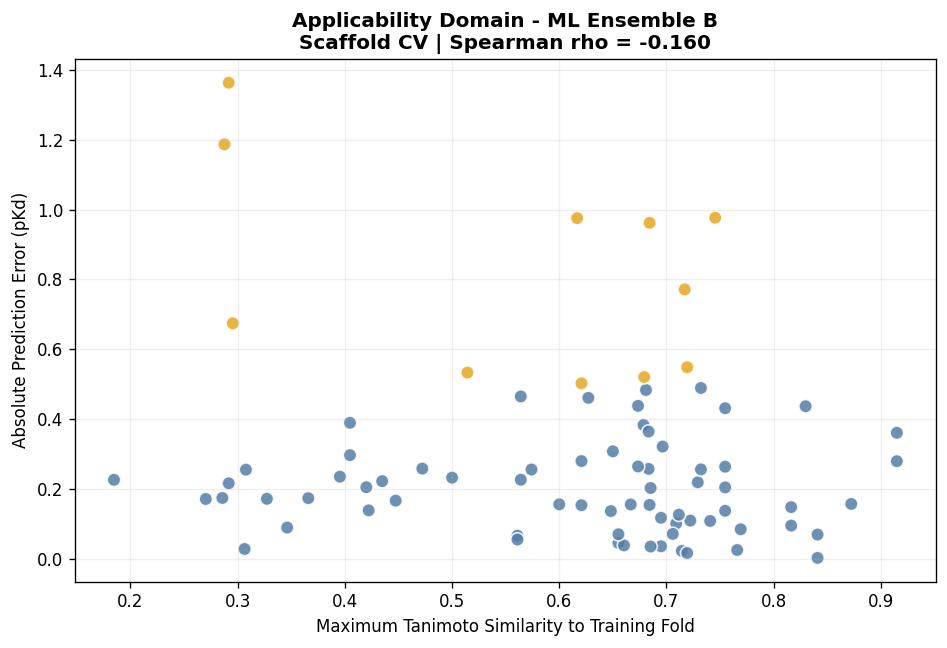


=== ANALISIS TANIMOTO SELESAI ===


In [62]:

# ======================================================
# 17.10.5 APPLICABILITY DOMAIN - TANIMOTO SIMILARITY
# MODEL B - SCAFFOLD CROSS-VALIDATION
# ======================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from rdkit import DataStructs
from rdkit.Chem import rdFingerprintGenerator
from sklearn.model_selection import GroupKFold
from scipy.stats import spearmanr

# 1. Morgan Binary Fingerprint
fpgen_ad17 = rdFingerprintGenerator.GetMorganGenerator(
    radius=2, fpSize=2048
)

fps_ad17 = [
    fpgen_ad17.GetFingerprint(m)
    for m in mols17
]

# 2. Hitung Tanimoto hanya ke TRAINING FOLD
similarity_ad17 = np.full(len(y17), np.nan)

gkf_ad17 = GroupKFold(n_splits=5)

for fold, (tr, te) in enumerate(
    gkf_ad17.split(X17, y17, groups=scaffold17),
    start=1
):
    train_fps = [fps_ad17[i] for i in tr]

    for idx in te:
        sims = DataStructs.BulkTanimotoSimilarity(
            fps_ad17[idx], train_fps
        )
        similarity_ad17[idx] = max(sims)

    print(f"Fold {fold}: {len(te)} senyawa selesai")

assert np.isfinite(similarity_ad17).all()

# 3. Gunakan error Scaffold CV Model B
absolute_error_ad17 = np.abs(
    y17 - prediksi_scaffold17["B"]
)

# 4. Korelasi Spearman
rho17, pval17 = spearmanr(
    similarity_ad17, absolute_error_ad17
)

# 5. Tabel hasil
ad_df17 = pd.DataFrame({
    "SMILES": smiles17,
    "Scaffold": scaffold17,
    "pKd_Eksperimen": y17,
    "pKd_Prediksi": prediksi_scaffold17["B"],
    "Tanimoto_Max_Training": similarity_ad17,
    "Absolute_Error": absolute_error_ad17
})

print("\n=== HASIL APPLICABILITY DOMAIN ===")
print("Jumlah senyawa:", len(ad_df17))
print("Tanimoto minimum:", round(similarity_ad17.min(), 4))
print("Tanimoto maksimum:", round(similarity_ad17.max(), 4))
print("Tanimoto rata-rata:", round(similarity_ad17.mean(), 4))
print("Spearman rho:", round(rho17, 4))
print("p-value:", round(pval17, 4))

print("\n=== 10 SENYAWA ERROR TERBESAR ===")
display(
    ad_df17.sort_values(
        "Absolute_Error", ascending=False
    ).head(10).round(4)
)

# Simpan tabel
ad_df17.to_csv(
    OUT17 / "17_10_Applicability_Domain_Model_B.csv",
    index=False
)

# 6. Visualisasi
fig, ax = plt.subplots(figsize=(8, 5.5))

colors = np.where(
    absolute_error_ad17 >= 0.5,
    "#E5A824",
    "#537DA6"
)

ax.scatter(
    similarity_ad17,
    absolute_error_ad17,
    c=colors,
    s=65,
    alpha=0.85,
    edgecolors="white"
)

ax.set_xlabel("Maximum Tanimoto Similarity to Training Fold")
ax.set_ylabel("Absolute Prediction Error (pKd)")
ax.set_title(
    "Applicability Domain - ML Ensemble B\n"
    f"Scaffold CV | Spearman rho = {rho17:.3f}",
    fontweight="bold"
)

ax.grid(alpha=0.2)

plt.tight_layout()
plt.savefig(
    OUT17 / "17_10_Tanimoto_vs_Error_Model_B.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("\n=== ANALISIS TANIMOTO SELESAI ===")



### 17.10.6 Interpretasi Hasil Applicability Domain

Analisis applicability domain dilakukan menggunakan **Tanimoto Similarity berbasis Morgan Binary Fingerprint (radius 2, 2048 bit)** terhadap 80 senyawa inhibitor USP5.

Perhitungan dilakukan dengan membandingkan setiap senyawa validasi terhadap senyawa pada training fold yang bersesuaian dalam Scaffold 5-Fold Cross-Validation.

#### A. Distribusi Tanimoto Similarity

Hasil analisis menunjukkan:

- Tanimoto Similarity minimum: **0,1846**
- Tanimoto Similarity maksimum: **0,9149**
- Tanimoto Similarity rata-rata: **0,6102**

Nilai tersebut menunjukkan adanya variasi tingkat kemiripan struktur molekul terhadap data pelatihan.

Sebagian senyawa memiliki kemiripan relatif tinggi, sedangkan senyawa lainnya memiliki struktur yang lebih berbeda dari molekul pada training fold.

#### B. Hubungan Tanimoto Similarity dengan Absolute Error

Analisis korelasi Spearman menghasilkan:

- Koefisien korelasi (ρ): **−0,1599**
- p-value: **0,1565**

Nilai koefisien korelasi menunjukkan hubungan negatif yang lemah antara Tanimoto Similarity dan absolute prediction error.

Hal ini mengindikasikan kecenderungan bahwa senyawa dengan kemiripan lebih tinggi memiliki kesalahan prediksi yang lebih kecil.

Namun, karena **p-value > 0,05**, hubungan tersebut tidak signifikan secara statistik. Oleh karena itu, belum terdapat bukti yang cukup untuk menyatakan bahwa tingkat kemiripan struktur berhubungan secara konsisten dengan besarnya kesalahan prediksi.

#### C. Analisis Senyawa dengan Kesalahan Prediksi Terbesar

Dua senyawa dengan kesalahan prediksi terbesar memiliki:

| Indeks | pKd Eksperimen | Tanimoto Similarity | Absolute Error |
|---|---|---|---|
| 77 | 5,3468 | 0,2917 | 1,3629 |
| 76 | 5,2007 | 0,2877 | 1,1865 |
| 79 | 5,5528 | 0,7455 | 0,9766 |
| 78 | 5,5086 | 0,6167 | 0,9755 |

Senyawa indeks 77 dan 76 menunjukkan kemiripan struktur relatif rendah dan kesalahan prediksi yang besar. Hal tersebut mengindikasikan adanya kesulitan model dalam memprediksi sebagian senyawa yang berbeda dari data pelatihan.

Namun, senyawa indeks 79 dan 78 tetap menunjukkan kesalahan prediksi besar meskipun memiliki tingkat kemiripan yang lebih tinggi.

Temuan ini menunjukkan bahwa **kemiripan struktur saja belum cukup untuk menjelaskan besarnya kesalahan prediksi model**.

#### D. Kesimpulan Applicability Domain

Analisis menunjukkan bahwa Tanimoto Similarity dapat digunakan sebagai indikator kedekatan struktur molekul terhadap data pelatihan.

Namun, hubungan yang lemah dan tidak signifikan antara Tanimoto Similarity dan absolute error menunjukkan bahwa skor kemiripan belum dapat digunakan sebagai indikator tunggal untuk menjamin ketepatan prediksi.

Oleh karena itu, penggunaan model Heterogeneous ML Ensemble kombinasi B untuk memprediksi senyawa baru perlu mempertimbangkan skor kemiripan struktur, distribusi pKd data pelatihan, serta keterbatasan model dalam memprediksi senyawa berafinitas tinggi.

Penetapan batas applicability domain yang dapat memisahkan prediksi andal dan tidak andal masih memerlukan validasi lebih lanjut.



## 17.11 Evaluasi Performa pada Senyawa Berafinitas Tinggi

Tahap ini bertujuan mengevaluasi kemampuan Heterogeneous ML
Ensemble Kombinasi B dalam memprediksi senyawa inhibitor USP5
dengan nilai pKd > 5.

Analisis dilakukan terhadap prediksi out-of-fold dari
Scaffold 5-Fold Cross-Validation.

Performa kelompok pKd > 5 dibandingkan dengan kelompok
pKd <= 5 menggunakan metrik MAE, RMSE, serta arah
kesalahan prediksi.

Evaluasi ini penting untuk mengidentifikasi keterbatasan
model terhadap senyawa dengan afinitas relatif tinggi.


=== EVALUASI KELOMPOK pKd ===


,Kelompok,Jumlah,MAE,RMSE,Underprediction,Overprediction,Bias_Pred_minus_Actual
0,pKd <= 5,71,0.2247,0.2831,32,39,0.0215
1,pKd > 5,9,0.7655,0.8474,9,0,-0.7655



=== SENYAWA pKd > 5 ===


,SMILES,pKd_Eksperimen,pKd_Prediksi,Residual,Absolute_Error
6,COc1ccccc1CNC(=O)Cn1c(CCC(=O)O)nc2c(Cl)cccc2c1=O,5.3468,3.9839,1.3629,1.3629
5,COc1ccccc1CN(C)C(=O)Cn1c(CCC(=O)O)nc2c(Cl)cccc...,5.2007,4.0141,1.1865,1.1865
8,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(c3ccc(Cl)cc3...,5.5528,4.5762,0.9766,0.9766
7,O=C([O-])CNC(=O)c1ccc(S(=O)(=O)N2CCC(c3ccc(Cl)...,5.5086,4.5332,0.9755,0.9755
3,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(c3ccccc3)CC2...,5.1549,4.3834,0.7715,0.7715
0,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(c3ccccc3)CC2...,5.0458,4.4970,0.5487,0.5487
2,O=C(O)CCC(=O)c1ccc(S(=O)(=O)N2CCC(c3ccccc3)CC2...,5.0969,4.6587,0.4382,0.4382
4,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(c3ccc(Cl)cc3...,5.1549,4.7901,0.3648,0.3648
1,O=C(O)CCC(=O)c1ccc(S(=O)(=O)N2CCC(N3CCCC3)CC2)cc1,5.0458,4.7809,0.2648,0.2648


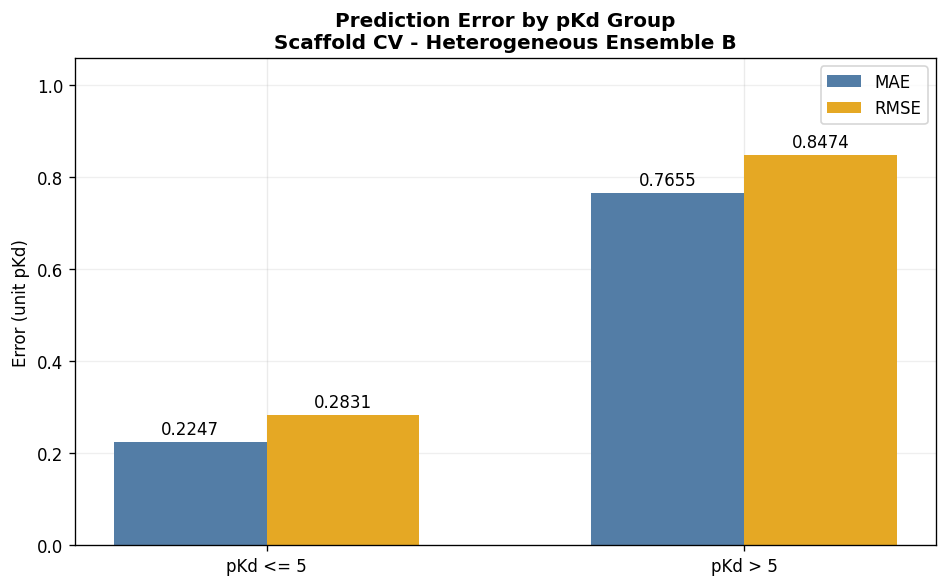


=== TAHAP 17.11 SELESAI ===


In [63]:

# ====================================================
# 17.11 ANALISIS KELOMPOK pKd TINGGI
# HETEROGENEOUS ML ENSEMBLE B
# ====================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Prediksi Scaffold CV yang sudah dihitung sebelumnya
actual17 = np.asarray(y17, dtype=float)
pred17 = np.asarray(prediksi_scaffold17["B"], dtype=float)

assert len(actual17) == len(pred17) == 80

high17 = actual17 > 5
low17 = ~high17

def evaluate_group17(mask, label):
    yt = actual17[mask]
    yp = pred17[mask]

    return {
        "Kelompok": label,
        "Jumlah": len(yt),
        "MAE": mean_absolute_error(yt, yp),
        "RMSE": np.sqrt(mean_squared_error(yt, yp)),
        "Underprediction": int(np.sum(yp < yt)),
        "Overprediction": int(np.sum(yp > yt)),
        "Bias_Pred_minus_Actual": np.mean(yp - yt)
    }

hasil_high17 = pd.DataFrame([
    evaluate_group17(low17, "pKd <= 5"),
    evaluate_group17(high17, "pKd > 5")
])

print("=== EVALUASI KELOMPOK pKd ===")
display(hasil_high17.round(4))

# Tabel sembilan senyawa pKd tinggi
detail_high17 = pd.DataFrame({
    "SMILES": np.asarray(smiles17)[high17],
    "pKd_Eksperimen": actual17[high17],
    "pKd_Prediksi": pred17[high17],
    "Residual": actual17[high17] - pred17[high17],
    "Absolute_Error": np.abs(actual17[high17] - pred17[high17])
}).sort_values("Absolute_Error", ascending=False)

print("\n=== SENYAWA pKd > 5 ===")
display(detail_high17.round(4))

# Grafik perbandingan MAE dan RMSE
fig, ax = plt.subplots(figsize=(8, 5))
x = np.arange(2)
w = 0.32

b1 = ax.bar(
    x - w/2, hasil_high17["MAE"], w,
    label="MAE", color="#537DA6"
)
b2 = ax.bar(
    x + w/2, hasil_high17["RMSE"], w,
    label="RMSE", color="#E5A824"
)

for bars in [b1, b2]:
    for bar in bars:
        h = bar.get_height()
        ax.annotate(
            f"{h:.4f}",
            (bar.get_x() + bar.get_width()/2, h),
            xytext=(0, 5),
            textcoords="offset points",
            ha="center"
        )

ax.set_xticks(x)
ax.set_xticklabels(hasil_high17["Kelompok"])
ax.set_ylabel("Error (unit pKd)")
ax.set_title(
    "Prediction Error by pKd Group\n"
    "Scaffold CV - Heterogeneous Ensemble B",
    fontweight="bold"
)
ax.set_ylim(0, max(hasil_high17["RMSE"]) * 1.25)
ax.legend()
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig(
    OUT17 / "17_11_Error_by_pKd_Group.png",
    dpi=300, bbox_inches="tight"
)
plt.show()

# Simpan data
hasil_high17.to_csv(
    OUT17 / "17_11_Hasil_Kelompok_pKd.csv",
    index=False
)
detail_high17.to_csv(
    OUT17 / "17_11_Detail_pKd_Tinggi.csv",
    index=False
)

print("\n=== TAHAP 17.11 SELESAI ===")



## 17.12 Pelatihan dan Penyimpanan Model Final

Berdasarkan perbandingan lima konfigurasi Heterogeneous ML
Ensemble, Kombinasi B dipilih sebagai kandidat model final.

Kombinasi B terdiri atas:
1. Bayesian Ridge
2. Support Vector Regression (SVR) Linear
3. Gradient Boosting Regressor

Model dilatih menggunakan seluruh 80 senyawa inhibitor USP5,
kemudian disimpan dalam format joblib.

Nilai performa yang dilaporkan tetap berasal dari
cross-validation, bukan evaluasi pada data training.

Pemilihan model berdasarkan cross-validation merupakan
tahap seleksi, sehingga validasi independen tetap
diperlukan untuk memastikan kemampuan generalisasi akhir.


In [64]:

# ====================================================
# 17.12 TRAINING & PENYIMPANAN MODEL FINAL
# ====================================================

import joblib
import numpy as np
import sklearn
import rdkit
from pathlib import Path

FINAL_DIR17 = OUT17 / "Model_Final"
FINAL_DIR17.mkdir(parents=True, exist_ok=True)

# Training model terpilih
final_model17 = make_ensemble17("B")

print("=== TRAINING FINAL ===")
print("Model: Kombinasi B")
print("Jumlah senyawa:", len(y17))
print("Jumlah fitur:", X17.shape[1])

final_model17.fit(X17, y17)

# Simpan model beserta spesifikasi fitur
artifact_final17 = {
    "model": final_model17,
    "kombinasi": "B",
    "algoritma": nama_kombinasi17["B"],
    "jumlah_training": len(y17),
    "jumlah_fitur": X17.shape[1],
    "descriptor_names": list(desc_names17),
    "morgan_radius": 2,
    "morgan_bits": 1024,
    "morgan_type": "count",
    "maccs_bits": MACCS17.shape[1],
    "feature_order": ["DESC", "MORGAN", "MACCS"],
    "training_smiles": list(smiles17),
    "sklearn_version": sklearn.__version__,
    "rdkit_version": rdkit.__version__,
    "performance": {
        "random_cv": (
            hasil_random17[
                hasil_random17["Kombinasi"] == "B"
            ][["R2", "RMSE", "MAE"]].mean().to_dict()
        ),
        "scaffold_cv": (
            hasil_scaffold17[
                hasil_scaffold17["Kombinasi"] == "B"
            ][["R2", "RMSE", "MAE"]].iloc[0].to_dict()
        )
    }
}

model_path17 = (
    FINAL_DIR17 /
    "USP5_Heterogeneous_Ensemble_B_Final_80.joblib"
)

joblib.dump(artifact_final17, model_path17)

print("\n=== MODEL DISIMPAN ===")
print("Lokasi:", model_path17)
print("Ukuran file:", round(model_path17.stat().st_size / 1024, 2), "KB")

# Verifikasi pemuatan dan konsistensi prediksi
loaded17 = joblib.load(model_path17)

pred_sebelum17 = final_model17.predict(X17)
pred_sesudah17 = loaded17["model"].predict(X17)

assert np.allclose(pred_sebelum17, pred_sesudah17)

print("\nVerifikasi prediksi: BERHASIL")
print("Jumlah output:", len(pred_sesudah17))
print("Semua prediksi finite:", np.isfinite(pred_sesudah17).all())

print("\n=== TAHAP 17.12 SELESAI ===")


=== TRAINING FINAL ===
Model: Kombinasi B
Jumlah senyawa: 80
Jumlah fitur: 1408

=== MODEL DISIMPAN ===
Lokasi: /data/Aliya/model/Hasil_ML_Ensemble_Heterogen_80/Model_Final/USP5_Heterogeneous_Ensemble_B_Final_80.joblib
Ukuran file: 3456.59 KB

Verifikasi prediksi: BERHASIL
Jumlah output: 80
Semua prediksi finite: True

=== TAHAP 17.12 SELESAI ===



## 17.13 Rekapitulasi dan Kesimpulan Pemodelan

Tahap ini merangkum hasil evaluasi lima kombinasi
Heterogeneous ML Ensemble pada dataset 80 senyawa USP5.

Rekapitulasi mencakup:
- Performa Random 5-Fold Cross-Validation
- Performa Scaffold 5-Fold Cross-Validation
- Identifikasi kombinasi model terpilih
- Keterbatasan prediksi berdasarkan analisis residual
  dan applicability domain

Model terpilih disimpan sebagai artefak untuk penggunaan
pada tahap penelitian berikutnya.


In [65]:

# ====================================================
# 17.13 REKAPITULASI AKHIR 5 MODEL ENSEMBLE
# ====================================================

import pandas as pd

random_final17 = (
    hasil_random_AE17
    .groupby("Kombinasi")[["R2", "RMSE", "MAE"]]
    .mean()
    .add_prefix("Random_")
)

scaffold_final17 = (
    hasil_scaffold_AE17
    .set_index("Kombinasi")[["R2", "RMSE", "MAE"]]
    .add_prefix("Scaffold_")
)

rekap_final17 = (
    random_final17
    .join(scaffold_final17)
    .sort_values("Scaffold_R2", ascending=False)
)

rekap_final17.insert(
    0, "Algoritma",
    [nama_kombinasi17[k] for k in rekap_final17.index]
)

print("=== REKAPITULASI FINAL ML ENSEMBLE ===")
display(rekap_final17.round(4))

rekap_final17.to_csv(
    OUT17 / "17_13_Rekapitulasi_Final_Ensemble_USP5.csv"
)

print("\n=== MODEL TERPILIH ===")
print("Kombinasi:", rekap_final17.index[0])
print("Algoritma:", rekap_final17.iloc[0]["Algoritma"])

print("\n=== PEMODELAN SELESAI ===")


=== REKAPITULASI FINAL ML ENSEMBLE ===


,Algoritma,Random_R2,Random_RMSE,Random_MAE,Scaffold_R2,Scaffold_RMSE,Scaffold_MAE
Kombinasi,,,,,,,
B,Bayesian Ridge + SVR Linear + Gradient Boosting,0.7661,0.3061,0.2333,0.6213,0.3898,0.2855
A,Ridge + Bayesian Ridge + XGBoost,0.7594,0.3104,0.2343,0.5991,0.4010,0.2888
E,PLS + SVR Linear + XGBoost,0.7573,0.3118,0.2353,0.5928,0.4042,0.2924
C,Bayesian Ridge + Random Forest + XGBoost,0.7450,0.3196,0.2413,0.5788,0.4110,0.3029
D,Bayesian Ridge + SVR RBF + Gradient Boosting,0.7246,0.3321,0.2533,0.5700,0.4153,0.3104



=== MODEL TERPILIH ===
Kombinasi: B
Algoritma: Bayesian Ridge + SVR Linear + Gradient Boosting

=== PEMODELAN SELESAI ===
